# ablations-- removing stickiness and depth decay 

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
# =====================================================================
# Import the outputs of the 2 ablation runs
# =====================================================================
import glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [ ]:
import ablation_transfer_task as tps
df = tps.run_ablation_point(alpha=2.355337, omega=0.788870, seed=0, max_levels=4)

In [ ]:

import pickle, numpy as np, pandas as pd


PKL   = "simulations_data/results_f1_advantage_20260317_0908.pkl"
NAME  = {2: "species", 3: "prep", 4: "storage", 5: "season"}   # test_level -> stored factor name
SEEDS = [0, 1, 2, 3, 4, 5]            # the sweep's 6 seeds
LESIONS = ["flat_sticky", "holmes_struct_only", "holmes_no_stop", "holmes_no_stick"]

sr = pickle.load(open(PKL, "rb"))["sweep_results"]     # 200 cells

# ---- 1) pull flat & holmes_full recall straight from the pickle (deepest level only) ----
pkl_rows = []
for c in sr[::8]:
    a, w = c["alpha"], c["omega"]
    acc = {}
    for x in c["results"]:
        nl, lvl = x["n_levels"], x["n_levels"]          # deepest level of this task
        nm = NAME[lvl]
        acc.setdefault(("flat", nl), []).append(x[f"{nm}_flat_recall"])
        acc.setdefault(("holmes_full", nl), []).append(x[f"{nm}_hier_recall"])
    for (mdl, nl), v in acc.items():
        pkl_rows.append({"alpha": a, "omega": w, "variant": mdl,
                         "n_levels": nl, "recall": np.mean(v)})   # seeds avg within cell
pkl_df = pd.DataFrame(pkl_rows)
print(f"Loaded {len(pkl_df)} rows from {PKL} (flat & holmes_full only)")
print(pkl_df.head())


In [ ]:

# ---- 2) run the four lesion variants over the same 200 cells, deepest level only ----
#     (WARNING: the two no_stop lesions are the slow fits; 200 cells x 6 seeds is heavy.
#      Test on sr[:10] first to confirm the machinery, then run the full grid.)
GRID = sr[::8]           # <-- swap to sr[:10] for a fast smoke test
les_rows = []
for i, c in enumerate(GRID):
    a, w = c["alpha"], c["omega"]
    for s in SEEDS:
        df = tps.run_ablation_point(a, w, seed=s, max_levels=5, variants=LESIONS)
        deep = df[df.test_level == df.n_levels]          # keep only deepest level per task
        les_rows.append(deep[["alpha", "omega", "variant", "n_levels", "recall"]])
    if (i + 1) % 5 == 0:
        print(f"  {i+1}/{len(GRID)} cells done")
les_df = (pd.concat(les_rows, ignore_index=True)
            .groupby(["alpha", "omega", "variant", "n_levels"], as_index=False)
            .agg(recall=("recall", "mean")))             # seeds avg within cell

# ---- 3) combine and aggregate Panel-B style: mean +/- 95% CI across cells ----
cell_means = pd.concat([pkl_df, les_df], ignore_index=True)

def ci95(x):
    x = x.dropna()
    return 1.96 * x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else np.nan

panelB = (cell_means.groupby(["variant", "n_levels"])["recall"]
                    .agg(mean="mean", ci95=ci95, n_cells="count")
                    .reset_index())
panelB["mean_pct"] = (panelB["mean"] * 100).round(1)
panelB["ci95_pct"] = (panelB["ci95"] * 100).round(1)

adv = (panelB.pivot_table(index="n_levels", columns="variant", values="mean")
             .assign(adv_full=lambda d: (d["holmes_full"] - d["flat"]) * 100))

print(adv["adv_full"].round(1).to_string())

print("\nPanel-B table (recall %, mean +/- 95% CI across cells):")
print(panelB.pivot_table(index="variant", columns="n_levels", values="mean_pct").to_string())
print("\n95% CI half-width (%):")
print(panelB.pivot_table(index="variant", columns="n_levels", values="ci95_pct").to_string())

In [ ]:
# display order + styling: two flat sims (grey/black), four HOLMES (purple ramp)
ORDER  = ["flat", "flat_sticky", 
          "holmes_no_stop", "holmes_no_stick", "holmes_full"]
LABEL  = {"flat": "Flat", "flat_sticky": "Flat + stickiness",
          
          "holmes_no_stop": "HOLMES: \u2212stopping",
          "holmes_no_stick": "HOLMES: \u2212stickiness",
          "holmes_full": "HOLMES (full)"}
COLOR  = {"flat": "#000000", "flat_sticky": "#8d8d8d",          # flat pair: black + grey
                              # purple ramp, light -> dark
          "holmes_no_stop": "#9e9ac8",
          "holmes_no_stick": "#756bb1",
          "holmes_full": "#54278f"}
STYLE  = {"flat":        dict(marker="o", ls="-",  lw=2.4, ms=7, zorder=5),
          "flat_sticky": dict(marker="o", ls="--", lw=2.0, ms=6, zorder=4),
          "holmes_full": dict(marker="^", ls="-",  lw=2.4, ms=8, zorder=5)}
DEFAULT = dict(marker="s", ls="--", lw=1.6, ms=5, alpha=0.9, zorder=3)

levels = sorted(cell_means["n_levels"].unique())

fig, (axL, axR) = plt.subplots(1, 2, figsize=(10, 6),
                               gridspec_kw={"width_ratios": [1.5, 1]})

# ---- Left: recall vs task complexity, all six variants ----
for v in ORDER:
    sub = panelB[panelB.variant == v].set_index("n_levels").reindex(levels)
    style = dict(DEFAULT)
    style.update(STYLE.get(v, {}))
    style.setdefault("color", COLOR[v])
    axL.errorbar(levels, sub["mean"] * 100, yerr=sub["ci95"] * 100,
                 capsize=3, label=LABEL[v], **style)
axL.set_xlabel("Task complexity (number of levels)", fontsize=14)
axL.set_ylabel("One-shot transfer recall (%)", fontsize=14)
#axL.set_title("(deepest level; mean \u00b1 95% CI across parameter cells)", fontsize=18)
axL.set_xticks(levels)
axL.legend(fontsize=12, loc="upper right", framealpha=0.9)

fig.subplots_adjust(wspace=3)
# ---- Right: decomposition at the deepest task, relative to structure-only ----
deep = max(levels)
d = panelB[panelB.n_levels == deep].set_index("variant")["mean"] * 100
steps = ["holmes_no_stop", "holmes_no_stick", "holmes_full"]
xs = np.arange(len(steps))
vals = [d.get(s, np.nan) for s in steps]
axR.bar(xs, vals, color=[COLOR[s] for s in steps],
    edgecolor="black", linewidth=0.5)
axR.set_ylim(0, np.nanmax(vals) * 1.15)
if "flat" in d.index:
    axR.axhline(d["flat"], ls="-", c="#000000", lw=1.5, label="Flat")
if "flat_sticky" in d.index:
    axR.axhline(d["flat_sticky"], ls="--", c="#8d8d8d", lw=1.5, label="Flat + stickiness")
axR.set_xticks(xs)
axR.set_xticklabels([ "stopping", "stickiness", "full\n(both)"],
                    fontsize=14)
axR.set_ylabel(f"Transfer recall (%) at {deep}-level task", fontsize=14)
#axR.set_title("Each mechanism's contribution", fontsize=18)
axR.legend(fontsize=12)
for x, s in zip(xs, steps):
    val = d.get(s, np.nan)
    if np.isfinite(val):
        axR.text(x, val + 1, f"{val:.0f}", ha="center", va="bottom", fontsize=12)

fig.tight_layout()

plt.show()

In [ ]:

def ci95(x):
    x = x.dropna()
    return 1.96 * x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else np.nan

panelB = (cell_means.groupby(["variant", "n_levels"])["recall"]
          .agg(mean="mean", ci95=ci95, n="count").reset_index())

# ---- paper palette: flat pair anchored on COLOR_FLAT, HOLMES on a purple ramp
#      built around the paper's COLOR_HIER (#7C3AED) ----
COLOR_FLAT = "#3B3B3B"
COLOR_HIER = "#7C3AED"

ORDER  = ["flat", "flat_sticky",
          "holmes_no_stop", "holmes_no_stick", "holmes_full"]
LABEL  = {"flat": "Flat", "flat_sticky": "Flat + stickiness",
          "holmes_no_stop": "HOLMES: \u2212stopping",
          "holmes_no_stick": "HOLMES: \u2212stickiness",
          "holmes_full": "HOLMES (full)"}
COLOR  = {"flat": COLOR_FLAT, "flat_sticky": "#7C7979",          # flat pair: dark + grey                      # light -> dark purple
          "holmes_no_stop":     "#D6C0FA",
          "holmes_no_stick":    "#B075FC",
          "holmes_full":        COLOR_HIER}
# marker/line per variant; flat & holmes_full emphasized like the paper's main lines
STYLE  = {"flat":        dict(marker="o", ls="-",  lw=3,   ms=16, zorder=6),
          "flat_sticky": dict(marker="o", ls="--", lw=2.2, ms=12, zorder=4),
          "holmes_full": dict(marker="v", ls="-",  lw=3,   ms=17, zorder=6)}
DEFAULT = dict(marker="s", ls="--", lw=2, ms=10, alpha=0.95, zorder=3)

levels = np.array(sorted(cell_means["n_levels"].unique()))

sns.set_style("whitegrid")
sns.set_context("talk")

# fig, (axL, axR) = plt.subplots(1, 2, figsize=(15, 9),
#                                gridspec_kw={"width_ratios": [1.5, 1]})
figL, axL = plt.subplots(figsize=(7, 6))
# ---- Left: recall vs task complexity, all six variants (shaded CI bands) ----
for v in ORDER:
    sub = panelB[panelB.variant == v].set_index("n_levels").reindex(levels)
    m = sub["mean"].values * 100
    e = sub["ci95"].values * 100
    st = {**DEFAULT, **STYLE.get(v, {})}
    axL.fill_between(levels, m - e, m + e, color=COLOR[v], alpha=0.20, label="_nolegend_")
    axL.plot(levels, m, color=COLOR[v], label=LABEL[v], **st)

axL.set_xticks(levels)
axL.set_xticklabels([f"{n}-Level" for n in levels])
axL.set_xlabel("Task Complexity", fontsize=28, fontweight="bold")
axL.set_ylabel("One-Shot Transfer Recall (%)", fontsize=28, fontweight="bold")
axL.tick_params(axis="both", labelsize=24)
axL.set_ylim([0, 100])
axL.legend(title="Model", fontsize=18, title_fontsize=20,
           frameon=True, loc="upper left", bbox_to_anchor=(1.02, 1))

figR, axR = plt.subplots(figsize=(6, 6))
# ---- Right: mechanism decomposition at the deepest task ----
deep = int(levels.max())
d = panelB[panelB.n_levels == deep].set_index("variant")["mean"] * 100
e = panelB[panelB.n_levels == deep].set_index("variant")["ci95"] * 100
steps = [ "holmes_no_stop", "holmes_no_stick", "holmes_full"]
xs = np.arange(len(steps))
axR.bar(xs, [d.get(s, np.nan) for s in steps],
        yerr=[e.get(s, np.nan) for s in steps], capsize=6,
        color=[COLOR[s] for s in steps], edgecolor="black", linewidth=1)
if "flat" in d.index:
    axR.axhline(d["flat"], ls="-", c=COLOR_FLAT, lw=2.5, label="Flat")
if "flat_sticky" in d.index:
    axR.axhline(d["flat_sticky"], ls="--", c="#9A9898", lw=2.5, label="Flat + stickiness")
axR.set_xticks(xs)
axR.set_xticklabels(["Stopping", "Stickiness", "Full\n(both)"], fontsize=20)
axR.set_ylabel(f"Transfer Recall (%)\n({deep}-Level Task)", fontsize=28, fontweight="bold")
axR.tick_params(axis="both", labelsize=24)
axR.set_ylim([0, 75])
axR.legend(fontsize=18, frameon=True, loc="upper left")
for x, s in zip(xs, steps):
    val = d.get(s, np.nan)
    if np.isfinite(val):
        axR.text(x, val + 2.5, f"{val:.0f}", ha="center", va="bottom",
                 fontsize=18, fontweight="bold")

sns.despine()
plt.tight_layout()
plt.show()

In [ ]:
# =====================================================================
# Ablation suite, task config matched exactly to the parameter sweep
# (shape_color_sweep_20260611_2009_per_seed.csv), not the main-text
# single-config run. Key differences from the earlier main-text ablation
# cell: reward_rule='random_balanced' (not 'shape0'), train_reps=10 and
# test_reps=3 (not 5/1), shape_copies=6 / color_copies=1 (unchanged).
# =====================================================================

import ablation_rule_task as rule_tps
import numpy as np
import pandas as pd

RULE_SEEDS = list(range(10))
N_PARTICLES = 200

ALPHA = 0.3
OMEGA = 0.1
MAX_DEPTH = 20
MAX_CHILDREN = 20
LENGTH_NORMALIZE = True
TAU = 1.0

HIER_STICKINESS = OMEGA
FLAT_STICKINESS = OMEGA

# match the sweep file's task config from main tect
rule_cfg = rule_tps.ShapeColorConfig(
    n_colors=10, n_train_colors=8, n_test_colors=2,
    train_reps_per_stimulus=10, test_reps_per_stimulus=3,
    n_shape_copies=6, n_color_copies=1, n_nuisance_features=0,
    blocked_train_by_shape=True, shuffle_within_train_blocks=True,
    shuffle_test=True, reward_rule="random_balanced",
)

rule_rows = []
for seed in RULE_SEEDS:
    if seed % 5 == 0:
        print(f"Running rule-task ablation (sweep config), seed {seed} ...")
    df_seed = rule_tps.run_one_seed(
        seed, rule_cfg, N_PARTICLES, ALPHA, OMEGA,
        MAX_DEPTH, MAX_CHILDREN, LENGTH_NORMALIZE, TAU,
        HIER_STICKINESS, FLAT_STICKINESS,
    )
    rule_rows.append(df_seed)

rule_df_sweepcfg = pd.concat(rule_rows, ignore_index=True)
print(f"\nCollected {len(rule_df_sweepcfg)} (seed, variant) rows across {len(RULE_SEEDS)} seeds.")

# ---- Aggregate mean +/- 95% CI per variant ----
def ci95(x):
    x = x.dropna()
    return 1.96 * x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else np.nan

rule_summary_sweepcfg = (rule_df_sweepcfg.groupby("variant")["first_heldout_acc"]
                          .agg(mean="mean", ci95=ci95, n="count")
                          .reindex(rule_tps.VARIANT_ORDER))
rule_summary_sweepcfg["mean_pct"] = (rule_summary_sweepcfg["mean"] * 100).round(1)
rule_summary_sweepcfg["ci95_pct"] = (rule_summary_sweepcfg["ci95"] * 100).round(1)

print("\nRule-task first-heldout accuracy (%, mean +/- 95% CI, sweep task config):")
print(rule_summary_sweepcfg[["mean_pct", "ci95_pct", "n"]].to_string())

d = rule_summary_sweepcfg["mean"]


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt


# =====================================================================
# Plot: two separate figures instead of one 2-panel layout
# =====================================================================
COLOR_FLAT = "#4D4B4B"
COLOR_HIER = "#7C3AED"

LABEL = {
    "flat": "Flat",
    "flat_sticky": "Flat + stickiness",
    "holmes_no_stop": "HOLMES−stopping",
    "holmes_no_stick": "HOLMES−stickiness",
    "holmes_full": "HOLMES",
}
COLOR = {
    "flat": COLOR_FLAT,
    "flat_sticky": "#9A9898",
    "holmes_no_stop": "#D6C0FA",
    "holmes_no_stick": "#B075FC",
    "holmes_full": COLOR_HIER,
}

sns.set_style("whitegrid")
sns.set_context("talk")

order = rule_tps.VARIANT_ORDER
means = rule_summary_sweepcfg.loc[order, "mean_pct"].values
errs = rule_summary_sweepcfg.loc[order, "ci95_pct"].values
colors = [COLOR[v] for v in order]
labels = [LABEL[v] for v in order]

xs = np.arange(len(order))

fig1, ax1 = plt.subplots(figsize=(10, 10))
ax1.bar(xs, means, yerr=errs, capsize=6, color=colors, edgecolor="black", linewidth=1)
ax1.axhline(50, ls=":", c="red", lw=1.5, alpha=0.7, label="Chance (50%)")
ax1.set_xticks(xs)
ax1.set_xticklabels(labels, rotation=20, ha="right", fontsize=24)
ax1.set_ylabel("First-Heldout-Color Accuracy (%)", fontsize=28, fontweight="bold")
#ax1.set_title("Sweep task config (balanced rule)", fontsize=16)
ax1.set_ylim([0, 105])
ax1.tick_params(axis="y", labelsize=24)
ax1.legend(fontsize=22, loc="upper left")

# for x, m in zip(xs, means):
#     if np.isfinite(m):
#         ax1.text(x, m + 2, f"{m:.0f}", ha="center", va="bottom", fontsize=18, fontweight="bold")

fig1.tight_layout()
plt.show()

## failure trees

In [ ]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from collections import defaultdict
import ablation_transfer_task as tps

# ============================================================
# READ THE PKL -> LONG-FORM DATAFRAME
# ============================================================
FACTOR_DEPTH = {"species": 2, "prep": 3, "storage": 4, "season": 5}
DEPTH_FACTOR = {v: k for k, v in FACTOR_DEPTH.items()}
METRICS = ["ari", "nmi", "recall", "precision", "f1", "n_clusters",
           "tree_depth", "redundancy_ratio", "parsimony_score",
           "avg_entropy", "avg_modal_purity", "valid_frac",
           "compression_level", "transfer", "level_used",
           "TP", "FP", "FN", "TN"]

def build_long_df(sweep_results):
    """Flatten sweep_results (list of {"alpha","omega","results":[...]}) into
    one row per (cell, seed, n_levels, factor, variant). Missing keys -> NaN."""
    rows = []
    for cell_idx, cell in enumerate(sweep_results):
        alpha, omega = cell["alpha"], cell["omega"]
        for x in cell["results"]:
            n_levels = x["n_levels"]
            seed = x.get("seed", np.nan)
            for factor, fdepth in FACTOR_DEPTH.items():
                if fdepth > n_levels:
                    continue
                for variant in ["flat", "hier"]:
                    row = dict(cell=cell_idx, alpha=alpha, omega=omega,
                               n_levels=n_levels, seed=seed,
                               factor=factor, factor_depth=fdepth, variant=variant)
                    for metric in METRICS:
                        row[metric] = x.get(f"{factor}_{variant}_{metric}", np.nan)
                    for adv in ["f1_advantage", "recall_advantage"]:
                        row[adv] = x.get(f"{factor}_{adv}", np.nan)
                    rows.append(row)
    return pd.DataFrame(rows)


# ============================================================
# FIND THE WORST/BEST REGIONS OF (alpha, omega) SPACE
# ============================================================
def find_worst_cells(df, n_levels=None, variant="hier", metric="f1", top_k=20):
    """Rank (cell, alpha, omega, n_levels) by mean `metric` at the DEEPEST
    tested factor for that n_levels, averaged across seeds. Ascending = worst first."""
    d = df[(df.variant == variant) & (df.factor_depth == df.n_levels)].copy()
    if n_levels is not None:
        d = d[d.n_levels == n_levels]
    ranked = (d.groupby(["cell", "alpha", "omega", "n_levels"])[metric]
                .agg(mean="mean", std="std", n="count")
                .reset_index()
                .sort_values("mean"))
    return ranked.head(top_k).reset_index(drop=True), ranked


sr = pickle.load(open("simulations_data/results_f1_advantage_20260317_0908.pkl", "rb"))["sweep_results"]
df = build_long_df(sr)


In [ ]:
# ============================================================
# RUN HOLMES-FULL-ONLY, CAPTURING PATHS, AND SCORE PER-TRIAL TRANSFER
# ============================================================
def _majority_id(particle_assignments):
    return tps._majority_id(particle_assignments)


def probe_hier_with_pertrial(paths, true_factor, test_true_level):
    """Same logic as tps.probe_hier_exact but also returns per-trial
    predictions/correctness so failing trials can be looked up directly."""
    n_trials = paths.shape[1]
    factor_0 = np.where(true_factor == 0)[0]
    if len(factor_0) == 0:
        return None
    labeled = int(factor_0[0])
    start_level = test_true_level - 1
    for try_level in range(start_level, -1, -1):
        if try_level >= paths.shape[2]:
            continue
        nodes = np.array([_majority_id(paths[:, t, try_level]) for t in range(n_trials)])
        valid_frac = np.mean(nodes >= 0)
        if valid_frac >= 0.10:
            anchor = _majority_id(paths[:, labeled, try_level])
            if anchor >= 0:
                pred = np.array([0 if nodes[t] == anchor else 1 for t in range(n_trials)])
                m = tps.compute_transfer_metrics_with_f1(pred, true_factor, positive_label=0)
                m["level_used"] = try_level
                m["anchor_trial"] = labeled
                m["pred"] = pred
                m["correct"] = (pred == true_factor)
                m["valid_mask"] = (nodes >= 0)
                m["majority_nodes"] = nodes
                return m
    return None


def run_holmes_full_full_output(alpha, omega, seed, max_levels=5, n_particles=200,
                                 max_depth=20, max_children=20, trials_per_context=10,
                                 length_normalize=False, tau=1.0):
    """Fits ONLY holmes_full (skips flat + lesion variants) and returns F, meta,
    particles, rEst, paths_dense, and per-test-level probes (with per-trial
    correctness) for every n_levels 2..max_levels."""
    out = {}
    for n_levels in range(2, max_levels + 1):
        F, meta, fb = tps.generate_scalable_hierarchical_task_quiet(
            n_levels=n_levels, trials_per_context=trials_per_context, seed=seed)
        n_trials = F.shape[1]; oi = meta["outcome_idx"]
        np.random.seed(seed)
        particles, rEst, paths_dense = tps.full_hier_inference_loop(
            nTrials=n_trials, nParticles=n_particles, nFeatures=F.shape[0],
            alpha=alpha, omega=omega, f=F, max_depth=max_depth, max_children=max_children,
            outcome_idx=oi, feedback_mask=fb, random_seed=seed,
            length_normalize=length_normalize, tau=tau)
        probes = {}
        for test_level in range(2, n_levels + 1):
            true_factor = np.asarray(meta["true_factors"][f"level_{test_level}"], int)
            if not np.any(true_factor == 0):
                continue
            probes[test_level] = probe_hier_with_pertrial(paths_dense, true_factor, test_level)
        out[n_levels] = dict(F=F, meta=meta, feedback_mask=fb, particles=particles,
                              rEst=rEst, paths_dense=paths_dense, probes=probes)
    return out


def compute_per_trial_level_winners(paths_dense):
    """Majority-vote node at every level, per trial, plus each trial's own
    deepest VALID level (paths can stop at different depths per trial)."""
    n_particles, n_trials, max_depth = paths_dense.shape
    winners = np.full((max_depth, n_trials), -1, dtype=int)
    deepest_level = np.zeros(n_trials, dtype=int)
    for t in range(n_trials):
        last_valid = 0
        for L in range(max_depth):
            node = _majority_id(paths_dense[:, t, L])
            winners[L, t] = node
            if node >= 0:
                last_valid = L
            else:
                break
        deepest_level[t] = last_valid
    return winners, deepest_level


def build_tree_graph(paths_dense, max_depth_show=None):
    """node_counts: how many trials' majority path passes through each (level, node).
    edge_counts: trial-flow between consecutive levels. node_trials: which trial
    indices pass through each node (used for cluster-purity coloring).
    winners: majority node per level per trial (used to locate the anchor's node)."""
    winners, deepest_level = compute_per_trial_level_winners(paths_dense)
    max_depth = winners.shape[0]
    if max_depth_show is None:
        max_depth_show = max_depth
    n_trials = winners.shape[1]

    node_counts = defaultdict(int)
    edge_counts = defaultdict(int)
    node_trials = defaultdict(list)
    leaf_of_trial = {}

    for t in range(n_trials):
        dl = min(deepest_level[t], max_depth_show - 1)
        prev = None
        for L in range(0, dl + 1):
            node = winners[L, t]
            if node < 0:
                break
            node_counts[(L, node)] += 1
            node_trials[(L, node)].append(t)
            if prev is not None:
                edge_counts[(prev, (L, node))] += 1
            prev = (L, node)
        leaf_of_trial[t] = prev

    return node_counts, edge_counts, node_trials, leaf_of_trial, max_depth_show, winners


def find_individual_worst_best_trees(df, n_levels, n_candidate_cells=8, n_seeds_per_cell=6,
                                      n_top=5, metric="f1", n_particles=200,
                                      trials_per_context=10):
    """find_worst_cells() gives cell-level MEANS. This reruns HOLMES at
    n_seeds_per_cell seeds for the worst and best candidate cells (selected via
    `metric`), ranks every individual (alpha, omega, seed) run by its own transfer
    f1, and keeps the true worst/best n_top individual trees -- each with its
    full paths_dense attached for direct inspection/plotting."""
    worst_cells, ranked = find_worst_cells(df, n_levels=n_levels, metric=metric,
                                            top_k=n_candidate_cells)
    best_cells = ranked.sort_values("mean", ascending=False).head(n_candidate_cells)

    def _collect(cells_df):
        records = []
        for row in cells_df.itertuples():
            for seed in range(n_seeds_per_cell):
                d = run_holmes_full_full_output(
                    alpha=row.alpha, omega=row.omega, seed=seed, max_levels=n_levels,
                    n_particles=n_particles, trials_per_context=trials_per_context)
                probe = d[n_levels]["probes"].get(n_levels)
                if probe is None:
                    continue
                records.append(dict(alpha=row.alpha, omega=row.omega, seed=seed,
                                     f1=probe["f1"], run=d[n_levels]))
        return records

    worst_records = sorted(_collect(worst_cells), key=lambda r: r["f1"])
    best_records = sorted(_collect(best_cells), key=lambda r: -r["f1"])
    return worst_records[:n_top], best_records[:n_top]


In [ ]:
# ============================================================
# Find genuine negative-transfer cells 
# ============================================================
worst_transfer_trees, best_transfer_trees = find_individual_worst_best_trees(
    df, n_levels=3, metric="f1_advantage",   # <-- the key change: gap, not raw f1
    n_candidate_cells=10, n_seeds_per_cell=6, n_top=5)

# sanity check before trusting any of these as "the" example:
for label, trees in [("WORST (negative transfer)", worst_transfer_trees),
                      ("BEST (positive transfer)", best_transfer_trees)]:
    print(f"--- {label} ---")
    for t in trees:
        print(f"  alpha={t['alpha']:.2f} omega={t['omega']:.2f} seed={t['seed']} "
              f"hier_f1={t['f1']:.2f}")



In [ ]:

import matplotlib.colors as mcolors

def compute_recursive_positions(
    node_counts,
    edge_counts,
    active_levels,
    horizontal_spacing=3.2,
    vertical_spacing=2.8,
):
    """
    Position nodes with fixed horizontal and vertical spacing.

    Terminal nodes are placed at evenly spaced horizontal locations.
    Each parent is centered above its children. A parent with only one
    child is positioned directly above that child, producing a straight
    vertical chain.
    """
    root = ("root", -1)

    children_of = defaultdict(list)

    # Connect the root to all nodes in the highest active level.
    top_level = active_levels[0]
    top_nodes = sorted(
        {k for level, k in node_counts if level == top_level},
        key=lambda k: -node_counts.get((top_level, k), 0),
    )

    for k in top_nodes:
        children_of[root].append((top_level, k))

    # Add all observed parent-child relationships.
    for parent, child in edge_counts:
        children_of[parent].append(child)

    # Remove duplicates while keeping a consistent ordering.
    for parent in children_of:
        children_of[parent] = sorted(
            set(children_of[parent]),
            key=lambda node: -node_counts.get(node, 0),
        )

    level_y = {
        level: -(index + 1) * vertical_spacing
        for index, level in enumerate(active_levels)
    }

    pos = {}
    next_leaf_x = 0.0

    def place_node(node):
        nonlocal next_leaf_x

        children = children_of.get(node, [])

        if not children:
            # Give every terminal node an evenly spaced horizontal position.
            x = next_leaf_x
            next_leaf_x += horizontal_spacing
        else:
            child_x_positions = [place_node(child) for child in children]

            if len(child_x_positions) == 1:
                # Keep single-child chains perfectly vertical.
                x = child_x_positions[0]
            else:
                # Center the parent over the complete span of its children.
                x = (
                    child_x_positions[0] + child_x_positions[-1]
                ) / 2

        y = 0.0 if node == root else level_y[node[0]]
        pos[node] = (x, y)

        return x

    place_node(root)

    # Center the whole tree around x = 0.
    all_x = [x for x, _ in pos.values()]
    tree_center = (min(all_x) + max(all_x)) / 2

    pos = {
        node: (x - tree_center, y)
        for node, (x, y) in pos.items()
    }

    return pos, root, level_y


def make_purity_cmap(
    cat0_color="#5ED27B",
    cat1_color="#E25853",
    gray="#B0B0B0",
):
    """
    Diverging colormap:

    pure category 1 -> mixed -> pure category 0
    """
    return mcolors.LinearSegmentedColormap.from_list(
        "purity_cmap",
        [cat1_color, gray, cat0_color],
        N=256,
    )


def plot_tree_graph(
    paths_dense,
    max_depth_show=None,
    anchor_trial=None,
    level_used=None,
    true_factor=None,
    node_radius=0.48,
    horizontal_spacing=3.2,
    vertical_spacing=2.8,
    scale=1.0,
    title=None,
    ax=None,
    cat0_color="#5ED27B",
    cat1_color="#E25853",
    show_colorbar=True,
):
    """
    Plot a tree in which:

    - every node has exactly the same large radius;
    - nodes have fixed, generous horizontal and vertical spacing;
    - edges have constant width;
    - node color represents category composition;
    - the number inside each node represents purity;
    - trial counts are not shown.
    """
    node_radius *= scale
    horizontal_spacing *= scale
    vertical_spacing *= scale

    (
        node_counts,
        edge_counts,
        node_trials,
        leaf_of_trial,
        max_depth_show,
        winners,
    ) = build_tree_graph(paths_dense, max_depth_show)

    active_levels = sorted(
        {level for level, _ in node_counts.keys()}
    )

    if ax is None:
        fig, ax = plt.subplots(figsize=(9, 7))
    else:
        fig = ax.figure

    if not active_levels:
        ax.axis("off")
        ax.text(
            0.5,
            0.5,
            "No active nodes",
            ha="center",
            va="center",
        )
        return ax

    ax.set_aspect("equal", adjustable="box")

    pos, root, level_y = compute_recursive_positions(
        node_counts=node_counts,
        edge_counts=edge_counts,
        active_levels=active_levels,
        horizontal_spacing=horizontal_spacing,
        vertical_spacing=vertical_spacing,
    )

    # Optional highlight for the level used by the probe.
    if level_used is not None and level_used in level_y:
        band_y = level_y[level_used]

        ax.axhspan(
            band_y - vertical_spacing * 0.42,
            band_y + vertical_spacing * 0.42,
            color="#FFF3B0",
            alpha=0.5,
            zorder=0,
        )

    # Build edge list.
    edges = []

    top_level = active_levels[0]
    top_nodes = sorted(
        {
            k
            for level, k in node_counts
            if level == top_level
        }
    )

    for k in top_nodes:
        edges.append((root, (top_level, k)))

    for parent, child in edge_counts:
        if parent in pos and child in pos:
            edges.append((parent, child))

    # Constant edge width: edge thickness no longer encodes trial count.
    for parent, child in edges:
        x1, y1 = pos[parent]
        x2, y2 = pos[child]

        ax.plot(
            [x1, x2],
            [y1, y2],
            color="#8A8A8A",
            linewidth=2.2 * scale,
            alpha=0.8,
            zorder=1,
        )

    # Root node: same size as every other node.
    root_x, root_y = pos[root]

    ax.add_patch(
        plt.Circle(
            (root_x, root_y),
            node_radius,
            facecolor="#D9D9D9",
            edgecolor="black",
            linewidth=1.8 * scale,
            zorder=3,
        )
    )

    ax.text(
        root_x,
        root_y,
        "Root",
        ha="center",
        va="center",
        fontsize=13 * scale,
        fontweight="bold",
        zorder=4,
    )

    cmap = make_purity_cmap(
        cat0_color=cat0_color,
        cat1_color=cat1_color,
    )

    # Draw all non-root nodes.
    for level in active_levels:
        node_ids = sorted(
            {
                k
                for current_level, k in node_counts
                if current_level == level
            }
        )

        for k in node_ids:
            node = (level, k)
            x, y = pos[node]

            if true_factor is not None:
                trials = np.asarray(node_trials[node], dtype=int)
                values = np.asarray(true_factor)[trials]

                fraction_category_0 = float(
                    np.mean(values == 0)
                )

                purity = max(
                    fraction_category_0,
                    1.0 - fraction_category_0,
                )

                fill_color = cmap(fraction_category_0)
            else:
                purity = None
                fill_color = "#B0B0B0"

            # Fixed radius for every node.
            ax.add_patch(
                plt.Circle(
                    (x, y),
                    node_radius,
                    facecolor=fill_color,
                    edgecolor="black",
                    linewidth=1.8 * scale,
                    zorder=2,
                )
            )

            # Show purity only. Do not show n.
            if purity is not None:
                text_color = (
                    "white" if purity > 0.75 else "black"
                )

                ax.text(
                    x,
                    y,
                    f"{purity:.2f}",
                    ha="center",
                    va="center",
                    fontsize=24 * scale,
                    fontweight="bold",
                    color=text_color,
                    zorder=4,
                )

    # Level labels.
    ax.set_yticks(
        [level_y[level] for level in active_levels]
    )

    ax.set_yticklabels(
        [f"Level {level}" for level in active_levels],
        fontsize=14 * scale,
    )

    ax.tick_params(axis="y", length=0, pad=10)
    ax.set_xticks([])

    for spine in ["top", "right", "bottom"]:
        ax.spines[spine].set_visible(False)

    ax.spines["left"].set_visible(False)

    # Set limits from the actual tree dimensions.
    non_root_x = [
        x
        for node, (x, _) in pos.items()
        if node != root
    ]

    if non_root_x:
        x_min = min(non_root_x)
        x_max = max(non_root_x)
    else:
        x_min = x_max = 0

    horizontal_margin = node_radius * 2.0
    vertical_margin = node_radius * 1.7

    ax.set_xlim(
        x_min - horizontal_margin,
        x_max + horizontal_margin,
    )

    ax.set_ylim(
        level_y[active_levels[-1]] - vertical_margin,
        root_y + vertical_margin,
    )

    if title:
        ax.set_title(
            title,
            fontsize=20 * scale,
            fontweight="bold",
            pad=15,
        )

    if true_factor is not None and show_colorbar:
        scalar_map = plt.cm.ScalarMappable(
            cmap=cmap,
            norm=plt.Normalize(0, 1),
        )
        scalar_map.set_array([])

        colorbar = fig.colorbar(
            scalar_map,
            ax=ax,
            fraction=0.045,
            pad=0.06,
        )

        colorbar.set_ticks([0, 0.5, 1])
        colorbar.set_ticklabels(
            [
                "Pure:\ncategory 1",
                "Mixed",
                "Pure:\ncategory 0",
            ]
        )

        colorbar.ax.tick_params(
            labelsize=12 * scale
        )

        colorbar.set_label(
            "Cluster composition",
            fontsize=13 * scale,
        )

    return ax


# ============================================================
# Plot one negative-transfer and one positive-transfer example
# ============================================================

chosen_bad = worst_transfer_trees[0]
chosen_good = best_transfer_trees[0]

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 10),
    constrained_layout=True,
)

examples = [
    (axes[0], chosen_bad, "NEGATIVE TRANSFER"),
    (axes[1], chosen_good, "POSITIVE TRANSFER"),
]

for ax, tree, label in examples:
    n_levels = max(tree["run"]["probes"].keys())
    probe = tree["run"]["probes"][n_levels]

    true_factor = np.asarray(
        tree["run"]["meta"]["true_factors"][
            f"level_{n_levels}"
        ],
        dtype=int,
    )

    plot_tree_graph(
        paths_dense=tree["run"]["paths_dense"],
        anchor_trial=probe["anchor_trial"],
        level_used=probe["level_used"],
        max_depth_show=probe["level_used"] + 1,
        true_factor=true_factor,
        node_radius=0.58,
        horizontal_spacing=3.2,
        vertical_spacing=1.8,
        ax=ax,
        title=label,
        show_colorbar=False,
    )


# Use one shared purity legend rather than one for each panel.
shared_cmap = make_purity_cmap(
    cat0_color="#5ED27B",
    cat1_color="#E25853",
)

scalar_map = plt.cm.ScalarMappable(
    cmap=shared_cmap,
    norm=plt.Normalize(0, 1),
)
scalar_map.set_array([])

colorbar = fig.colorbar(
    scalar_map,
    ax=axes,
    fraction=0.03,
    pad=0.03,
)

colorbar.set_ticks([0, 0.5, 1])
colorbar.set_ticklabels(
    [
        "Pure:\ncategory 1",
        "Mixed",
        "Pure:\ncategory 0",
    ]
)

colorbar.ax.tick_params(labelsize=18)
colorbar.set_label(
    "Cluster composition",
    fontsize=22,
)



In [ ]:

def compute_level_purity(node_trials, level_used, true_factor, purity_thresh=0.8, size_thresh=0.05):
    """At the level actually used for scoring, summarize cluster purity
    against ground truth: how many sizable clusters are highly pure, and
    the trial-weighted mean purity across them. has_two_pure_clusters is
    the direct test of 'the tree found the objectively correct structure'
    (every tested factor is binary, so 2 pure clusters is the target)."""
    n_trials = len(true_factor)
    nodes_at_level = {k: trials for (L, k), trials in node_trials.items() if L == level_used}
    purities, sizes = [], []
    n_pure_sizable = 0
    for k, trials in nodes_at_level.items():
        frac = len(trials) / n_trials
        if frac < size_thresh:
            continue
        vals = true_factor[trials]
        frac0 = np.mean(vals == 0)
        purity = max(frac0, 1 - frac0)
        purities.append(purity); sizes.append(len(trials))
        if purity >= purity_thresh:
            n_pure_sizable += 1
    if not purities:
        return dict(n_sizable_clusters=0, n_pure_sizable_clusters=0,
                    mean_purity=np.nan, has_two_pure_clusters=False)
    sizes = np.array(sizes); purities = np.array(purities)
    mean_purity = float(np.average(purities, weights=sizes))
    return dict(n_sizable_clusters=len(purities), n_pure_sizable_clusters=int(n_pure_sizable),
                mean_purity=mean_purity, has_two_pure_clusters=bool(n_pure_sizable == 2))


def build_broad_transfer_dataset(df, n_levels, n_cells=24, n_seeds_per_cell=4,
                                   n_particles=150, trials_per_context=8,
                                   purity_thresh=0.8, size_thresh=0.05, seed=0):
    """Stratified sample SPANNING the full performance range (not just
    worst/best extremes -- that bimodal sampling is what undermined the
    earlier depth-mismatch analysis), rerun HOLMES per seed, and compute
    depth_deficit + purity measures against actual transfer f1."""
    _, ranked = find_worst_cells(df, n_levels=n_levels, metric="f1", top_k=len(df))
    idx = np.linspace(0, len(ranked) - 1, n_cells).astype(int)
    sampled_cells = ranked.iloc[idx]

    rows = []
    for row in sampled_cells.itertuples():
        for s in range(n_seeds_per_cell):
            d = run_holmes_full_full_output(alpha=row.alpha, omega=row.omega, seed=s,
                                             max_levels=n_levels, n_particles=n_particles,
                                             trials_per_context=trials_per_context)
            probe = d[n_levels]["probes"].get(n_levels)
            if probe is None:
                continue
            true_factor = np.asarray(d[n_levels]["meta"]["true_factors"][f"level_{n_levels}"], int)
            _, _, node_trials, _, _, _ = build_tree_graph(d[n_levels]["paths_dense"])
            level_used = probe["level_used"]
            purity_info = compute_level_purity(node_trials, level_used, true_factor,
                                                 purity_thresh=purity_thresh, size_thresh=size_thresh)
            depth_deficit = (n_levels - 1) - level_used
            rows.append(dict(alpha=row.alpha, omega=row.omega, seed=s, n_levels=n_levels,
                              f1=probe["f1"], level_used=level_used, depth_deficit=depth_deficit,
                              **purity_info))
    return pd.DataFrame(rows)

In [ ]:
def compute_level_purity(node_trials, level_used, true_factor, purity_thresh=0.8, size_thresh=0.05):
    """At the level actually used for scoring, characterize cluster purity
    against ground truth. Two different structural claims, tracked separately:

    - has_two_pure_clusters: EXACTLY 2 sizable clusters total, both pure --
      strict, requires the minimal/cleanest possible solution with nothing
      extra. (This is what produced the ~1-vs-95 imbalance last time.)
    - has_both_pure_categories: at least one sizable cluster purely
      representing EACH category, regardless of how many other clusters
      exist (mixed, or extra pure ones of the same category don't disqualify
      it). A weaker, more achievable claim: did the tree ever discover a
      clean representation of both categories somewhere, even if fragmented
      or messy elsewhere.
    """
    n_trials = len(true_factor)
    nodes_at_level = {k: trials for (L, k), trials in node_trials.items() if L == level_used}
    purities, sizes, dominants = [], [], []
    for k, trials in nodes_at_level.items():
        frac = len(trials) / n_trials
        if frac < size_thresh:
            continue
        vals = true_factor[trials]
        frac0 = np.mean(vals == 0)
        purity = max(frac0, 1 - frac0)
        dominant = 0 if frac0 >= 0.5 else 1
        purities.append(purity); sizes.append(len(trials)); dominants.append(dominant)

    if not purities:
        return dict(n_sizable_clusters=0, mean_purity=np.nan,
                    n_pure_sizable_clusters=0, has_two_pure_clusters=False,
                    has_pure_cat0=False, has_pure_cat1=False,
                    has_both_pure_categories=False, n_categories_purely_represented=0)

    purities = np.array(purities); sizes = np.array(sizes); dominants = np.array(dominants)
    is_pure = purities >= purity_thresh
    n_pure_sizable = int(is_pure.sum())

    has_pure_cat0 = bool(np.any(is_pure & (dominants == 0)))
    has_pure_cat1 = bool(np.any(is_pure & (dominants == 1)))
    n_cats_pure = int(has_pure_cat0) + int(has_pure_cat1)

    mean_purity = float(np.average(purities, weights=sizes))
    return dict(n_sizable_clusters=len(purities), mean_purity=mean_purity,
                n_pure_sizable_clusters=n_pure_sizable,
                has_two_pure_clusters=bool(n_pure_sizable == 2),
                has_pure_cat0=has_pure_cat0, has_pure_cat1=has_pure_cat1,
                has_both_pure_categories=bool(has_pure_cat0 and has_pure_cat1),
                n_categories_purely_represented=n_cats_pure)

In [ ]:
import scipy.stats as sstats

data3 = build_broad_transfer_dataset(df, n_levels=2, n_cells=10, n_seeds_per_cell=10,
                                       n_particles=200, trials_per_context=20)

print(data3["has_two_pure_clusters"].value_counts())
print(data3["has_both_pure_categories"].value_counts())
print(data3["n_categories_purely_represented"].value_counts())


In [ ]:

def plot_both_pure_categories_vs_f1(data, ax=None, save_path=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(5.5, 5))
    rng = np.random.RandomState(1)
    for i, val in enumerate([False, True]):
        g = data[data["has_both_pure_categories"] == val]["f1"]
        mean = g.mean(); sem = g.std(ddof=1) / np.sqrt(len(g)) if len(g) > 1 else 0
        ax.bar(i, mean, width=0.55, color="#3CA55C", alpha=0.5, edgecolor="black",
               yerr=sem, capsize=4, zorder=1)
        xj = i + rng.normal(0, 0.06, size=len(g))
        ax.scatter(xj, g, color="#3CA55C", edgecolor="black", s=45, zorder=2, linewidth=0.6)
    g0 = data[~data["has_both_pure_categories"]]["f1"]
    g1 = data[data["has_both_pure_categories"]]["f1"]
    if len(g0) >= 2 and len(g1) >= 2:
        u, p = sstats.mannwhitneyu(g0, g1, alternative="two-sided")
        print(f"has_both_pure_categories: n(False)={len(g0)}, n(True)={len(g1)}, Mann-Whitney p={p:.4f}")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["False", "True"])
    ax.set_xlabel("has_both_pure_categories")
    ax.set_ylabel("f1")
    ax.set_title("At least one pure cluster per category\n(regardless of what else exists)")
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    return ax


def plot_n_categories_pure_vs_f1(data, ax=None, save_path=None):
    """Ordinal version: 0, 1, or 2 categories purely represented -- boxplot
    with a correlation/regression line drawn through the ordinal categories."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 5))

    cats = sorted(data["n_categories_purely_represented"].dropna().unique())

    sns.boxplot(
        x="n_categories_purely_represented",
        y="f1",
        data=data,
        order=cats,
        ax=ax,
        color="#DCC6FF",
        whis=1.5,
        width=0.6,
        showcaps=True,
        boxprops=dict(edgecolor="#5C3A99", facecolor="#E9D9FF"),
        medianprops=dict(color="#2F2F2F"),
        whiskerprops=dict(color="#5C3A99"),
        capprops=dict(color="#5C3A99"),
    )

    sns.stripplot(
        x="n_categories_purely_represented",
        y="f1",
        data=data,
        order=cats,
        ax=ax,
        color="#7C3AED",
        edgecolor="black",
        size=0,
        jitter=0.18,
        linewidth=0.5,
        alpha=0.85,
    )

    mean_per_cat = data.groupby("n_categories_purely_represented")["f1"].mean().reindex(cats)
    ax.plot(
        list(range(len(cats))),
        mean_per_cat.values,
        color="#2F4B8A",
        marker="o",
        linewidth=2.2,
        markersize=8,
        label="Mean f1",
    )

    x_vals = data["n_categories_purely_represented"].astype(float).values
    y_vals = data["f1"].values
    if len(x_vals) >= 2:
        slope, intercept, _, _, _ = stats.linregress(x_vals, y_vals)
        x_line = np.array(cats)
        y_line = intercept + slope * x_line
        ax.plot(x_line, y_line, color="#222222", linestyle="--", linewidth=2, label="Linear trend")
        rho, p = stats.spearmanr(data["n_categories_purely_represented"], data["f1"])
        print(f"Spearman rho={rho:.2f}, p={p:.4f}")
        ax.set_xticks(range(len(cats)))
        ax.set_xticklabels([str(c) for c in cats], fontsize=16)
        ax.set_xlabel("pure categories represented", fontsize=20)
        ax.set_ylabel("f1", fontsize=20)
        ax.tick_params(axis="y", labelsize=16)
        ax.legend(loc="lower right", fontsize=16)

    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    return ax


plot_n_categories_pure_vs_f1(data3)
fig.tight_layout()

In [ ]:
# ============================================================
# STEP 0: load the sweep, inspect columns
# ============================================================
sweep = pd.read_csv("shape_color_sweep_20260611_2009_per_seed.csv")   # <-- path to your actual csv
print("Full column list:")
print(sweep.columns.tolist())


# ============================================================
# STEP 1: pinpoint the exact combos where HOLMES underperformed flat
# ============================================================
def find_metric_triplet(columns, must_contain, must_not_contain=()):
    """Find (flat_col, hier_col, adv_col) matching a metric name pattern,
    e.g. must_contain=['heldout','acc'] to find the accuracy triplet."""
    def matches(c):
        c_low = c.lower()
        return (all(s in c_low for s in must_contain)
                and not any(s in c_low for s in must_not_contain))
    candidates = [c for c in columns if matches(c)]
    flat_col = next((c for c in candidates if c.startswith("flat_")), None)
    hier_col = next((c for c in candidates if c.startswith("hier_")), None)
    adv_col = next((c for c in candidates if c.startswith("adv_")), None)
    return flat_col, hier_col, adv_col


def find_negative_transfer_combos(sweep, metric_pattern=("heldout", "acc"),
                                    metric_exclude=("brier", "logloss", "contrast")):
    """Group by (alpha, omega) [+ any other config columns that vary],
    average across seeds, and flag combos where hier's mean did NOT
    exceed flat's on the chosen metric."""
    flat_col, hier_col, adv_col = find_metric_triplet(
        sweep.columns, metric_pattern, metric_exclude)
    print(f"Using columns: flat={flat_col}, hier={hier_col}, adv={adv_col}")
    if flat_col is None or hier_col is None:
        raise ValueError("Couldn't auto-detect the metric columns -- check the "
                          "printed column list above and pass exact names manually.")

    # config columns that define a "combo" beyond alpha/omega (only include
    # ones that actually vary across rows, so we don't over-split by constants)
    candidate_config_cols = ["alpha", "omega", "n_particles", "train_reps", "test_reps",
                              "shape_copies", "color_copies", "blocked_train", "reward_rule"]
    group_cols = [c for c in candidate_config_cols
                  if c in sweep.columns and sweep[c].nunique() > 1]
    if "alpha" not in group_cols: group_cols = ["alpha"] + group_cols
    if "omega" not in group_cols: group_cols = group_cols + ["omega"]
    print(f"Grouping by: {group_cols}")

    means = sweep.groupby(group_cols)[[flat_col, hier_col]].mean().reset_index()
    means["gap"] = means[hier_col] - means[flat_col]
    means = means.sort_values("gap")
    negative = means[means["gap"] <= 0].reset_index(drop=True)
    print(f"\nFound {len(negative)} combos with hier <= flat on {hier_col}")
    print(negative.to_string(index=False))
    return negative, flat_col, hier_col


negative_combos, flat_col, hier_col = find_negative_transfer_combos(sweep)

In [ ]:
# ============================================================
# STEP 1 (revised): confirm the effect size, then compare structure
# using columns ALREADY in the sweep -- no re-simulation needed
# ============================================================

# confirm the single-trial-flip hypothesis
print(sweep[["alpha", "omega", "n_first_heldout"]].drop_duplicates())

# pull every per-seed row for the 8 flagged combos (not just the combo means)
flagged = negative_combos[["alpha", "omega"]]
flagged_rows = sweep.merge(flagged, on=["alpha", "omega"], how="inner")
print(f"\n{len(flagged_rows)} per-seed rows across the 8 flagged combos")
print(flagged_rows[["alpha", "omega", "seed", "flat_first_heldout_acc",
                     "hier_first_heldout_acc", "adv_first_heldout_acc",
                     "hier_best_shape_level", "hier_best_shape_separation",
                     "hier_total_nodes"]].to_string(index=False))

# comparison set: the most STRONGLY positive-transfer combos, for contrast
means_all = (sweep.groupby(["alpha", "omega"])[["flat_first_heldout_acc", "hier_first_heldout_acc"]]
             .mean().reset_index())
means_all["gap"] = means_all["hier_first_heldout_acc"] - means_all["flat_first_heldout_acc"]
best_combos = means_all.sort_values("gap", ascending=False).head(8)[["alpha", "omega"]]
best_rows = sweep.merge(best_combos, on=["alpha", "omega"], how="inner")

# structural comparison: flagged (near-zero/negative gap) vs strongly-positive combos
compare_cols = ["hier_best_shape_separation", "hier_total_nodes", "hier_n_levels_used",
                "hier_shape_same_node", "hier_shape_diff_node"]
print("\n=== flagged (near-zero/negative gap) combos ===")
print(flagged_rows[compare_cols].describe().loc[["mean", "std"]])
print("\n=== strongly positive-transfer combos ===")
print(best_rows[compare_cols].describe().loc[["mean", "std"]])

from scipy import stats as sstats
for col in compare_cols:
    a = flagged_rows[col].dropna()
    b = best_rows[col].dropna()
    if len(a) >= 2 and len(b) >= 2:
        u, p = sstats.mannwhitneyu(a, b, alternative="two-sided")
        print(f"{col}: flagged mean={a.mean():.3f}, positive mean={b.mean():.3f}, "
              f"Mann-Whitney p={p:.4f}")

In [ ]:
means_all = (sweep.groupby(["alpha", "omega"])
             .agg(hier_acc=("hier_first_heldout_acc", "mean"),
                  flat_acc=("flat_first_heldout_acc", "mean"),
                  hier_total_nodes=("hier_total_nodes", "mean"),
                  hier_n_levels_used=("hier_n_levels_used", "mean"),
                  hier_best_shape_separation=("hier_best_shape_separation", "mean"))
             .reset_index())
means_all["gap"] = means_all["hier_acc"] - means_all["flat_acc"]

from scipy import stats as sstats
for col in ["hier_total_nodes", "hier_n_levels_used", "hier_best_shape_separation"]:
    r, p = sstats.spearmanr(means_all[col], means_all["gap"])
    print(f"{col} vs gap (all 200 combos): rho={r:.3f}, p={p:.4f}")



r_alpha, p_alpha = sstats.spearmanr(means_all["alpha"], means_all["gap"])
print(f"alpha vs gap: rho={r_alpha:.3f}, p={p_alpha:.4f}")
# partial correlation: nodes vs gap, controlling for alpha
from scipy.stats import rankdata
import numpy as np
resid_nodes = means_all["hier_total_nodes"] - np.polyval(np.polyfit(means_all["alpha"], means_all["hier_total_nodes"], 1), means_all["alpha"])
resid_gap = means_all["gap"] - np.polyval(np.polyfit(means_all["alpha"], means_all["gap"], 1), means_all["alpha"])
r_partial, p_partial = sstats.spearmanr(resid_nodes, resid_gap)
print(f"hier_total_nodes vs gap, alpha partialed out: rho={r_partial:.3f}, p={p_partial:.4f}")

In [ ]:
# ============================================================
# Aggregate to (alpha, omega) combo level -- one row per combo,
# averaged across all seeds, matching what the correlations used
# ============================================================
means_all_full = (sweep.groupby(["alpha", "omega"])
                   .agg(hier_acc=("hier_first_heldout_acc", "mean"),
                        flat_acc=("flat_first_heldout_acc", "mean"),
                        hier_total_nodes=("hier_total_nodes", "mean"),
                        hier_n_levels_used=("hier_n_levels_used", "mean"),
                        hier_best_shape_separation=("hier_best_shape_separation", "mean"))
                   .reset_index())
means_all_full["gap"] = means_all_full["hier_acc"] - means_all_full["flat_acc"]


# ============================================================
# Does hier_total_nodes predict gap independent of alpha itself?
# (alpha mechanically drives branching via depth_decay=alpha, so
# check this isn't just alpha wearing a different name)
# ============================================================
r_alpha, p_alpha = sstats.spearmanr(means_all_full["alpha"], means_all_full["gap"])
print(f"alpha vs gap directly: rho={r_alpha:.3f}, p={p_alpha:.4f}")

resid_nodes = (means_all_full["hier_total_nodes"]
               - np.polyval(np.polyfit(means_all_full["alpha"], means_all_full["hier_total_nodes"], 1),
                             means_all_full["alpha"]))
resid_gap = (means_all_full["gap"]
             - np.polyval(np.polyfit(means_all_full["alpha"], means_all_full["gap"], 1),
                           means_all_full["alpha"]))
r_partial, p_partial = sstats.spearmanr(resid_nodes, resid_gap)
print(f"hier_total_nodes vs gap, alpha partialed out: rho={r_partial:.3f}, p={p_partial:.4f}")


# ============================================================
# PLOT: hier_total_nodes vs gap, colored by alpha, with regression line,
# the 8 previously-flagged combos marked distinctly
# ============================================================
fig, ax = plt.subplots(figsize=(7.5, 6))

sc = ax.scatter(means_all_full["hier_total_nodes"], means_all_full["gap"],
                 c=means_all_full["alpha"], cmap="viridis", s=70,
                 edgecolor="black", linewidth=0.6, alpha=0.85, zorder=2)
cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("alpha")

slope, intercept, r_lin, p_lin, se = sstats.linregress(
    means_all_full["hier_total_nodes"], means_all_full["gap"])
xs = np.linspace(means_all_full["hier_total_nodes"].min(),
                  means_all_full["hier_total_nodes"].max(), 50)
ax.plot(xs, slope * xs + intercept, color="red", lw=2, zorder=1,
        label=f"linear fit (r={r_lin:.2f})")

# mark the 8 previously-flagged near-zero/negative combos
flagged_pts = means_all_full.merge(negative_combos[["alpha", "omega"]], on=["alpha", "omega"])
ax.scatter(flagged_pts["hier_total_nodes"], flagged_pts["gap"],
           facecolor="none", edgecolor="red", s=180, linewidth=2, zorder=3,
           label="previously flagged (near-zero/negative)")

ax.axhline(0, color="gray", lw=1, linestyle="--", zorder=0)
ax.set_xlabel("hier_total_nodes (mean across seeds)")
ax.set_ylabel("gap (hier_acc - flat_acc)")
rho, p = sstats.spearmanr(means_all_full["hier_total_nodes"], means_all_full["gap"])
ax.set_title(f"Tree elaboration predicts transfer gap\n"
             f"Spearman rho={rho:.3f}, p={p:.4f}, n={len(means_all_full)}\n"
             f"(alpha-partialed rho={r_partial:.3f}, p={p_partial:.4f})")
ax.legend(fontsize=9, loc="upper right")
fig.tight_layout()

In [ ]:
r_alpha_nodes, p_alpha_nodes = sstats.spearmanr(means_all_full["alpha"], means_all_full["hier_total_nodes"])
print(f"alpha vs hier_total_nodes: rho={r_alpha_nodes:.3f}, p={p_alpha_nodes:.4f}")

fig, ax = plt.subplots(figsize=(7.5, 6))
sc = ax.scatter(resid_nodes, resid_gap, c=means_all_full["alpha"], cmap="viridis",
                 s=70, edgecolor="black", linewidth=0.6, alpha=0.85, zorder=2)
cbar = fig.colorbar(sc, ax=ax); cbar.set_label("alpha")

slope, intercept, r_lin, p_lin, se = sstats.linregress(resid_nodes, resid_gap)
xs = np.linspace(resid_nodes.min(), resid_nodes.max(), 50)
ax.plot(xs, slope * xs + intercept, color="red", lw=2, zorder=1)

ax.axhline(0, color="gray", lw=1, linestyle="--")
ax.axvline(0, color="gray", lw=1, linestyle="--")
ax.set_xlabel("hier_total_nodes, alpha-adjusted residual")
ax.set_ylabel("gap, alpha-adjusted residual")
ax.set_title(f"Node count vs transfer gap, WITH alpha's effect removed\n"
             f"rho={r_partial:.3f}, p={p_partial:.4f}, n={len(means_all_full)}")
fig.tight_layout()

In [ ]:
# ============================================================
# Does omega counteract alpha's damage? Two separate questions:
# (1) main effect: does omega correlate with gap at all (raw + alpha-adjusted)
# (2) interaction: does omega change the STEEPNESS of alpha's effect
#     (i.e. does high omega flatten the negative alpha-gap slope)?
# ============================================================
import statsmodels.api as sm

# --- (1) main effect, same alpha-partialing method as before ---
r_omega_raw, p_omega_raw = sstats.spearmanr(means_all_full["omega"], means_all_full["gap"])
print(f"omega vs gap, raw: rho={r_omega_raw:.3f}, p={p_omega_raw:.4f}")

resid_omega = (means_all_full["omega"]
               - np.polyval(np.polyfit(means_all_full["alpha"], means_all_full["omega"], 1),
                             means_all_full["alpha"]))
r_omega_partial, p_omega_partial = sstats.spearmanr(resid_omega, resid_gap)
print(f"omega vs gap, alpha partialed out: rho={r_omega_partial:.3f}, p={p_omega_partial:.4f}")

# is omega itself correlated with alpha in this sweep? (matters for interpreting the above)
r_ao, p_ao = sstats.spearmanr(means_all_full["alpha"], means_all_full["omega"])
print(f"alpha vs omega (sweep design correlation): rho={r_ao:.3f}, p={p_ao:.4f}")

# --- (2) interaction: gap ~ alpha + omega + alpha*omega ---
X = means_all_full[["alpha", "omega"]].copy()
X["alpha_x_omega"] = X["alpha"] * X["omega"]
X = sm.add_constant(X)
model = sm.OLS(means_all_full["gap"], X).fit()
print(model.summary())

In [ ]:
# ============================================================
# PLOT: alpha vs gap, split by omega tertile, with SEPARATE regression
# lines per group -- directly visualizes whether high omega flattens
# alpha's negative slope (the compensation hypothesis)
# ============================================================
means_all_full["omega_tertile"] = pd.qcut(means_all_full["omega"], 3, labels=["low", "mid", "high"])

fig, ax = plt.subplots(figsize=(7.5, 6))
colors = {"low": "#C62828", "mid": "#F9A825", "high": "#2E7D32"}

for tertile, g in means_all_full.groupby("omega_tertile"):
    ax.scatter(g["alpha"], g["gap"], color=colors[tertile], s=60,
               edgecolor="black", alpha=0.8, label=f"omega tertile: {tertile}")
    if len(g) >= 3:
        slope, intercept, r, p, se = sstats.linregress(g["alpha"], g["gap"])
        xs = np.linspace(g["alpha"].min(), g["alpha"].max(), 50)
        ax.plot(xs, slope * xs + intercept, color=colors[tertile], lw=2,
                label=f"  slope={slope:.3f} (p={p:.3f})")

ax.axhline(0, color="gray", lw=1, linestyle="--")
ax.set_xlabel("alpha")
ax.set_ylabel("gap (hier_acc - flat_acc)")
ax.set_title("Does omega flatten alpha's negative effect on transfer?\n"
             "(compensation hypothesis: high-omega slope should be less negative)")
ax.legend(fontsize=8, loc="best")
fig.tight_layout()

# new negative transfer

In [ ]:
# =====================================================================
# FULL NEGATIVE-VS-POSITIVE TRANSFER ANALYSIS -- corrected, deduplicated
# =====================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.patches as mpatches
import seaborn as sns
from scipy import stats
from sklearn.metrics import adjusted_rand_score
import ablation_rule_task as rule_tps

mpl.rcParams.update({
    "font.size": 12, "axes.titlesize": 14, "axes.labelsize": 13,
    "savefig.dpi": 300, "figure.dpi": 120,
})
COLOR_NEG = "#c0392b"
COLOR_POS = "#2E7D32"
os.makedirs("figures/final", exist_ok=True)


# =====================================================================
# SECTION 0: CONFIG + SIMULATION
# FIX 1: N_PARTICLES/MAX_DEPTH/MAX_CHILDREN corrected to 100/20/20,
# matching every helper function's defaults elsewhere in this script.
# The earlier 10/5/5 setting produced single-leaf particle collapse
# (confirmed: n_particles=10 -> 1 leaf, n_particles=100 -> 6 leaves,
# same instance).
# =====================================================================
rule_cfg_smoke = rule_tps.ShapeColorConfig(
    n_colors=6, n_train_colors=4, n_test_colors=2,
    train_reps_per_stimulus=5, test_reps_per_stimulus=5,
    n_shape_copies=6, n_color_copies=1, n_nuisance_features=0,
    blocked_train_by_shape=True, shuffle_within_train_blocks=True,
    shuffle_test=True, reward_rule="shape0",
)
N_EXPOSURES = rule_cfg_smoke.test_reps_per_stimulus

ALPHAS = [0.1, 0.3, 0.5, 1.0, 1.5, 2.0, 3.0]
OMEGAS = [0.01, 0.1, 0.3, 0.5, 1.0, 1.5]
SEEDS = list(range(20))
N_PARTICLES = 100
MAX_DEPTH, MAX_CHILDREN = 20, 20
LENGTH_NORMALIZE, TAU = True, 1.0


def majority_branch(paths_dense, t, level):
    vals = paths_dense[:, t, level]
    valid = vals[vals >= 0]
    if len(valid) == 0:
        return -1
    counts = np.bincount(valid.astype(int))
    return int(np.argmax(counts))


traj_rows = []
struct_store = {}
best_L_log = []

for alpha in ALPHAS:
    for omega in OMEGAS:
        for seed in SEEDS:
            print(f"Running alpha={alpha}, omega={omega}, seed={seed}")
            F, meta, fb = rule_tps.generate_shape_color_transfer_task(seed, rule_cfg_smoke)
            oi = int(meta["outcome_idx"])
            y = F[oi, :].astype(int)
            trials = meta["trials"]
            phase = np.array([tr["phase"] for tr in trials])
            shape_arr = np.array([tr["shape"] for tr in trials], dtype=int)
            color_arr = np.array([tr["color"] for tr in trials], dtype=int)
            train_mask = phase == "train"
            train_idx = np.where(train_mask)[0]

            spec_h = rule_tps.VARIANTS["holmes_full"]
            out_h = rule_tps.full_hier_inference_loop(
                nTrials=F.shape[1], nParticles=N_PARTICLES, nFeatures=F.shape[0],
                alpha=alpha, omega=omega, f=F, max_depth=MAX_DEPTH, max_children=MAX_CHILDREN,
                outcome_idx=oi, feedback_mask=fb, random_seed=seed,
                length_normalize=LENGTH_NORMALIZE, tau=TAU,
                stickiness=omega, use_stopping=spec_h["use_stopping"], return_rprob=True,
            )
            r_hier = out_h[2]
            weight_hist = out_h[6]
            rProb_parts = out_h[7]
            paths_dense = out_h[5]

            spec_f = rule_tps.VARIANTS["flat"]
            out_f = rule_tps.one_layer_inference_loop(
                nTrials=F.shape[1], nParticles=N_PARTICLES, nFeatures=F.shape[0],
                regime=omega, alpha=alpha, f=F,
                outcome_idx_per_trial=np.full(F.shape[1], oi, dtype=int),
                feedback_mask=fb[oi, :], random_seed=seed,
                length_normalize=LENGTH_NORMALIZE, tau=TAU, stickiness=0.0,
                return_rprob=True,
            )
            r_flat = out_f[2]

            best_L, _ = rule_tps.choose_best_hier_level_for_shape(paths_dense, shape_arr, train_mask)
            if best_L < 0:
                best_L = 0
            best_L_log.append(dict(alpha=alpha, omega=omega, seed=seed, best_L=best_L))

            train_branches = np.array([majority_branch(paths_dense, tt, best_L) for tt in train_idx])

            for shp in [0, 1]:
                for col in meta["test_colors"]:
                    test_idx = np.where((phase == "test") & (shape_arr == shp) & (color_arr == col))[0]
                    if len(test_idx) == 0:
                        continue
                    yy = int(y[test_idx[0]])

                    for exposure_num, t in enumerate(test_idx, start=1):
                        traj_rows.append(dict(alpha=alpha, omega=omega, seed=seed, variant="holmes_full",
                                               shape=shp, color=col, exposure_num=exposure_num,
                                               p_correct=float(r_hier[t] if yy == 1 else 1.0 - r_hier[t])))
                        traj_rows.append(dict(alpha=alpha, omega=omega, seed=seed, variant="flat",
                                               shape=shp, color=col, exposure_num=exposure_num,
                                               p_correct=float(r_flat[t] if yy == 1 else 1.0 - r_flat[t])))

                    purities, branches = [], []
                    for t in test_idx:
                        b = majority_branch(paths_dense, t, best_L)
                        same_branch_train = train_idx[train_branches == b]
                        frac = (float(np.mean(shape_arr[same_branch_train] == shp))
                                if len(same_branch_train) > 0 else np.nan)
                        purities.append(frac)
                        branches.append(b)

                    t0 = int(test_idx[0])
                    branch0 = branches[0]
                    same_branch_train0 = train_idx[train_branches == branch0]
                    is_this_branch = (train_branches == branch0).astype(int)
                    is_other_shape = (shape_arr[train_idx] != shp).astype(int)
                    cum_total = np.cumsum(is_this_branch)
                    cum_wrong_shape = np.cumsum(is_this_branch * is_other_shape)

                    branch_p_correct = np.where(yy == 1, rProb_parts[:, t0], 1.0 - rProb_parts[:, t0])
                    wrong_branch_mass = min(float(np.sum(weight_hist[t0][branch_p_correct < 0.5])), 1.0)

                    struct_store[(alpha, omega, seed, shp, col)] = dict(
                        best_L=best_L, branches=branches, purities=purities,
                        n_same_branch_train=len(same_branch_train0),
                        wrong_branch_mass=wrong_branch_mass,
                        cum_total=cum_total, cum_wrong_shape=cum_wrong_shape,
                        n_train_trials=len(train_idx),
                    )

bias_df = pd.DataFrame(traj_rows)
best_L_df = pd.DataFrame(best_L_log)


# =====================================================================
# SECTION 1: SANITY CHECKS
# =====================================================================
dupe_n = bias_df.duplicated(subset=["alpha", "omega", "seed", "shape", "color",
                                    "variant", "exposure_num"]).sum()
assert dupe_n == 0, f"Found {dupe_n} duplicate rows -- rerun from a clean kernel."
lens = bias_df.groupby(["alpha", "omega", "seed", "shape", "color", "variant"]).size()
assert (lens == N_EXPOSURES).all(), f"Not every trajectory has exactly {N_EXPOSURES} exposures!"
print(f"Clean: {len(bias_df)} rows, 0 duplicates, every trajectory has exactly {N_EXPOSURES} exposures.")
print(f"\nbest_L distribution across all {len(best_L_df)} runs:")
print(best_L_df["best_L"].value_counts().sort_index().to_string())


# =====================================================================
# SECTION 2: POOLS
# FIX 2: single pass, n_branch included here (not looked up separately
# later -- that second lookup is what caused the earlier KeyError when
# struct_store and all_instances fell out of sync).
# =====================================================================
hier_exp1 = bias_df[(bias_df["variant"] == "holmes_full") & (bias_df["exposure_num"] == 1)].copy()
rows = []
for _, row in hier_exp1.iterrows():
    key = (row["alpha"], row["omega"], row["seed"], row["shape"], row["color"])
    d = struct_store[key]
    rows.append(dict(alpha=row["alpha"], omega=row["omega"], seed=row["seed"],
                      shape=row["shape"], color=row["color"], best_L=d["best_L"],
                      p_correct=row["p_correct"],
                      query_branch_purity=d["purities"][0],
                      n_branch=d["n_same_branch_train"],
                      wrong_branch_mass=d["wrong_branch_mass"]))
all_instances = pd.DataFrame(rows)

NEG_THRESH = dict(p_correct_max=0.5, wrong_mass_min=0.7)
POS_THRESH = dict(p_correct_min=0.65, wrong_mass_max=0.2)

neg_pool = all_instances[(all_instances["p_correct"] < NEG_THRESH["p_correct_max"]) &
                          (all_instances["wrong_branch_mass"] >= NEG_THRESH["wrong_mass_min"])].copy()
pos_pool = all_instances[(all_instances["p_correct"] > POS_THRESH["p_correct_min"]) &
                          (all_instances["wrong_branch_mass"] <= POS_THRESH["wrong_mass_max"])].copy()

print(f"\nFull grid (unselected): {len(all_instances)} instances")
print(f"Negative-transfer pool: {len(neg_pool)} instances")
print(f"Positive-transfer pool: {len(pos_pool)} instances")


In [ ]:


# =====================================================================
# SECTION 3: HELPER FUNCTIONS
# =====================================================================
def get_run_for_tree(alpha, omega, seed, rule_cfg, query_shape, query_color,
                      n_particles=N_PARTICLES, max_depth=MAX_DEPTH, max_children=MAX_CHILDREN,
                      length_normalize=LENGTH_NORMALIZE, tau=TAU):
    F, meta, fb = rule_tps.generate_shape_color_transfer_task(seed, rule_cfg)
    oi = int(meta["outcome_idx"])
    out = rule_tps.full_hier_inference_loop(
        nTrials=F.shape[1], nParticles=n_particles, nFeatures=F.shape[0],
        alpha=alpha, omega=omega, f=F, max_depth=max_depth, max_children=max_children,
        outcome_idx=oi, feedback_mask=fb, random_seed=seed,
        length_normalize=length_normalize, tau=tau, stickiness=omega, use_stopping=True,
        return_rprob=True,
    )
    paths_dense = out[5]
    trials = meta["trials"]
    phase = np.array([tr["phase"] for tr in trials])
    shape_arr = np.array([tr["shape"] for tr in trials], dtype=int)
    color_arr = np.array([tr["color"] for tr in trials], dtype=int)
    train_mask = phase == "train"
    train_idx = np.where(train_mask)[0]

    best_L, _ = rule_tps.choose_best_hier_level_for_shape(paths_dense, shape_arr, train_mask)
    if best_L < 0:
        best_L = 0

    test_idx = np.where((phase == "test") & (shape_arr == query_shape) &
                         (color_arr == query_color))[0]
    anchor_trial = int(test_idx[0]) if len(test_idx) > 0 else None

    train_branches = np.array([majority_branch(paths_dense, tt, best_L) for tt in train_idx])
    cum_total = cum_wrong_shape = None
    if anchor_trial is not None:
        branch0 = majority_branch(paths_dense, anchor_trial, best_L)
        is_this_branch = (train_branches == branch0).astype(int)
        is_other_shape = (shape_arr[train_idx] != query_shape).astype(int)
        cum_total = np.cumsum(is_this_branch)
        cum_wrong_shape = np.cumsum(is_this_branch * is_other_shape)

    return dict(paths_dense=paths_dense, shape_arr=shape_arr, best_L=best_L,
                anchor_trial=anchor_trial, n_train_trials=len(train_idx),
                cum_total=cum_total, cum_wrong_shape=cum_wrong_shape)


def ground_truth_distance(alpha, omega, seed, shape_q, color_q, rule_cfg,
                           n_particles=N_PARTICLES, max_depth=MAX_DEPTH, max_children=MAX_CHILDREN,
                           length_normalize=LENGTH_NORMALIZE, tau=TAU):
    """ARI between this run's tree (at its own best_L) and the TRUE shape
    partition of the training trials. ARI=1 means every branch is pure."""
    F, meta, fb = rule_tps.generate_shape_color_transfer_task(seed, rule_cfg)
    oi = int(meta["outcome_idx"])
    out = rule_tps.full_hier_inference_loop(
        nTrials=F.shape[1], nParticles=n_particles, nFeatures=F.shape[0],
        alpha=alpha, omega=omega, f=F, max_depth=max_depth, max_children=max_children,
        outcome_idx=oi, feedback_mask=fb, random_seed=seed,
        length_normalize=length_normalize, tau=tau, stickiness=omega, use_stopping=True,
        return_rprob=True,
    )
    paths_dense = out[5]
    trials = meta["trials"]
    phase = np.array([tr["phase"] for tr in trials])
    shape_arr = np.array([tr["shape"] for tr in trials], dtype=int)
    train_mask = phase == "train"
    train_idx = np.where(train_mask)[0]

    best_L, _ = rule_tps.choose_best_hier_level_for_shape(paths_dense, shape_arr, train_mask)
    if best_L < 0:
        best_L = 0

    train_branches = np.array([majority_branch(paths_dense, tt, best_L) for tt in train_idx])
    valid = train_branches >= 0
    ari = adjusted_rand_score(shape_arr[train_idx][valid], train_branches[valid])
    n_branches = len(np.unique(train_branches[valid]))
    return dict(best_L=best_L, ari=ari, n_branches=n_branches)


SHAPE_MARKERS = {0: 'o', 1: '^'}
COLOR_PALETTE = plt.cm.tab10.colors


def build_schematic_data(alpha, omega, seed, query_shape, query_color, rule_cfg,
                          n_particles=N_PARTICLES, max_depth=MAX_DEPTH, max_children=MAX_CHILDREN,
                          length_normalize=LENGTH_NORMALIZE, tau=TAU):
    """Panel-D-style schematic data: for the level that best separates shape,
    which training stimuli landed in each branch, that branch's mean outcome,
    and which branch the query stimulus is assigned to."""
    F, meta, fb = rule_tps.generate_shape_color_transfer_task(seed, rule_cfg)
    oi = int(meta["outcome_idx"])
    out = rule_tps.full_hier_inference_loop(
        nTrials=F.shape[1], nParticles=n_particles, nFeatures=F.shape[0],
        alpha=alpha, omega=omega, f=F, max_depth=max_depth, max_children=max_children,
        outcome_idx=oi, feedback_mask=fb, random_seed=seed,
        length_normalize=length_normalize, tau=tau, stickiness=omega, use_stopping=True,
        return_rprob=True,
    )
    paths_dense = out[5]
    trials = meta["trials"]
    phase = np.array([tr["phase"] for tr in trials])
    shape_arr = np.array([tr["shape"] for tr in trials], dtype=int)
    color_arr = np.array([tr["color"] for tr in trials], dtype=int)
    y = F[oi, :].astype(int)
    train_mask = phase == "train"
    train_idx = np.where(train_mask)[0]

    best_L, _ = rule_tps.choose_best_hier_level_for_shape(paths_dense, shape_arr, train_mask)
    if best_L < 0:
        best_L = 0

    train_branches = np.array([majority_branch(paths_dense, tt, best_L) for tt in train_idx])
    unique_branches = sorted(set(train_branches[train_branches >= 0]))

    branch_info = {}
    for b in unique_branches:
        members = train_idx[train_branches == b]
        stimuli = sorted(set((int(shape_arr[m]), int(color_arr[m])) for m in members))
        branch_info[b] = dict(stimuli=stimuli, mean_outcome=float(np.mean(y[members])), n=len(members))

    test_idx = np.where((phase == "test") & (shape_arr == query_shape) &
                         (color_arr == query_color))[0]
    query_branch = majority_branch(paths_dense, int(test_idx[0]), best_L) if len(test_idx) > 0 else None

    return dict(branch_info=branch_info, query_branch=query_branch, best_L=best_L,
                query_shape=query_shape, query_color=query_color)


def plot_schematic_tree(data, title, ax, root_label="Shape"):
    branch_info = data["branch_info"]
    branches = list(branch_info.keys())
    n_branches = len(branches)

    ax.set_xlim(-0.5, n_branches + 0.5)
    ax.set_ylim(-3, 2)
    ax.axis("off")

    root_x = n_branches / 2
    ax.add_patch(mpatches.Ellipse((root_x, 1.5), 1.2, 0.6, facecolor="white",
                                    edgecolor="black", lw=1.5, zorder=3))
    ax.text(root_x, 1.5, root_label, ha="center", va="center", fontsize=13,
            fontweight="bold", zorder=4)

    for i, b in enumerate(branches):
        bx = i + 0.5
        info = branch_info[b]
        is_query_branch = (b == data["query_branch"])
        edge_color = "#E76F51" if is_query_branch else "black"
        edge_width = 3 if is_query_branch else 1.2
        ax.plot([root_x, bx], [1.2, 0.6], color="gray", lw=1.5, zorder=1)
        ax.add_patch(plt.Circle((bx, 0.4), 0.28, facecolor="white",
                                 edgecolor=edge_color, lw=edge_width, zorder=3))
        ax.text(bx, 0.4, f"r={info['mean_outcome']:.2f}", ha="center", va="center",
                fontsize=10, fontweight="bold", zorder=4)

        n_leaves = len(info["stimuli"])
        leaf_xs = np.linspace(bx - 0.25 * (n_leaves - 1), bx + 0.25 * (n_leaves - 1), n_leaves) \
            if n_leaves > 1 else [bx]
        for lx, (shp, col) in zip(leaf_xs, info["stimuli"]):
            ax.plot([bx, lx], [0.15, -0.5], color="gray", lw=0.8, zorder=1)
            ax.scatter([lx], [-0.6], marker=SHAPE_MARKERS[shp], s=180,
                       color=COLOR_PALETTE[col % 10], edgecolors="black", linewidth=1, zorder=3)

    if data["query_branch"] is not None and data["query_branch"] in branch_info:
        qb_idx = branches.index(data["query_branch"])
        qbx = qb_idx + 0.5
        qx, qy = n_branches + 0.0, -1.6
        ax.scatter([qx], [qy], marker=SHAPE_MARKERS[data["query_shape"]], s=220,
                   facecolor="white", edgecolors="black", hatch="//", linewidth=1.5, zorder=3)
        ax.annotate("", xy=(qbx, -0.15), xytext=(qx, qy - 0.15),
                    arrowprops=dict(arrowstyle="->", color="#E76F51", lw=2, ls="--"), zorder=2)
        ax.text(qx, qy - 0.45, "novel color,\nknown shape", ha="center", fontsize=9, style="italic")

    ax.set_title(title, fontsize=15, fontweight="bold")



In [ ]:
# =====================================================================
# SECTION 4: EXAMPLE SELECTION
# =====================================================================

# ---- negative example: the schematic's THIRD structure -- a real branch
# (n_branch >= 4) whose training membership is MAJORITY OPPOSITE shape
# from the query (query_branch_purity < 0.5), not an uninformative ~0.5 mix ----
candidates_inverted = all_instances[all_instances["n_branch"] >= 4].sort_values("query_branch_purity")
n_inverted = (candidates_inverted["query_branch_purity"] < 0.5).sum()
print(f"{len(candidates_inverted)} / {len(all_instances)} instances have a real (n>=4) branch; "
      f"{n_inverted} show true structural inversion (purity < 0.5)")

r_struct, p_struct = stats.pearsonr(
    all_instances["query_branch_purity"].dropna(),
    all_instances.loc[all_instances["query_branch_purity"].notna(), "p_correct"]
)
print(f"correlation(query_branch_purity, p_correct): r={r_struct:.3f}, p={p_struct:.2e}, "
      f"n={all_instances['query_branch_purity'].notna().sum()} (dropped NaN rows)")

if n_inverted > 0:
    best_neg_row = candidates_inverted[candidates_inverted["query_branch_purity"] < 0.5].iloc[0]
else:
    best_neg_row = candidates_inverted.iloc[0]  # fallback: least-pure available

# cast every scalar to plain Python int/float here, once, at construction --
# these come from a DataFrame row (numpy scalar types) and every downstream
# function (np.random.default_rng, etc.) requires plain Python types
neg_example = dict(alpha=float(best_neg_row["alpha"]), omega=float(best_neg_row["omega"]),
                    seed=int(best_neg_row["seed"]), shape=int(best_neg_row["shape"]),
                    color=int(best_neg_row["color"]))
print(f"\nNegative example: {neg_example}, query_branch_purity={best_neg_row['query_branch_purity']:.3f}, "
      f"n_branch={best_neg_row['n_branch']}")

# ---- positive example: simplest (2-branch) structure with highest ARI to
# ground truth, shallowest best_L as tiebreaker ----
gt_rows = []
for _, row in pos_pool.iterrows():
    gt = ground_truth_distance(row["alpha"], row["omega"], int(row["seed"]),
                                int(row["shape"]), int(row["color"]), rule_cfg_smoke)
    gt_rows.append(dict(alpha=row["alpha"], omega=row["omega"], seed=row["seed"],
                         shape=row["shape"], color=row["color"], **gt))
gt_df = pd.DataFrame(gt_rows)

simple = gt_df[gt_df["n_branches"] == 2].sort_values(["ari", "best_L"], ascending=[False, True])
if len(simple) > 0:
    best_pos_row = simple.iloc[0]
else:
    relaxed = gt_df[gt_df["n_branches"] <= 3].sort_values(["ari", "n_branches", "best_L"],
                                                            ascending=[False, True, True])
    print("No 2-branch candidates found; falling back to <=3 branches.")
    best_pos_row = relaxed.iloc[0]

pos_example = dict(alpha=float(best_pos_row["alpha"]), omega=float(best_pos_row["omega"]),
                    seed=int(best_pos_row["seed"]), shape=int(best_pos_row["shape"]),
                    color=int(best_pos_row["color"]))
print(f"Positive example: {pos_example}, ARI={best_pos_row['ari']:.3f}, "
      f"n_branches={best_pos_row['n_branches']}, best_L={best_pos_row['best_L']}")

# every value in neg_example/pos_example is now a plain int/float, so these
# calls need no further casting
neg_run = get_run_for_tree(neg_example["alpha"], neg_example["omega"], neg_example["seed"],
                            rule_cfg_smoke, neg_example["shape"], neg_example["color"])
pos_run = get_run_for_tree(pos_example["alpha"], pos_example["omega"], pos_example["seed"],
                            rule_cfg_smoke, pos_example["shape"], pos_example["color"])
print(f"\nneg_run best_L={neg_run['best_L']}, pos_run best_L={pos_run['best_L']}")


# =====================================================================
# FIGURE A: SCHEMATIC TREES
# =====================================================================
neg_data = build_schematic_data(neg_example["alpha"], neg_example["omega"], neg_example["seed"],
                                 neg_example["shape"], neg_example["color"], rule_cfg_smoke)
pos_data = build_schematic_data(pos_example["alpha"], pos_example["omega"], pos_example["seed"],
                                 pos_example["shape"], pos_example["color"], rule_cfg_smoke)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_schematic_tree(neg_data, "Negative transfer", axes[0])
plot_schematic_tree(pos_data, "Positive transfer", axes[1])
plt.tight_layout()
plt.savefig("figures/final/A_schematic_trees.png", bbox_inches="tight")
plt.show()


# =====================================================================
# FIGURE B: MECHANISM (training occupancy)
# =====================================================================
fig, ax = plt.subplots(figsize=(7, 5.5))
for run, label, c_total, c_wrong in [(neg_run, "Negative transfer", COLOR_NEG, "#7a1f14"),
                                      (pos_run, "Positive transfer", COLOR_POS, "#1b4d1b")]:
    x = np.arange(1, run["n_train_trials"] + 1)
    ax.plot(x, run["cum_total"], color=c_total, lw=2.5, label=f"{label}: total trials in branch")
    ax.plot(x, run["cum_wrong_shape"], color=c_wrong, lw=2, ls="--", label=f"{label}: from the other shape")
ax.set_xlabel("Training trial")
ax.set_ylabel("Cumulative trial count")
ax.set_title("Mechanism: occupancy of the branch each example\njoins at exposure 1, built up over training")
ax.legend(fontsize=9, loc="upper left")
plt.tight_layout()
plt.savefig("figures/final/B_mechanism_occupancy.png", bbox_inches="tight")
plt.show()


# =====================================================================
# FIGURE C: QUERY-BRANCH PURITY, FULL POOLS
# =====================================================================
plot_df = pd.concat([neg_pool.assign(category="Negative transfer"),
                      pos_pool.assign(category="Positive transfer")])

fig, ax = plt.subplots(figsize=(6, 5.5))
sns.violinplot(data=plot_df, x="category", y="query_branch_purity", hue="category", ax=ax,
                palette={"Negative transfer": COLOR_NEG, "Positive transfer": COLOR_POS},
                inner="quartile", cut=0, legend=False)
sns.stripplot(data=plot_df, x="category", y="query_branch_purity", ax=ax,
              color="black", size=3, alpha=0.35, jitter=0.15)
ax.axhline(0.5, ls="--", c="gray", lw=1.2)
ax.set_ylabel("Purity of the branch this\nstimulus is assigned to (exposure 1)")
ax.set_xlabel("")
plt.tight_layout()
plt.savefig("figures/final/C_query_branch_purity.png", bbox_inches="tight")
plt.show()

t_qbp, p_qbp = stats.ttest_ind(neg_pool["query_branch_purity"].dropna(),
                                pos_pool["query_branch_purity"].dropna())
print(f"\nquery_branch_purity: negative mean={neg_pool['query_branch_purity'].mean():.3f}, "
      f"positive mean={pos_pool['query_branch_purity'].mean():.3f}, Welch t={t_qbp:.2f}, p={p_qbp:.2e}")


# =====================================================================
# FIGURE D: EXPOSURE-1 DISTRIBUTIONS
# =====================================================================
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
for ax, metric, ylabel, chance in [(axes[0], "p_correct", "P(correct) at exposure 1", 0.5),
                                    (axes[1], "wrong_branch_mass", "Wrong-branch mass at exposure 1", None)]:
    sns.violinplot(data=plot_df, x="category", y=metric, hue="category", ax=ax,
                    palette={"Negative transfer": COLOR_NEG, "Positive transfer": COLOR_POS},
                    inner="quartile", cut=0, legend=False)
    sns.stripplot(data=plot_df, x="category", y=metric, ax=ax, color="black", size=3, alpha=0.35, jitter=0.15)
    if chance is not None:
        ax.axhline(chance, ls="--", c="gray", lw=1.2)
    ax.set_ylabel(ylabel)
    ax.set_xlabel("")
plt.tight_layout()
plt.savefig("figures/final/D_exposure1_distributions.png", bbox_inches="tight")
plt.show()

t_pc, p_pc = stats.ttest_ind(neg_pool["p_correct"], pos_pool["p_correct"])
u_wbm, p_wbm = stats.mannwhitneyu(neg_pool["wrong_branch_mass"], pos_pool["wrong_branch_mass"])
print(f"p_correct: negative mean={neg_pool['p_correct'].mean():.3f}, "
      f"positive mean={pos_pool['p_correct'].mean():.3f}, Welch t={t_pc:.2f}, p={p_pc:.2e}, "
      f"n_neg={len(neg_pool)}, n_pos={len(pos_pool)}")
print(f"wrong_branch_mass: negative mean={neg_pool['wrong_branch_mass'].mean():.3f}, "
      f"positive mean={pos_pool['wrong_branch_mass'].mean():.3f}, U={u_wbm:.1f}, p={p_wbm:.2e}")



In [ ]:

# =====================================================================
# FIGURE E: FULL-GRID, UNSELECTED SCATTER (primary quantitative claim)
# =====================================================================
fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(all_instances["wrong_branch_mass"], all_instances["p_correct"],
                 c=all_instances["p_correct"], cmap="RdYlGn", vmin=0, vmax=1,
                 s=35, alpha=0.7, edgecolors="black", linewidth=0.3)
ax.axhline(0.5, ls="--", c="gray", lw=1)
r, p = stats.pearsonr(all_instances["wrong_branch_mass"], all_instances["p_correct"])
rho, p_rho = stats.spearmanr(all_instances["wrong_branch_mass"], all_instances["p_correct"])
ax.set_xlabel("Wrong-branch mass at exposure 1\n(confidence on an incorrect-favoring branch)")
ax.set_ylim(0, 1)
ax.set_ylabel("P(correct outcome prediction)")
ax.set_title(f"Training-accumulated bias predicts exposure-1 accuracy\n"
             f"Pearson r = {r:.2f} (p = {p:.1e}), n = {len(all_instances)}")
plt.colorbar(sc, ax=ax, label="P(correct)")
plt.tight_layout()
plt.savefig("figures/final/E_mechanism_to_behavior_scatter.png", bbox_inches="tight")
plt.show()

print(f"\nFull-grid correlation: Pearson r={r:.3f}, p={p:.2e}, n={len(all_instances)}")
print(f"Full-grid correlation: Spearman rho={rho:.3f}, p={p_rho:.2e}")

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(neg_pool["wrong_branch_mass"], neg_pool["p_correct"], color=COLOR_NEG,
           s=60, alpha=0.7, edgecolor="black", label="Negative transfer")
ax.scatter(pos_pool["wrong_branch_mass"], pos_pool["p_correct"], color=COLOR_POS,
           s=60, alpha=0.7, edgecolor="black", label="Positive transfer")
ax.axhline(0.5, ls="--", c="gray", lw=1)
ax.set_xlabel("Wrong-branch mass at exposure 1")
ax.set_ylabel("P(correct outcome prediction)")
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
bins = np.linspace(0, all_instances["wrong_branch_mass"].max(), 8)
all_instances["wbm_bin"] = pd.cut(all_instances["wrong_branch_mass"], bins)
binned = all_instances.groupby("wbm_bin")["p_correct"].agg(["mean", "sem", "count"]).reset_index()
bin_centers = [interval.mid for interval in binned["wbm_bin"]]

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.errorbar(bin_centers, binned["mean"], yerr=1.96 * binned["sem"], marker="o", ms=8,
            lw=2, capsize=4, color="#4D4B4B")
ax.axhline(0.5, ls="--", c="gray", lw=1)
ax.set_xlabel("Wrong-branch mass at exposure 1 (binned)")
ax.set_ylabel("Mean P(correct), \u00b1 95% CI")
plt.tight_layout()
plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 5))
for pool, label, c in [(neg_pool, "Negative transfer", COLOR_NEG), (pos_pool, "Positive transfer", COLOR_POS)]:
    ax.scatter(pool["omega"], pool["wrong_branch_mass"], color=c, s=50, alpha=0.7,
               edgecolor="black", label=label)
ax.set_xlabel("Stickiness (\u03a9)")
ax.set_ylabel("Wrong-branch mass at exposure 1")
ax.legend()
plt.tight_layout()
plt.show()

# and the logit result already computed several turns ago, restated here:
# is_holmes/category ~ omega was significant; log_alpha was not

In [ ]:
def continuity_trace(alpha, omega, seed, query_shape, query_color, rule_cfg,
                      n_particles=N_PARTICLES, max_depth=MAX_DEPTH, max_children=MAX_CHILDREN,
                      length_normalize=LENGTH_NORMALIZE, tau=TAU, window=15):
    """Returns n_present (raw particle count on the exposure-1-dominant leaf)
    at each of the `window` training trials immediately preceding exposure 1,
    aligned by RELATIVE position (-window .. -1), so trials at the same
    relative position are comparable across different runs/seeds."""
    F, meta, fb = rule_tps.generate_shape_color_transfer_task(seed, rule_cfg)
    oi = int(meta["outcome_idx"])
    out = rule_tps.full_hier_inference_loop(
        nTrials=F.shape[1], nParticles=n_particles, nFeatures=F.shape[0],
        alpha=alpha, omega=omega, f=F, max_depth=max_depth, max_children=max_children,
        outcome_idx=oi, feedback_mask=fb, random_seed=seed,
        length_normalize=length_normalize, tau=tau, stickiness=omega, use_stopping=True,
        return_rprob=True,
    )
    particles_arr, weight_hist = out[0], out[6]
    phase = np.array([tr["phase"] for tr in meta["trials"]])
    shape_arr = np.array([tr["shape"] for tr in meta["trials"]], dtype=int)
    color_arr = np.array([tr["color"] for tr in meta["trials"]], dtype=int)
    test_idx = np.where((phase == "test") & (shape_arr == query_shape) & (color_arr == query_color))[0]
    if len(test_idx) == 0:
        return None
    t0 = int(test_idx[0])

    dominant_leaf_at_t0 = particles_arr[:, t0][np.argmax(weight_hist[t0])]

    # fixed-length output, RIGHT-aligned to t0-1; pad with NaN on the left
    # if fewer than `window` trials exist before t0 (shouldn't happen given
    # t0 is always after the full training block, but guards against it)
    frac = np.full(window, np.nan)
    for i in range(window):
        t = t0 - window + i
        if t < 0:
            continue
        frac[i] = np.sum(particles_arr[:, t] == dominant_leaf_at_t0) / n_particles
    return frac  # index 0 = window trials before t0, index -1 = t0-1


# ---- aggregate across the full neg_pool / pos_pool ----
WINDOW = 15

neg_traces = []
for _, row in neg_pool.iterrows():
    trace = continuity_trace(row["alpha"], row["omega"], int(row["seed"]),
                              int(row["shape"]), int(row["color"]), rule_cfg_smoke, window=WINDOW)
    if trace is not None:
        neg_traces.append(trace)
neg_traces = np.array(neg_traces)

pos_traces = []
for _, row in pos_pool.iterrows():
    trace = continuity_trace(row["alpha"], row["omega"], int(row["seed"]),
                              int(row["shape"]), int(row["color"]), rule_cfg_smoke, window=WINDOW)
    if trace is not None:
        pos_traces.append(trace)
pos_traces = np.array(pos_traces)

x = np.arange(-WINDOW, 0)

fig, ax = plt.subplots(figsize=(8, 5.5))
for traces, label, c in [(neg_traces, "Negative transfer", COLOR_NEG), (pos_traces, "Positive transfer", COLOR_POS)]:
    mean_trace = np.nanmean(traces, axis=0)
    sem_trace = np.nanstd(traces, axis=0, ddof=1) / np.sqrt(np.sum(~np.isnan(traces), axis=0))
    ax.plot(x, mean_trace, color=c, lw=2.5, marker="o", ms=5, label=f"{label} (n={len(traces)})")
    ax.fill_between(x, mean_trace - 1.96 * sem_trace, mean_trace + 1.96 * sem_trace, color=c, alpha=0.2)
ax.set_xlabel("Trials before exposure 1")
ax.set_ylabel("Fraction of particles on the\nleaf that will be dominant at exposure 1")
ax.set_title("Continuity of branch occupancy leading up to exposure 1\n(mean \u00b1 95% CI across pool instances)")
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig("figures/final/G_continuity_averaged.png", bbox_inches="tight")
plt.show()

In [ ]:
# paired-by-position test: is neg_traces' mean reliably above pos_traces' mean
# at each relative position, or only in aggregate?
mean_diff = np.nanmean(neg_traces, axis=0) - np.nanmean(pos_traces, axis=0)
print("mean(negative) - mean(positive) at each position:")
for pos, d in zip(x, mean_diff):
    print(f"  {pos}: {d:+.3f}")

# omnibus test: average continuity level per instance (collapse across the
# window), compared between groups -- avoids multiple-comparisons issue
# from testing each of the 15 positions separately
neg_avg_continuity = np.nanmean(neg_traces, axis=1)
pos_avg_continuity = np.nanmean(pos_traces, axis=1)
t_cont, p_cont = stats.ttest_ind(neg_avg_continuity, pos_avg_continuity)
print(f"\nmean continuity (collapsed across window), negative vs positive: "
      f"neg={np.nanmean(neg_avg_continuity):.3f}, pos={np.nanmean(pos_avg_continuity):.3f}, "
      f"t={t_cont:.2f}, p={p_cont:.4f}")

In [ ]:
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

# ---- build the modeling dataframe: category as 0/1, log(alpha) since the
# grid is log-spaced (0.3, 1.0, 3.0) ----
logit_df = pd.concat([
    neg_pool.assign(category=0),
    pos_pool.assign(category=1),
])[["alpha", "omega", "category"]].copy()
logit_df["log_alpha"] = np.log(logit_df["alpha"])
from sklearn.linear_model import LogisticRegression

X = logit_df[["log_alpha", "omega"]].copy()
X["interaction"] = X["log_alpha"] * X["omega"]
y = logit_df["category"].values

clf = LogisticRegression(penalty="l2", C=1.0, solver="lbfgs")
clf.fit(X, y)
print(dict(zip(X.columns, clf.coef_[0])))
print(f"intercept: {clf.intercept_[0]:.3f}")

# bootstrap for approximate CIs, since statsmodels' p-values aren't
# trustworthy under separation
n_boot = 1000
boot_coefs = []
rng = np.random.default_rng(0)
for _ in range(n_boot):
    idx = rng.choice(len(X), len(X), replace=True)
    clf_b = LogisticRegression(penalty="l2", C=1.0, solver="lbfgs").fit(X.iloc[idx], y[idx])
    boot_coefs.append(clf_b.coef_[0])
boot_coefs = np.array(boot_coefs)
for i, col in enumerate(X.columns):
    lo, hi = np.percentile(boot_coefs[:, i], [2.5, 97.5])
    print(f"{col}: point={clf.coef_[0][i]:.3f}, 95% CI [{lo:.3f}, {hi:.3f}]")

In [ ]:
alpha_grid = np.linspace(logit_df["alpha"].min(), logit_df["alpha"].max(), 60)
omega_grid = np.linspace(logit_df["omega"].min(), logit_df["omega"].max(), 60)
A, O = np.meshgrid(alpha_grid, omega_grid)
LA = np.log(A)
grid_X = np.column_stack([LA.ravel(), O.ravel(), (LA * O).ravel()])
pred = clf.predict_proba(grid_X)[:, 1].reshape(A.shape)

fig, ax = plt.subplots(figsize=(7, 6))
cf = ax.contourf(A, O, pred, levels=15, cmap="RdYlGn", vmin=0, vmax=1)
ax.scatter(neg_pool["alpha"], neg_pool["omega"], color=COLOR_NEG, edgecolor="black", s=50, label="Negative transfer")
ax.scatter(pos_pool["alpha"], pos_pool["omega"], color=COLOR_POS, edgecolor="black", s=50, label="Positive transfer")
ax.set_xlabel("\u03b1 (concentration)")
ax.set_ylabel("\u03a9 (stickiness)")
ax.set_title("Predicted P(positive transfer)\n(penalized logistic fit)")
plt.colorbar(cf, ax=ax, label="P(positive transfer)")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig("figures/final/I_logit_surface_corrected.png", bbox_inches="tight")
plt.show()

In [ ]:
def training_stimulus_curves(alpha, omega, seed, rule_cfg,
                              n_particles=N_PARTICLES, max_depth=MAX_DEPTH, max_children=MAX_CHILDREN,
                              length_normalize=LENGTH_NORMALIZE, tau=TAU):
    """For EVERY individual training (shape, color) stimulus, extract its
    own p_correct trajectory across its own repeated presentations --
    exactly L&F's 'performance vs. number of visits to this context',
    not pooled across colors."""
    F, meta, fb = rule_tps.generate_shape_color_transfer_task(seed, rule_cfg)
    oi = int(meta["outcome_idx"])
    out = rule_tps.full_hier_inference_loop(
        nTrials=F.shape[1], nParticles=n_particles, nFeatures=F.shape[0],
        alpha=alpha, omega=omega, f=F, max_depth=max_depth, max_children=max_children,
        outcome_idx=oi, feedback_mask=fb, random_seed=seed,
        length_normalize=length_normalize, tau=tau, stickiness=omega, use_stopping=True,
        return_rprob=True,
    )
    r_hier = out[2]
    y = F[oi, :].astype(int)
    phase = np.array([tr["phase"] for tr in meta["trials"]])
    shape_arr = np.array([tr["shape"] for tr in meta["trials"]], dtype=int)
    color_arr = np.array([tr["color"] for tr in meta["trials"]], dtype=int)
    train_idx = np.where(phase == "train")[0]

    curves = {}
    for shp in [0, 1]:
        for col in meta["train_colors"]:
            idx = train_idx[(shape_arr[train_idx] == shp) & (color_arr[train_idx] == col)]
            if len(idx) == 0:
                continue
            yy = y[idx[0]]
            p_correct = np.where(yy == 1, r_hier[idx], 1.0 - r_hier[idx])
            curves[(shp, col)] = p_correct  # indexed by visit number 1..train_reps_per_stimulus
    return curves


# ---- pull curves for the negative and positive EXAMPLES specifically,
# to see if the training color feeding their eventual branch lagged ----
neg_curves = training_stimulus_curves(neg_example["alpha"], neg_example["omega"],
                                       neg_example["seed"], rule_cfg_smoke)
pos_curves = training_stimulus_curves(pos_example["alpha"], pos_example["omega"],
                                       pos_example["seed"], rule_cfg_smoke)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
for ax, curves, label, this_shape in [(axes[0], neg_curves, "Negative-transfer run", neg_example["shape"]),
                                       (axes[1], pos_curves, "Positive-transfer run", pos_example["shape"])]:
    for (shp, col), curve in curves.items():
        ls = "-" if shp == this_shape else "--"
        alpha_line = 1.0 if shp == this_shape else 0.4
        ax.plot(np.arange(1, len(curve) + 1), curve, marker="o", ms=4, lw=2 if shp == this_shape else 1,
                 ls=ls, alpha=alpha_line, label=f"shape {shp}, color {col}")
    ax.axhline(0.5, ls="--", c="gray", lw=1)
    ax.set_xlabel("Visit number to this training stimulus")
    ax.set_title(label, fontsize=13)
    ax.legend(fontsize=7, ncol=2)
axes[0].set_ylabel("P(correct) on this training stimulus")
plt.tight_layout()
plt.savefig("figures/final/J_per_stimulus_training_curves.png", bbox_inches="tight")
plt.show()

In [ ]:
def branch_feeder_curve_check(alpha, omega, seed, query_shape, query_color, rule_cfg,
                               n_particles=N_PARTICLES, max_depth=MAX_DEPTH, max_children=MAX_CHILDREN,
                               length_normalize=LENGTH_NORMALIZE, tau=TAU):
    F, meta, fb = rule_tps.generate_shape_color_transfer_task(seed, rule_cfg)
    oi = int(meta["outcome_idx"])
    out = rule_tps.full_hier_inference_loop(
        nTrials=F.shape[1], nParticles=n_particles, nFeatures=F.shape[0],
        alpha=alpha, omega=omega, f=F, max_depth=max_depth, max_children=max_children,
        outcome_idx=oi, feedback_mask=fb, random_seed=seed,
        length_normalize=length_normalize, tau=tau, stickiness=omega, use_stopping=True,
        return_rprob=True,
    )
    paths_dense, r_hier = out[5], out[2]
    y = F[oi, :].astype(int)
    phase = np.array([tr["phase"] for tr in meta["trials"]])
    shape_arr = np.array([tr["shape"] for tr in meta["trials"]], dtype=int)
    color_arr = np.array([tr["color"] for tr in meta["trials"]], dtype=int)
    train_idx = np.where(phase == "train")[0]

    best_L, _ = rule_tps.choose_best_hier_level_for_shape(paths_dense, shape_arr, phase == "train")
    if best_L < 0:
        best_L = 0

    test_idx = np.where((phase == "test") & (shape_arr == query_shape) & (color_arr == query_color))[0]
    t0 = int(test_idx[0])
    query_branch = majority_branch(paths_dense, t0, best_L)
    train_branches = np.array([majority_branch(paths_dense, tt, best_L) for tt in train_idx])

    # which training COLORS actually fed this branch, and what was
    # THEIR OWN final-repetition accuracy?
    feeder_final_acc, other_final_acc = [], []
    for shp in [0, 1]:
        for col in meta["train_colors"]:
            idx = train_idx[(shape_arr[train_idx] == shp) & (color_arr[train_idx] == col)]
            if len(idx) == 0:
                continue
            yy = y[idx[0]]
            final_acc = float(r_hier[idx[-1]] if yy == 1 else 1.0 - r_hier[idx[-1]])
            fed_query_branch = np.any(train_branches[np.isin(train_idx, idx)] == query_branch)
            (feeder_final_acc if fed_query_branch else other_final_acc).append(final_acc)

    return dict(feeder_mean=np.mean(feeder_final_acc) if feeder_final_acc else np.nan,
                other_mean=np.mean(other_final_acc) if other_final_acc else np.nan,
                n_feeder=len(feeder_final_acc), n_other=len(other_final_acc))


# run across the full neg_pool/pos_pool
check_rows = []
for pool, cat in [(neg_pool, "Negative"), (pos_pool, "Positive")]:
    for _, row in pool.iterrows():
        d = branch_feeder_curve_check(row["alpha"], row["omega"], int(row["seed"]),
                                       int(row["shape"]), int(row["color"]), rule_cfg_smoke)
        check_rows.append(dict(category=cat, **d))
check_df = pd.DataFrame(check_rows)
print(check_df.groupby("category")[["feeder_mean", "other_mean"]].mean())


check_df["gap"] = check_df["other_mean"] - check_df["feeder_mean"]
print(check_df.groupby("category")["gap"].describe())

t_gap, p_gap = stats.ttest_ind(check_df[check_df["category"] == "Negative"]["gap"].dropna(),
                                check_df[check_df["category"] == "Positive"]["gap"].dropna())
print(f"\ngap difference (Negative vs Positive), Welch t={t_gap:.2f}, p={p_gap:.3f}")

# also check the correlation directly: does a bigger feeder-lag gap predict
# lower p_correct, across BOTH pools combined (unselected direction of test)
combined = pd.concat([
    neg_pool.assign(gap=check_df.loc[check_df.category=="Negative", "gap"].values),
    pos_pool.assign(gap=check_df.loc[check_df.category=="Positive", "gap"].values),
])
r_gap, p_gap_corr = stats.pearsonr(combined["gap"].dropna(), combined.loc[combined["gap"].notna(), "p_correct"])
print(f"correlation(feeder-lag gap, p_correct): r={r_gap:.3f}, p={p_gap_corr:.3e}, n={combined['gap'].notna().sum()}")

In [ ]:
# =====================================================================
# PUBLICATION-READY FIGURE S5 (revised): 4 panels, seaborn styling
# A: full-grid mechanism-to-behavior scatter
# B: alpha x omega predicted-probability contour
# C: branch occupancy preceding exposure 1, matched pools
# D: representative example trees (schematic, panel-D style)
# =====================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.patches as mpatches
import seaborn as sns
from scipy import stats

sns.set_theme(style="ticks", context="talk")
mpl.rcParams.update({
    "font.size": 15,
    "axes.titlesize": 18,
    "axes.labelsize": 17,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 13,
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 1.3,
})

COLOR_NEG = "#c0392b"
COLOR_POS = "#2E7D32"


# =====================================================================
# PANEL A: full-grid mechanism-to-behavior scatter
# =====================================================================
fig, ax = plt.subplots(figsize=(7.5, 6.5))
sns.scatterplot(
    data=all_instances, x="wrong_branch_mass", y="p_correct",legend=False,
    s=70, alpha=0.75, edgecolor="black", linewidth=0.4, ax=ax,
)
ax.axhline(0.5, ls="--", c="gray", lw=1.5, zorder=1)
r, p = stats.pearsonr(all_instances["wrong_branch_mass"], all_instances["p_correct"])
ax.set_xlabel("Wrong-branch mass at exposure 1")
ax.set_ylabel("P(correct outcome prediction)")
ax.set_title(f"A. Training-accumulated bias predicts\nexposure-1 accuracy", loc="left", fontweight="bold")
ax.text(0.97, 0.95, f"r = {r:.2f}\np = {p:.1e}\nn = {len(all_instances)}",
        transform=ax.transAxes, ha="right", va="top", fontsize=14,
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.85, edgecolor="gray"))
sm = plt.cm.ScalarMappable(cmap="RdYlGn", norm=plt.Normalize(0, 1))
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, fraction=0.045, pad=0.03)
cbar.set_label("P(correct)", fontsize=14)
cbar.ax.tick_params(labelsize=12)
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig("figures/final/PubA_mechanism_scatter.png", bbox_inches="tight")
plt.show()


bins = np.linspace(0, all_instances["wrong_branch_mass"].max(), 8)
all_instances["wbm_bin"] = pd.cut(all_instances["wrong_branch_mass"], bins)
binned = all_instances.groupby("wbm_bin")["p_correct"].agg(["mean", "sem", "count"]).reset_index()
bin_centers = [interval.mid for interval in binned["wbm_bin"]]

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.errorbar(bin_centers, binned["mean"], yerr=1.96 * binned["sem"], marker="o", ms=8,
            lw=2, capsize=4, color="#4D4B4B")
ax.axhline(0.5, ls="--", c="gray", lw=1)
ax.set_xlabel("Binned wrong-branch mass at novel stimulus", fontweight="bold", fontsize=18)
ax.set_ylabel("Mean Classification Accuracy", fontweight="bold", fontsize=20)
plt.tight_layout()
plt.show()

In [ ]:

# =====================================================================
# PANEL B: alpha x omega predicted-probability contour (penalized logit)
# =====================================================================
alpha_grid = np.linspace(logit_df["alpha"].min(), logit_df["alpha"].max(), 80)
omega_grid = np.linspace(logit_df["omega"].min(), logit_df["omega"].max(), 80)
A, O = np.meshgrid(alpha_grid, omega_grid)
LA = np.log(A)
grid_X = np.column_stack([LA.ravel(), O.ravel(), (LA * O).ravel()])
pred = clf.predict_proba(grid_X)[:, 1].reshape(A.shape)

fig, ax = plt.subplots(figsize=(8.5, 6.5))
cf = ax.contourf(A, O, pred, levels=15, cmap="RdYlGn", vmin=0, vmax=1)
# sns.scatterplot(data=neg_pool, x="alpha", y="omega", color=COLOR_NEG, s=90,
#                  edgecolor="black", linewidth=1.2, ax=ax, label="Negative transfer", zorder=5)
# sns.scatterplot(data=pos_pool, x="alpha", y="omega", color=COLOR_POS, s=90,
#                  edgecolor="black", linewidth=1.2, ax=ax, label="Positive transfer", zorder=5)
ax.set_xlabel(r"$\alpha$ (concentration)", fontweight="bold", fontsize=20)
ax.set_ylabel(r"$\Omega$ (stickiness)", fontweight="bold", fontsize=20)
#ax.set_title("B. Negative transfer concentrates at\nlow $\\alpha$, high $\\Omega$", loc="left", fontweight="bold")
cbar = fig.colorbar(cf, ax=ax, fraction=0.1, pad=0.05)
cbar.set_label("P(positive transfer)", fontsize=18)
cbar.ax.tick_params(labelsize=15)
#ax.legend(loc="upper left", frameon=True, framealpha=0.9)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()



In [ ]:

# =====================================================================
# PANEL C: branch occupancy preceding exposure 1, matched pools
# =====================================================================
occ_rows = []
for traces, label in [(neg_traces, "Negative transfer"), (pos_traces, "Positive transfer")]:
    for i, trace in enumerate(traces):
        for pos_idx, val in enumerate(trace):
            occ_rows.append(dict(instance=i, category=label,
                                  relative_trial=pos_idx - len(trace), occupancy=val))
occ_df = pd.DataFrame(occ_rows).dropna(subset=["occupancy"])

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.lineplot(
    data=occ_df, x="relative_trial", y="occupancy", hue="category",
    palette={"Negative transfer": COLOR_NEG, "Positive transfer": COLOR_POS},
    errorbar=("ci", 95), lw=3, marker="o", markersize=7, ax=ax,
)
ax.set_ylim(0, 1)
ax.set_xlabel("Training trial (relative to new stimulus exposure)", fontweight="bold")
ax.set_ylabel("Fraction of particles on the new assigned branch", fontweight="bold")
#ax.set_title("C. Sustained occupancy of the eventual\nbranch precedes exposure 1", loc="left", fontweight="bold")

neg_avg = np.nanmean(neg_traces, axis=1)
pos_avg = np.nanmean(pos_traces, axis=1)
t_cont, p_cont = stats.ttest_ind(neg_avg, pos_avg)
ax.text(0.03, 0.95, f"neg mean = {np.nanmean(neg_avg):.2f}\npos mean = {np.nanmean(pos_avg):.2f}\n"
                     f"t = {t_cont:.2f}, p < 0.0001",
        transform=ax.transAxes, ha="left", va="top", fontsize=13,
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.85, edgecolor="gray"))
ax.legend(title="", loc="upper right", frameon=True, framealpha=0.9)
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig("figures/final/PubC_occupancy_trace.png", bbox_inches="tight")
plt.show()



In [ ]:
def leaf_occupancy_and_composition_trace(alpha, omega, seed, query_shape, query_color, rule_cfg,
                                          n_particles=N_PARTICLES, max_depth=MAX_DEPTH, max_children=MAX_CHILDREN,
                                          length_normalize=LENGTH_NORMALIZE, tau=TAU, window=15):
    """For the dominant leaf at exposure 1, track BOTH (a) fraction of
    particle weight on it, and (b) the running reward belief that leaf
    would report, at each training trial in the window before exposure 1."""
    F, meta, fb = rule_tps.generate_shape_color_transfer_task(seed, rule_cfg)
    oi = int(meta["outcome_idx"])
    out = rule_tps.full_hier_inference_loop(
        nTrials=F.shape[1], nParticles=n_particles, nFeatures=F.shape[0],
        alpha=alpha, omega=omega, f=F, max_depth=max_depth, max_children=max_children,
        outcome_idx=oi, feedback_mask=fb, random_seed=seed,
        length_normalize=length_normalize, tau=tau, stickiness=omega, use_stopping=True,
        return_rprob=True,
    )
    particles_arr, weight_hist, rProb_parts = out[0], out[6], out[7]
    phase = np.array([tr["phase"] for tr in meta["trials"]])
    shape_arr = np.array([tr["shape"] for tr in meta["trials"]], dtype=int)
    color_arr = np.array([tr["color"] for tr in meta["trials"]], dtype=int)
    test_idx = np.where((phase == "test") & (shape_arr == query_shape) & (color_arr == query_color))[0]
    t0 = int(test_idx[0])

    leaf_ids_t0 = particles_arr[:, t0]
    w_t0 = weight_hist[t0]
    dominant_leaf = leaf_ids_t0[np.argmax(w_t0)]

    start = max(0, t0 - window)
    window_trials = np.arange(start, t0)
    occupancy, belief, trial_shape = [], [], []
    for t in window_trials:
        on_leaf = particles_arr[:, t] == dominant_leaf
        w = weight_hist[t]
        occ = w[on_leaf].sum() / w.sum() if on_leaf.any() else 0.0
        bel = rProb_parts[on_leaf, t].mean() if on_leaf.any() else np.nan
        occupancy.append(occ)
        belief.append(bel)
        trial_shape.append(shape_arr[t])

    return dict(relative_trial=np.arange(-len(window_trials), 0), occupancy=np.array(occupancy),
                belief=np.array(belief), trial_shape=np.array(trial_shape))


neg_trace = leaf_occupancy_and_composition_trace(neg_example["alpha"], neg_example["omega"],
                                                  neg_example["seed"], neg_example["shape"],
                                                  neg_example["color"], rule_cfg_smoke)
pos_trace = leaf_occupancy_and_composition_trace(pos_example["alpha"], pos_example["omega"],
                                                  pos_example["seed"], pos_example["shape"],
                                                  pos_example["color"], rule_cfg_smoke)


fig, axes = plt.subplots(2, 1, figsize=(9, 8.5), sharex=True,
                          gridspec_kw={"height_ratios": [1.3, 1]})

ax_occ, ax_belief = axes

for trace, label, c in [(neg_trace, "Negative transfer", COLOR_NEG), (pos_trace, "Positive transfer", COLOR_POS)]:
    ax_occ.plot(trace["relative_trial"], trace["occupancy"], color=c, lw=3, marker="o", ms=7, label=label)
    # mark trials where a DIFFERENT shape than the query's own contributed to this leaf
    wrong_shape_mask = trace["trial_shape"] != (neg_example["shape"] if label == "Negative transfer" else pos_example["shape"])
    ax_occ.scatter(trace["relative_trial"][wrong_shape_mask], trace["occupancy"][wrong_shape_mask],
                   facecolor="none", edgecolor=c, s=160, linewidth=2, zorder=5,
                   marker="s", label=f"{label}: other-shape trial joins leaf" if wrong_shape_mask.any() else None)

ax_occ.set_ylabel("Fraction of particle weight\non eventual dominant leaf")
ax_occ.set_title("Occupancy build-up before exposure 1\n(open squares = other-shape trials absorbed into this leaf)",
                  fontsize=15, loc="left")
ax_occ.legend(fontsize=10, loc="upper left")

for trace, label, c in [(neg_trace, "Negative transfer", COLOR_NEG), (pos_trace, "Positive transfer", COLOR_POS)]:
    ax_belief.plot(trace["relative_trial"], trace["belief"], color=c, lw=3, marker="o", ms=7)
ax_belief.axhline(0.5, ls="--", c="gray", lw=1.5)
ax_belief.set_xlabel("Training trial (relative to exposure 1)")
ax_belief.set_ylabel("Leaf's own reward belief")
ax_belief.set_ylim(-0.05, 1.05)

for ax in axes:
    sns.despine(ax=ax)

fig.suptitle("D. Occupancy and belief of the eventual leaf, leading up to exposure 1",
             fontsize=18, fontweight="bold", x=0.02, ha="left", y=1.01)
plt.tight_layout()
plt.savefig("figures/final/PubD_occupancy_belief_trace.png", bbox_inches="tight")
plt.show()

In [ ]:
all_instances

In [ ]:
TARGET_SHAPE = 1  # pick 0 or 1

same_shape = all_instances[all_instances["shape"] == TARGET_SHAPE].copy()

# negative candidates: low p_correct, high wrong_branch_mass, real branch size
neg_candidates = same_shape[
    (same_shape["p_correct"] < 0.5) &
    (same_shape["wrong_branch_mass"] > 0.6) &
    (same_shape["n_branch"] >= 10)
].sort_values("wrong_branch_mass", ascending=False)

# positive candidates: high p_correct, low wrong_branch_mass, real branch size
pos_candidates = same_shape[
    (same_shape["p_correct"] > 0.65) &
    (same_shape["wrong_branch_mass"] < 0.2) &
    (same_shape["n_branch"] >= 10)
].sort_values("wrong_branch_mass")

print(f"Negative candidates (shape={TARGET_SHAPE}): {len(neg_candidates)}")
print(neg_candidates.head(10).to_string(index=False))
print(f"\nPositive candidates (shape={TARGET_SHAPE}): {len(pos_candidates)}")
print(pos_candidates.head(10).to_string(index=False))

In [ ]:
def all_branches_purity_check(alpha, omega, seed, query_shape, query_color, rule_cfg,
                               n_particles=100, max_depth=MAX_DEPTH, max_children=MAX_CHILDREN,
                               length_normalize=LENGTH_NORMALIZE, tau=TAU):
    """Check EVERY branch at best_L (not just the query's), classified by
    outcome (reward=1 vs reward=0, since reward is deterministic given
    shape). Returns how close the structure is to an ideal 2-branch,
    r=1/r=0 split."""
    F, meta, fb = rule_tps.generate_shape_color_transfer_task(seed, rule_cfg)
    oi = int(meta["outcome_idx"])
    out = rule_tps.full_hier_inference_loop(
        nTrials=F.shape[1], nParticles=n_particles, nFeatures=F.shape[0],
        alpha=alpha, omega=omega, f=F, max_depth=max_depth, max_children=max_children,
        outcome_idx=oi, feedback_mask=fb, random_seed=seed,
        length_normalize=length_normalize, tau=tau, stickiness=omega, use_stopping=True,
        return_rprob=True,
    )
    paths_dense = out[5]
    phase = np.array([tr["phase"] for tr in meta["trials"]])
    shape_arr = np.array([tr["shape"] for tr in meta["trials"]], dtype=int)
    y = F[oi, :].astype(int)
    train_mask = phase == "train"
    train_idx = np.where(train_mask)[0]

    best_L, _ = rule_tps.choose_best_hier_level_for_shape(paths_dense, shape_arr, train_mask)
    if best_L < 0:
        best_L = 0

    train_branches = np.array([majority_branch(paths_dense, tt, best_L) for tt in train_idx])
    unique_branches = np.unique(train_branches[train_branches >= 0])

    branch_outcomes = []
    for b in unique_branches:
        members = train_idx[train_branches == b]
        if len(members) == 0:
            continue
        mean_outcome = y[members].mean()
        branch_outcomes.append(mean_outcome)
    branch_outcomes = np.array(branch_outcomes)

    # "cleanliness" score: how close is every branch to being EITHER r=0
    # OR r=1 -- sum of min(dist to 0, dist to 1) across branches, lower=cleaner
    cleanliness = np.mean(np.minimum(branch_outcomes, 1 - branch_outcomes))
    n_branches = len(branch_outcomes)

    return dict(best_L=best_L, n_branches=n_branches, cleanliness=cleanliness,
                branch_outcomes=branch_outcomes.round(3).tolist())


# ---- score all positive candidates ----
clean_rows = []
for _, row in pos_candidates.iterrows():
    d = all_branches_purity_check(row["alpha"], row["omega"], int(row["seed"]),
                                   int(row["shape"]), int(row["color"]), rule_cfg_smoke)
    clean_rows.append(dict(alpha=row["alpha"], omega=row["omega"], seed=row["seed"],
                            shape=row["shape"], color=row["color"], **d))

clean_df = pd.DataFrame(clean_rows)

# ideal: n_branches == 2 AND cleanliness == 0 (both branches exactly pure)
ideal = clean_df[clean_df["n_branches"] == 2].sort_values("cleanliness")
print(f"{len(ideal)} / {len(clean_df)} candidates have exactly 2 branches")
print(ideal.head(15).to_string(index=False))

if len(ideal) == 0:
    print("\nNo exact 2-branch candidates; showing best available regardless of branch count:")
    print(clean_df.sort_values(["cleanliness", "n_branches"]).head(15).to_string(index=False))

In [ ]:
best_clean = ideal.iloc[0] if len(ideal) > 0 else clean_df.sort_values(["cleanliness", "n_branches"]).iloc[0]
pos_example = dict(alpha=float(best_clean["alpha"]), omega=float(best_clean["omega"]),
                    seed=int(best_clean["seed"]), shape=int(best_clean["shape"]), color=int(best_clean["color"]))
print(f"\nSelected clean positive example: {pos_example}")
print(f"branch_outcomes: {best_clean['branch_outcomes']}, cleanliness={best_clean['cleanliness']:.4f}")



In [ ]:
neg_example = dict(alpha=0.1, omega=0.5, seed=13, shape=1, color=5)


# targeted reruns -- only these two specific instances, using the config
# that produced the finer grid you just ran
neg_data2 = build_schematic_data_leaf_simple(neg_example["alpha"], neg_example["omega"], neg_example["seed"],
                                              neg_example["shape"], neg_example["color"], rule_cfg_smoke)
pos_data2 = build_schematic_data_leaf_simple(pos_example["alpha"], pos_example["omega"], pos_example["seed"],
                                              pos_example["shape"], pos_example["color"], rule_cfg_smoke)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
plot_schematic_tree_simple(neg_data2, "Negative transfer", axes[0])
plot_schematic_tree_simple(pos_data2, "Positive transfer", axes[1])
fig.suptitle("D. Leaf composition and confidence at exposure 1", fontsize=18, fontweight="bold", x=0.02, ha="left")
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.savefig("figures/final/PubD_schematic_simple_v2.png", bbox_inches="tight")
plt.show()

In [ ]:
def dominant_leaf_belief_and_support(alpha, omega, seed, query_shape, query_color, rule_cfg,
                                      n_particles=20, max_depth=MAX_DEPTH, max_children=MAX_CHILDREN,
                                      length_normalize=LENGTH_NORMALIZE, tau=TAU):
    """Same as dominant_leaf_belief, but ALSO returns how many training
    trials genuinely fed the dominant leaf (its real support), so we can
    exclude cases where the leaf's belief is just an Omega-dominated prior
    on a near-singleton leaf."""
    F, meta, fb = rule_tps.generate_shape_color_transfer_task(seed, rule_cfg)
    oi = int(meta["outcome_idx"])
    out = rule_tps.full_hier_inference_loop(
        nTrials=F.shape[1], nParticles=n_particles, nFeatures=F.shape[0],
        alpha=alpha, omega=omega, f=F, max_depth=max_depth, max_children=max_children,
        outcome_idx=oi, feedback_mask=fb, random_seed=seed,
        length_normalize=length_normalize, tau=tau, stickiness=omega, use_stopping=True,
        return_rprob=True,
    )
    particles_arr, weight_hist, rProb_parts = out[0], out[6], out[7]
    phase = np.array([tr["phase"] for tr in meta["trials"]])
    shape_arr = np.array([tr["shape"] for tr in meta["trials"]], dtype=int)
    color_arr = np.array([tr["color"] for tr in meta["trials"]], dtype=int)
    train_idx = np.where(phase == "train")[0]

    test_idx = np.where((phase == "test") & (shape_arr == query_shape) & (color_arr == query_color))[0]
    t0 = int(test_idx[0])
    leaf_ids_t0 = particles_arr[:, t0]
    w_t0 = weight_hist[t0]
    unique_leaves, inv = np.unique(leaf_ids_t0, return_inverse=True)
    wsum = np.bincount(inv, weights=w_t0)
    dom_idx = np.argmax(wsum)
    dominant_leaf = unique_leaves[dom_idx]
    dominant_weight = float(wsum[dom_idx] / wsum.sum())
    belief = float(rProb_parts[leaf_ids_t0 == dominant_leaf, t0].mean())

    # REAL support: how many training trials, across the WHOLE training
    # block, were ever assigned to this exact leaf id by any particle
    n_support = int(np.sum(np.any(particles_arr[:, train_idx] == dominant_leaf, axis=0)))

    return dict(dominant_weight=dominant_weight, belief=belief, n_support=n_support)


# ---- rescore pos_candidates, now requiring real support ----
leaf_rows = []
for _, row in pos_candidates.iterrows():
    d = dominant_leaf_belief_and_support(row["alpha"], row["omega"], int(row["seed"]),
                                          int(row["shape"]), int(row["color"]), rule_cfg_smoke)
    leaf_rows.append(dict(alpha=row["alpha"], omega=row["omega"], seed=row["seed"],
                           shape=row["shape"], color=row["color"], **d))
leaf_df = pd.DataFrame(leaf_rows)

# require: dominant leaf actually has real support (>=5 training trials),
# high weight, and belief close to the correct extreme
well_supported = leaf_df[(leaf_df["n_support"] >= 5) & (leaf_df["dominant_weight"] > 0.5)]
well_supported = well_supported.sort_values("belief", ascending=False)
print(f"{len(well_supported)} / {len(leaf_df)} candidates have a well-supported dominant leaf")
print(well_supported.head(10).to_string(index=False))

In [ ]:
def build_schematic_data_branch_level(alpha, omega, seed, query_shape, query_color, rule_cfg,
                                       n_particles=N_PARTICLES, max_depth=MAX_DEPTH, max_children=MAX_CHILDREN,
                                       length_normalize=LENGTH_NORMALIZE, tau=TAU, min_members=2):
    """Schematic built from best_L BRANCHES (training-trial aggregate).
    Only branches with >= min_members training trials are shown, so
    singleton/near-empty branches (whose 'purity' is just an artifact of
    n=1) don't clutter or mislead the figure."""
    F, meta, fb = rule_tps.generate_shape_color_transfer_task(seed, rule_cfg)
    oi = int(meta["outcome_idx"])
    out = rule_tps.full_hier_inference_loop(
        nTrials=F.shape[1], nParticles=n_particles, nFeatures=F.shape[0],
        alpha=alpha, omega=omega, f=F, max_depth=max_depth, max_children=max_children,
        outcome_idx=oi, feedback_mask=fb, random_seed=seed,
        length_normalize=length_normalize, tau=tau, stickiness=omega, use_stopping=True,
        return_rprob=True,
    )
    paths_dense = out[5]
    phase = np.array([tr["phase"] for tr in meta["trials"]])
    shape_arr = np.array([tr["shape"] for tr in meta["trials"]], dtype=int)
    color_arr = np.array([tr["color"] for tr in meta["trials"]], dtype=int)
    y = F[oi, :].astype(int)
    train_mask = phase == "train"
    train_idx = np.where(train_mask)[0]

    best_L, _ = rule_tps.choose_best_hier_level_for_shape(paths_dense, shape_arr, train_mask)
    if best_L < 0:
        best_L = 0

    train_branches = np.array([majority_branch(paths_dense, tt, best_L) for tt in train_idx])
    unique_branches = sorted(set(train_branches[train_branches >= 0]))

    test_idx = np.where((phase == "test") & (shape_arr == query_shape) & (color_arr == query_color))[0]
    t0 = int(test_idx[0])
    query_branch = majority_branch(paths_dense, t0, best_L)

    branches_info = []
    n_dropped = 0
    for b in unique_branches:
        members = train_idx[train_branches == b]
        if len(members) < min_members:
            n_dropped += 1
            continue
        stimuli = sorted(set((int(shape_arr[m]), int(color_arr[m])) for m in members))
        mean_outcome = float(y[members].mean())
        branches_info.append(dict(branch=b, stimuli=stimuli, mean_outcome=mean_outcome,
                                   n=len(members), is_query=(b == query_branch)))

    query_shown = any(br["is_query"] for br in branches_info)
    return dict(branches=branches_info, query_shape=query_shape, query_color=query_color,
                best_L=best_L, n_dropped=n_dropped, query_shown=query_shown)


def plot_schematic_tree_branch_level(data, title, ax, cmap_name="RdYlGn", show_colorbar=True):
    branches = data["branches"]
    n = len(branches)

    if n == 0:
        ax.axis("off")
        ax.text(0.5, 0.5, f"No branches with \u2265{2} members\n"
                           f"({data['n_dropped']} singleton branches dropped)",
                ha="center", va="center", fontsize=12)
        ax.set_title(title, fontsize=17, fontweight="bold")
        return

    ax.set_xlim(-0.5, n + 0.5)
    ax.set_ylim(-2.4, 1.6)
    ax.axis("off")

    shape_name = {0: "circle", 1: "triangle"}[data["query_shape"]]
    cmap = plt.get_cmap(cmap_name)

    root_x = n / 2
    ax.add_patch(mpatches.Ellipse((root_x, 1.2), 1.3, 0.55, facecolor="white",
                                    edgecolor="black", lw=2, zorder=3))
    ax.text(root_x, 1.2, "Shape", ha="center", va="center", fontsize=16, fontweight="bold", zorder=4)

    for i, br in enumerate(branches):
        bx = i + 0.5
        fill = cmap(br["mean_outcome"])
        radius = 0.30 + 0.03 * br["n"]

        ax.plot([root_x, bx], [0.9, radius + 0.05], color="gray", lw=2, zorder=1)
        edge_color = "#E76F51" if br["is_query"] else "black"
        edge_width = 3.5 if br["is_query"] else 1.5
        ax.add_patch(plt.Circle((bx, 0.15), radius, facecolor=fill,
                                 edgecolor=edge_color, linewidth=edge_width, zorder=2))
        text_color = "white" if br["mean_outcome"] < 0.3 or br["mean_outcome"] > 0.7 else "black"
        ax.text(bx, 0.25, f"r={br['mean_outcome']:.2f}", ha="center", va="center",
                fontsize=14, fontweight="bold", color=text_color, zorder=4)
        ax.text(bx, radius + 0.3, f"n={br['n']} trials", ha="center", fontsize=10,
                style="italic", color="gray")

    if data["query_shown"]:
        qx, qy = n + 0.0, -1.5
        ax.scatter([qx], [qy], marker=SHAPE_MARKERS[data["query_shape"]], s=280, facecolor="white",
                   edgecolors="#E76F51", hatch="///", linewidth=2.2, zorder=5)
        query_bx = [i for i, br in enumerate(branches) if br["is_query"]]
        target_x = query_bx[0] + 0.5
        ax.annotate("", xy=(target_x, -0.2), xytext=(qx, qy - 0.15),
                    arrowprops=dict(arrowstyle="->", color="#E76F51", lw=2.8, ls="--"), zorder=4)
        ax.text(qx, qy - 0.45, f"novel color,\nknown {shape_name}", ha="center", fontsize=12, style="italic")
    else:
        ax.text(n / 2, -1.5, "(query lands on a singleton branch,\nnot shown above)",
                ha="center", fontsize=10, style="italic", color="gray")

    ax.set_title(title, fontsize=17, fontweight="bold")

    if show_colorbar:
        sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, 1))
        sm.set_array([])
        cbar = ax.figure.colorbar(sm, ax=ax, fraction=0.045, pad=0.04)
        cbar.set_label("Branch reward rate (r)", fontsize=12)
        cbar.ax.tick_params(labelsize=10)


In [ ]:
num_examples = 0
pos_example = dict(alpha=float(well_supported.iloc[num_examples]["alpha"]),
                    omega=float(well_supported.iloc[num_examples]["omega"]),
                    seed=int(well_supported.iloc[num_examples]["seed"]),
                    shape=int(well_supported.iloc[num_examples]["shape"]),
                    color=int(well_supported.iloc[num_examples]["color"]))


pos_branch_data = build_schematic_data_branch_level(pos_example["alpha"], pos_example["omega"],
                                                      pos_example["seed"], pos_example["shape"],
                                                      pos_example["color"], rule_cfg_smoke, min_members=2)


fig, ax = plt.subplots(figsize=(8, 6.5))
plot_schematic_tree_branch_level(pos_branch_data, "Positive transfer\n(branch-level, training aggregate)", ax)
plt.tight_layout()
plt.show()

In [ ]:
neg_example = dict(alpha=0.1, omega=0.5, seed=1, shape=1, color=5)

neg_branch_data = build_schematic_data_branch_level(neg_example["alpha"], neg_example["omega"],
                                                      neg_example["seed"], neg_example["shape"],
                                                      neg_example["color"], rule_cfg_smoke, min_members=2)
fig, ax = plt.subplots(figsize=(8, 6.5))
plot_schematic_tree_branch_level(neg_branch_data, "Negative transfer\n(branch-level, training aggregate)", ax)
plt.show()

In [ ]:
# =====================================================================
# RECENCY / STICKINESS SCHEMATIC: negative vs positive transfer
#
# Tests and visualizes: does the novel stimulus land on the SAME branch
# the model just visited immediately before exposure 1 (stickiness
# signature), regardless of whether that branch is a good fit?
# =====================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

SHAPE_MARKERS = {0: 'o', 1: '^'}


def build_recency_schematic_data(alpha, omega, seed, query_shape, query_color, rule_cfg,
                                  n_particles=10, max_depth=MAX_DEPTH, max_children=MAX_CHILDREN,
                                  length_normalize=LENGTH_NORMALIZE, tau=TAU, min_members=2, n_recent=3):
    F, meta, fb = rule_tps.generate_shape_color_transfer_task(seed, rule_cfg)
    oi = int(meta["outcome_idx"])
    out = rule_tps.full_hier_inference_loop(
        nTrials=F.shape[1], nParticles=n_particles, nFeatures=F.shape[0],
        alpha=alpha, omega=omega, f=F, max_depth=max_depth, max_children=max_children,
        outcome_idx=oi, feedback_mask=fb, random_seed=seed,
        length_normalize=length_normalize, tau=tau, stickiness=omega, use_stopping=True,
        return_rprob=True,
    )
    paths_dense, weight_hist, particles_arr = out[5], out[6], out[0]
    phase = np.array([tr["phase"] for tr in meta["trials"]])
    shape_arr = np.array([tr["shape"] for tr in meta["trials"]], dtype=int)
    color_arr = np.array([tr["color"] for tr in meta["trials"]], dtype=int)
    y = F[oi, :].astype(int)
    train_mask = phase == "train"
    train_idx = np.where(train_mask)[0]

    best_L, _ = rule_tps.choose_best_hier_level_for_shape(paths_dense, shape_arr, train_mask)
    if best_L < 0:
        best_L = 0

    train_branches = np.array([majority_branch(paths_dense, tt, best_L) for tt in train_idx])
    unique_branches = sorted(set(train_branches[train_branches >= 0]))

    test_idx = np.where((phase == "test") & (shape_arr == query_shape) & (color_arr == query_color))[0]
    if len(test_idx) == 0:
        return None
    t0 = int(test_idx[0])
    query_branch = majority_branch(paths_dense, t0, best_L)

    recent_trials = np.arange(max(0, t0 - n_recent), t0)
    recent_visits = []
    for t in recent_trials:
        branch_at_t = majority_branch(paths_dense, t, best_L)
        recent_visits.append(dict(trial=int(t), branch=branch_at_t,
                                   outcome=int(y[t]), shape=int(shape_arr[t]),
                                   phase="train" if train_mask[t] else "test"))
    most_recent_branch = recent_visits[-1]["branch"] if recent_visits else None

    branches_info = []
    n_dropped = 0
    for b in unique_branches:
        members = train_idx[train_branches == b]
        if len(members) < min_members:
            n_dropped += 1
            continue
        stimuli = sorted(set((int(shape_arr[m]), int(color_arr[m])) for m in members))
        mean_outcome = float(y[members].mean())
        branches_info.append(dict(branch=b, stimuli=stimuli, mean_outcome=mean_outcome,
                                   n=len(members), is_query=(b == query_branch),
                                   is_most_recent=(b == most_recent_branch)))

    query_shown = any(br["is_query"] for br in branches_info)
    return dict(branches=branches_info, query_shape=query_shape, query_color=query_color,
                best_L=best_L, recent_visits=recent_visits, query_shown=query_shown,
                query_matches_recent=(query_branch == most_recent_branch) and query_branch is not None)


def plot_recency_schematic(data, title, ax, cmap_name="RdYlGn", show_colorbar=True):
    if data is None:
        ax.axis("off")
        ax.text(0.5, 0.5, "No held-out trial found", ha="center", va="center", fontsize=12)
        return
    branches = data["branches"]
    n = len(branches)
    if n == 0:
        ax.axis("off")
        ax.text(0.5, 0.5, "No branches with sufficient members", ha="center", va="center", fontsize=12)
        ax.set_title(title, fontsize=17, fontweight="bold")
        return

    ax.set_xlim(-0.5, n + 0.5)
    ax.set_ylim(-2.6, 1.8)
    ax.axis("off")
    cmap = plt.get_cmap(cmap_name)
    shape_name = {0: "circle", 1: "triangle"}[data["query_shape"]]

    root_x = n / 2
    ax.add_patch(mpatches.Ellipse((root_x, 1.3), 1.3, 0.55, facecolor="white",
                                    edgecolor="black", lw=2, zorder=3))
    ax.text(root_x, 1.3, "Shape", ha="center", va="center", fontsize=16, fontweight="bold", zorder=4)

    for i, br in enumerate(branches):
        bx = i + 0.5
        fill = cmap(br["mean_outcome"])
        radius = 0.30 + 0.03 * br["n"]

        ax.plot([root_x, bx], [1.0, radius + 0.15], color="gray", lw=2, zorder=1)

        if br["is_most_recent"]:
            ax.add_patch(plt.Circle((bx, 0.25), radius + 0.10, facecolor="none",
                                     edgecolor="#2C6FBB", linewidth=4, linestyle=":", zorder=1))
        edge_color = "#E76F51" if br["is_query"] else "black"
        edge_width = 3.5 if br["is_query"] else 1.5
        ax.add_patch(plt.Circle((bx, 0.25), radius, facecolor=fill,
                                 edgecolor=edge_color, linewidth=edge_width, zorder=2))
        text_color = "white" if br["mean_outcome"] < 0.3 or br["mean_outcome"] > 0.7 else "black"
        ax.text(bx, 0.35, f"r={br['mean_outcome']:.2f}", ha="center", va="center",
                fontsize=14, fontweight="bold", color=text_color, zorder=4)
        ax.text(bx, radius + 0.5, f"n={br['n']} trials", ha="center", fontsize=10,
                style="italic", color="gray")
        if br["is_most_recent"]:
            ax.text(bx, -radius - 0.15, "last visited", ha="center", fontsize=10,
                    fontweight="bold", color="#2C6FBB")

    if data["query_shown"]:
        qx, qy = n + 0.0, -1.7
        ax.scatter([qx], [qy], marker=SHAPE_MARKERS[data["query_shape"]], s=280, facecolor="white",
                   edgecolors="#E76F51", hatch="///", linewidth=2.2, zorder=5)
        query_bx = [i for i, br in enumerate(branches) if br["is_query"]]
        target_x = query_bx[0] + 0.5
        ax.annotate("", xy=(target_x, -0.05), xytext=(qx, qy - 0.15),
                    arrowprops=dict(arrowstyle="->", color="#E76F51", lw=2.8, ls="--"), zorder=4)
        ax.text(qx, qy - 0.5, f"novel color,\nknown {shape_name}", ha="center", fontsize=12, style="italic")
    else:
        ax.text(n / 2, -1.7, "(query lands on a branch\nwith <2 members, not shown)",
                ha="center", fontsize=10, style="italic", color="gray")

    match_text = "matches last-visited branch" if data["query_matches_recent"] else "differs from last-visited branch"
    ax.set_title(f"{title}\n(query {match_text})", fontsize=15, fontweight="bold")

    if show_colorbar:
        sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, 1))
        sm.set_array([])
        cbar = ax.figure.colorbar(sm, ax=ax, fraction=0.045, pad=0.04)
        cbar.set_label("Branch reward rate (r)", fontsize=12)
        cbar.ax.tick_params(labelsize=10)


# =====================================================================
# STEP 1: test the hypothesis across BOTH pools -- what fraction of
# instances show the query landing on the just-visited branch?
# =====================================================================
neg_recency_rows, pos_recency_rows = [], []

for _, row in neg_pool.iterrows():
    d = build_recency_schematic_data(row["alpha"], row["omega"], int(row["seed"]),
                                      int(row["shape"]), int(row["color"]), rule_cfg_smoke, min_members=2)
    if d is not None:
        neg_recency_rows.append(dict(alpha=row["alpha"], omega=row["omega"], seed=row["seed"],
                                      shape=row["shape"], color=row["color"],
                                      query_matches_recent=d["query_matches_recent"],
                                      query_shown=d["query_shown"]))

for _, row in pos_pool.iterrows():
    d = build_recency_schematic_data(row["alpha"], row["omega"], int(row["seed"]),
                                      int(row["shape"]), int(row["color"]), rule_cfg_smoke, min_members=2)
    if d is not None:
        pos_recency_rows.append(dict(alpha=row["alpha"], omega=row["omega"], seed=row["seed"],
                                      shape=row["shape"], color=row["color"],
                                      query_matches_recent=d["query_matches_recent"],
                                      query_shown=d["query_shown"]))

neg_recency_df = pd.DataFrame(neg_recency_rows)
pos_recency_df = pd.DataFrame(pos_recency_rows)

n_neg_match = neg_recency_df["query_matches_recent"].sum()
n_pos_match = pos_recency_df["query_matches_recent"].sum()
print(f"Negative transfer: query matches last-visited branch in "
      f"{n_neg_match}/{len(neg_recency_df)} instances ({100*n_neg_match/len(neg_recency_df):.0f}%)")
print(f"Positive transfer: query matches last-visited branch in "
      f"{n_pos_match}/{len(pos_recency_df)} instances ({100*n_pos_match/len(pos_recency_df):.0f}%)")

from scipy.stats import fisher_exact
table = [[n_neg_match, len(neg_recency_df) - n_neg_match],
         [n_pos_match, len(pos_recency_df) - n_pos_match]]
odds, p_fisher = fisher_exact(table)
print(f"Fisher's exact test: odds ratio={odds:.2f}, p={p_fisher:.4f}")


# =====================================================================
# STEP 2: pick one representative instance from each pool that MATCHES
# the pool's own majority pattern (so the example is honestly typical,
# not cherry-picked against the aggregate finding)
# =====================================================================
neg_typical = neg_recency_df[neg_recency_df["query_matches_recent"] == (n_neg_match > len(neg_recency_df) / 2)]
pos_typical = pos_recency_df[pos_recency_df["query_matches_recent"] == (n_pos_match > len(pos_recency_df) / 2)]

neg_row = neg_typical.iloc[0] if len(neg_typical) > 0 else neg_recency_df.iloc[0]
pos_row = pos_typical.iloc[0] if len(pos_typical) > 0 else pos_recency_df.iloc[0]

neg_example = dict(alpha=float(neg_row["alpha"]), omega=float(neg_row["omega"]),
                    seed=int(neg_row["seed"]), shape=int(neg_row["shape"]), color=int(neg_row["color"]))
pos_example = dict(alpha=float(pos_row["alpha"]), omega=float(pos_row["omega"]),
                    seed=int(pos_row["seed"]), shape=int(pos_row["shape"]), color=int(pos_row["color"]))

print(f"\nNegative example: {neg_example}")
print(f"Positive example: {pos_example}")


# =====================================================================
# STEP 3: plot both
# =====================================================================
neg_recency_data = build_recency_schematic_data(neg_example["alpha"], neg_example["omega"], neg_example["seed"],
                                                 neg_example["shape"], neg_example["color"], rule_cfg_smoke,
                                                 min_members=2)
pos_recency_data = build_recency_schematic_data(pos_example["alpha"], pos_example["omega"], pos_example["seed"],
                                                 pos_example["shape"], pos_example["color"], rule_cfg_smoke,
                                                 min_members=2)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
plot_recency_schematic(neg_recency_data, "Negative transfer", axes[0])
plot_recency_schematic(pos_recency_data, "Positive transfer", axes[1])
fig.suptitle("D. Novel stimulus assignment relative to the last-visited branch",
             fontsize=18, fontweight="bold", x=0.02, ha="left")
plt.tight_layout(rect=[0, 0, 1, 0.90])
plt.savefig("figures/final/PubD_recency_schematic.png", bbox_inches="tight")
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportion_confint

COLOR_NEG = "#c0392b"
COLOR_POS = "#2E7D32"

categories = ["Negative transfer", "Positive transfer"]
n_match = [n_neg_match, n_pos_match]
n_total = [len(neg_recency_df), len(pos_recency_df)]
props = [n / t for n, t in zip(n_match, n_total)]

# Wilson score 95% CIs (more appropriate for proportions than a normal approx,
# especially near 0.5/near extremes)
cis = [proportion_confint(n, t, alpha=0.05, method="wilson") for n, t in zip(n_match, n_total)]
err_lower = [p - lo for p, (lo, hi) in zip(props, cis)]
err_upper = [hi - p for p, (lo, hi) in zip(props, cis)]

fig, ax = plt.subplots(figsize=(6.5, 6))
bars = ax.bar(categories, props, color=[COLOR_NEG, COLOR_POS], edgecolor="black", linewidth=1.5,
              width=0.55, alpha=0.85)
ax.errorbar(categories, props, yerr=[err_lower, err_upper], fmt="none", ecolor="black",
            capsize=8, elinewidth=2, capthick=2)




ax.set_ylim(0, 1.05)
ax.set_ylabel("Fraction of instances where the novel\nstimulus matches the last-visited branch")
#ax.set_title("Novel-stimulus assignment tracks\nthe branch just visited", fontsize=16, fontweight="bold")

# # significance annotation
# y_bracket = 1.0
# ax.plot([0, 0, 1, 1], [y_bracket, y_bracket + 0.02, y_bracket + 0.02, y_bracket],
#         color="black", lw=1.5)
# ax.text(0.5, y_bracket + 0.03, f"Fisher's exact test\nOR = {odds:.1f}, p < 0.0001",
#         ha="center", fontsize=12)
# ax.set_ylim(0, 1.15)

# for spine in ["top", "right"]:
#     ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

# flat negative transfer

In [1]:
from dataclasses import dataclass
import numpy as np
import pandas as pd


@dataclass
class NegativeTransferConfig:
    # Keep the feature space matched to the main Figure 4 task.
    n_colors: int = 10
    n_train_colors: int = 8

    # Use one of the two originally held-out color dimensions.
    # Color 9 remains unused, preserving the original 10-color encoding.
    test_color: int = 8

    train_reps_per_stimulus: int = 10
    test_rounds: int = 15

    n_shape_copies: int = 6
    n_color_copies: int = 1
    n_nuisance_features: int = 0

    blocked_train_by_shape: bool = True
    shuffle_within_train_blocks: bool = True
    reward_rule: str = "random_balanced"


def generate_negative_transfer_task(seed, cfg, condition):
    """
    condition:
        'congruent' -> novel color obeys the training shape->reward rule
        'reversed'  -> novel color has the opposite shape->reward rule

    Training experience and test cue sequence are identical across conditions
    for the same seed. Only TEST outcomes differ.
    """
    if condition not in {"congruent", "reversed"}:
        raise ValueError("condition must be 'congruent' or 'reversed'")

    rng = np.random.default_rng(seed)

    assert cfg.n_train_colors <= cfg.n_colors
    assert cfg.test_color >= cfg.n_train_colors
    assert cfg.test_color < cfg.n_colors

    n_shapes = 2
    train_colors = list(range(cfg.n_train_colors))

    n_shape_feats = cfg.n_shape_copies * n_shapes
    n_color_feats = cfg.n_color_copies * cfg.n_colors
    n_nonoutcome = (
        n_shape_feats
        + n_color_feats
        + cfg.n_nuisance_features
    )
    outcome_idx = n_nonoutcome

    # Randomize which shape is rewarded across seeds, as in the main task.
    if cfg.reward_rule == "shape0":
        rewarded_shape = 0
    elif cfg.reward_rule == "random_balanced":
        rewarded_shape = int(rng.integers(0, 2))
    else:
        raise ValueError(
            "reward_rule must be 'shape0' or 'random_balanced'"
        )

    nuisance_by_color = {}
    if cfg.n_nuisance_features > 0:
        for c in range(cfg.n_colors):
            nuisance_by_color[c] = rng.integers(
                0, 2,
                size=cfg.n_nuisance_features,
                dtype=int,
            )

    def make_features(shape, color):
        x = np.zeros(n_nonoutcome, dtype=int)

        # Shape copies
        for copy in range(cfg.n_shape_copies):
            x[copy * n_shapes + shape] = 1

        # Color copies
        color_start = n_shape_feats
        for copy in range(cfg.n_color_copies):
            x[
                color_start
                + copy * cfg.n_colors
                + color
            ] = 1

        if cfg.n_nuisance_features > 0:
            x[
                n_shape_feats + n_color_feats:
            ] = nuisance_by_color[color]

        return x

    def old_rule(shape):
        """Reward dictated by the TRAINING rule."""
        return int(shape == rewarded_shape)

    def test_rule(shape):
        """Actual reward in the novel test context."""
        y = old_rule(shape)

        if condition == "congruent":
            return y
        else:
            return 1 - y

    # ---------------------------------------------------------
    # TRAINING
    # ---------------------------------------------------------
    train_trials = []

    for shape in [0, 1]:
        for color in train_colors:
            for rep in range(cfg.train_reps_per_stimulus):

                train_trials.append({
                    "phase": "train",
                    "shape": shape,
                    "color": color,
                    "test_trial": 0,
                    "test_round": 0,

                    # Useful later for diagnosing transfer
                    "old_rule_reward": old_rule(shape),

                    "reward": old_rule(shape),
                    "features": make_features(shape, color),
                })

    if cfg.blocked_train_by_shape:

        blocks = []

        for shape in [0, 1]:
            block = [
                tr for tr in train_trials
                if tr["shape"] == shape
            ]

            if cfg.shuffle_within_train_blocks:
                rng.shuffle(block)

            blocks.append(block)

        # Randomize which shape block comes first.
        if rng.random() < 0.5:
            train_trials = blocks[0] + blocks[1]
        else:
            train_trials = blocks[1] + blocks[0]

    else:
        rng.shuffle(train_trials)

    # ---------------------------------------------------------
    # TEST
    #
    # Each round presents both shapes once in the SAME novel
    # color. Trial order is randomized within each round.
    #
    # The very first test trial therefore has ZERO feedback
    # from the novel context.
    # ---------------------------------------------------------
    test_trials = []
    test_trial = 0

    for test_round in range(1, cfg.test_rounds + 1):

        shapes = [0, 1]
        rng.shuffle(shapes)

        for shape in shapes:

            test_trial += 1

            test_trials.append({
                "phase": "test",
                "shape": shape,
                "color": cfg.test_color,

                "test_trial": test_trial,
                "test_round": test_round,

                # What the previously learned rule predicts
                "old_rule_reward": old_rule(shape),

                # What is actually rewarded now
                "reward": test_rule(shape),

                "features": make_features(
                    shape,
                    cfg.test_color,
                ),
            })

    trials = train_trials + test_trials

    F = np.zeros(
        (n_nonoutcome + 1, len(trials)),
        dtype=int,
    )

    for t, tr in enumerate(trials):
        F[:n_nonoutcome, t] = tr["features"]
        F[outcome_idx, t] = tr["reward"]

    # Normal feedback after every trial.
    # Prediction is still made before current-trial feedback.
    feedback_mask = np.ones_like(F, dtype=bool)

    meta = {
        "task_type": "shape_color_negative_transfer",
        "condition": condition,
        "seed": seed,
        "n_trials": len(trials),
        "n_train_trials": len(train_trials),
        "outcome_idx": outcome_idx,
        "rewarded_shape": rewarded_shape,
        "train_colors": train_colors,
        "test_color": cfg.test_color,

        "trials": [
            {
                k: v
                for k, v in tr.items()
                if k != "features"
            }
            for tr in trials
        ],
    }

    return F, meta, feedback_mask

In [ ]:
def run_negative_transfer_seed(
    seed,
    condition,
    cfg,
    n_particles=200,
    alpha=0.3,
    omega=0.1,
    max_depth=20,
    max_children=20,
    length_normalize=True,
    tau=1.0,
):

    F, meta, fb = generate_negative_transfer_task(
        seed,
        cfg,
        condition,
    )

    oi = int(meta["outcome_idx"])
    start_test = int(meta["n_train_trials"])

    # =========================================================
    # FLAT
    # =========================================================
    p_flat, _, r_flat, _ = rule_tps.one_layer_inference_loop(
        nTrials=F.shape[1],
        nParticles=n_particles,
        nFeatures=F.shape[0],

        regime=omega,
        alpha=alpha,
        f=F,

        outcome_idx_per_trial=np.full(
            F.shape[1],
            oi,
            dtype=int,
        ),

        feedback_mask=fb[oi, :],

        random_seed=seed,
        length_normalize=length_normalize,
        tau=tau,

        stickiness=0.0,
    )

    # =========================================================
    # FULL HOLMES
    # =========================================================
    hier_out = rule_tps.full_hier_inference_loop(
        nTrials=F.shape[1],
        nParticles=n_particles,
        nFeatures=F.shape[0],

        alpha=alpha,
        omega=omega,
        f=F,

        max_depth=max_depth,
        max_children=max_children,

        outcome_idx=oi,
        feedback_mask=fb,

        random_seed=seed,

        length_normalize=length_normalize,
        tau=tau,

        stickiness=omega,
        use_stopping=True,
    )

    r_holmes = hier_out[2]

    # =========================================================
    # Convert test predictions to long-form dataframe
    # =========================================================
    rows = []

    for model, pred in [
        ("flat", r_flat),
        ("holmes", r_holmes),
    ]:

        for t in range(start_test, F.shape[1]):

            tr = meta["trials"][t]

            y = int(tr["reward"])
            old_y = int(tr["old_rule_reward"])
            p = float(pred[t])

            # Positive = prediction favors TRUE current outcome.
            # Negative = prediction points in the wrong direction.
            signed_margin = (
                (2 * y - 1)
                * (2 * p - 1)
            )

            # Positive = prediction still favors the TRAINING rule.
            # In the reversed condition, this is the maladaptive
            # learned prior we want to diagnose.
            old_rule_margin = (
                (2 * old_y - 1)
                * (2 * p - 1)
            )

            rows.append({
                "seed": seed,
                "condition": condition,
                "model": model,

                "test_trial": int(tr["test_trial"]),
                "test_round": int(tr["test_round"]),

                "shape": int(tr["shape"]),

                "true_reward": y,
                "old_rule_reward": old_y,

                "p_reward": p,

                "correct": float(
                    (p > 0.5) == y
                ),

                "signed_margin": signed_margin,
                "old_rule_margin": old_rule_margin,
            })

    return pd.DataFrame(rows)

In [79]:
import ablation_rule_task as rule_tps

NEG_CFG = NegativeTransferConfig(
    n_colors=9,
    n_train_colors=4,
    test_color=5,

    train_reps_per_stimulus=10,
    test_rounds=50,

    n_shape_copies=6,
    n_color_copies=1,
    n_nuisance_features=0,

    blocked_train_by_shape=True,
    shuffle_within_train_blocks=True,

    reward_rule="random_balanced",
)

NEG_SEEDS = list(range(20))

negative_rows = []

for seed in NEG_SEEDS:

    if seed % 10 == 0:
        print(f"Running seed {seed}...")

    for condition in ["congruent", "reversed"]:

        df_seed = run_negative_transfer_seed(
            seed=seed,
            condition=condition,
            cfg=NEG_CFG,

            n_particles=50,
            alpha=1.0,
            omega=0.1,

            max_depth=20,
            max_children=20,

            length_normalize=True,
            tau=1,
        )

        negative_rows.append(df_seed)

neg_df = pd.concat(
    negative_rows,
    ignore_index=True,
)

print(neg_df.head())

Running seed 0...


KeyboardInterrupt: 

In [ ]:
first = neg_df[
    neg_df["test_trial"] == 1
].copy()

first_pred = first.pivot_table(
    index=["seed", "model"],
    columns="condition",
    values="p_reward",
)

first_pred["difference"] = (
    first_pred["congruent"]
    - first_pred["reversed"]
)

print(
    "Maximum first-trial prediction difference:",
    first_pred["difference"].abs().max()
)


def ci95(x):
    x = pd.Series(x).dropna()

    if len(x) < 2:
        return np.nan

    return (
        1.96
        * x.std(ddof=1)
        / np.sqrt(len(x))
    )


first_summary = (
    first
    .groupby(["condition", "model"])
    .agg(
        accuracy=("correct", "mean"),
        signed_margin=("signed_margin", "mean"),
        margin_ci=("signed_margin", ci95),
        old_rule_margin=("old_rule_margin", "mean"),
        old_rule_ci=("old_rule_margin", ci95),
        n=("seed", "nunique"),
    )
)

print(first_summary)

Maximum first-trial prediction difference: 0.0
                  accuracy  signed_margin  margin_ci  old_rule_margin  \
condition model                                                         
congruent flat         0.9       0.046127   0.020109         0.046127   
          holmes       1.0       0.098068   0.028231         0.098068   
reversed  flat         0.1      -0.046127   0.020109         0.046127   
          holmes       0.0      -0.098068   0.028231         0.098068   

                  old_rule_ci   n  
condition model                    
congruent flat       0.020109  20  
          holmes     0.028231  20  
reversed  flat       0.020109  20  
          holmes     0.028231  20  


In [ ]:
from scipy import stats


first_wide = first.pivot_table(
    index=["seed", "condition"],
    columns="model",
    values="signed_margin",
).reset_index()

first_wide["holmes_minus_flat"] = (
    first_wide["holmes"]
    - first_wide["flat"]
)

print(
    first_wide
    .groupby("condition")["holmes_minus_flat"]
    .agg(["mean", "std", "count"])
)


for condition in ["congruent", "reversed"]:

    d = first_wide.loc[
        first_wide["condition"] == condition,
        "holmes_minus_flat",
    ]

    t, p = stats.ttest_1samp(
        d,
        popmean=0.0,
    )

    print(
        f"{condition}: "
        f"HOLMES-flat = {d.mean():+.4f}, "
        f"t={t:.3f}, p={p:.4g}"
    )

               mean       std  count
condition                           
congruent  0.051942  0.087738     20
reversed  -0.051942  0.087738     20
congruent: HOLMES-flat = +0.0519, t=2.648, p=0.01588
reversed: HOLMES-flat = -0.0519, t=-2.648, p=0.01588


,condition,model,mean,sem,count,ci95
0,congruent,flat,0.046127,0.010260,20,0.020109
1,congruent,holmes,0.098068,0.014404,20,0.028231
2,reversed,flat,-0.046127,0.010260,20,0.020109
3,reversed,holmes,-0.098068,0.014404,20,0.028231


Model x contingency interaction: ΔΔ = +0.104, t = 2.648, p = 0.01588


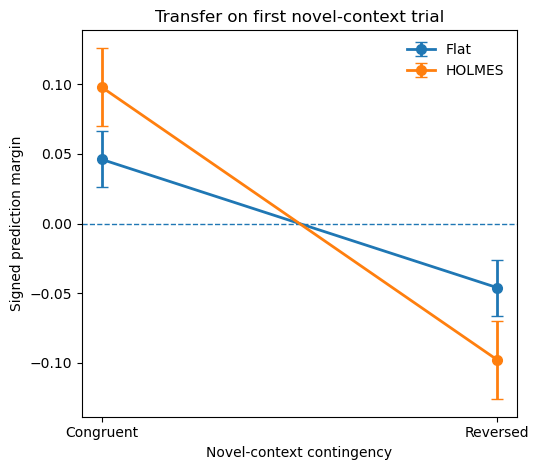

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats


# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------

def mean_ci95(x):
    """Mean and normal-approximation 95% CI across seeds."""
    x = np.asarray(pd.Series(x).dropna(), dtype=float)

    mean = np.mean(x)

    if len(x) < 2:
        return mean, np.nan

    sem = stats.sem(x)
    ci = 1.96 * sem

    return mean, ci


# ------------------------------------------------------------
# PANEL B: FIRST-TRIAL TRANSFER
# ------------------------------------------------------------

first = neg_df[
    neg_df["test_trial"] == 1
].copy()


# Seed-level means are already one observation per
# seed x condition x model, but group explicitly for safety.
first_seed = (
    first
    .groupby(
        ["seed", "condition", "model"],
        as_index=False
    )
    .agg(
        signed_margin=("signed_margin", "mean")
    )
)


# Summary for plotting
first_summary = (
    first_seed
    .groupby(["condition", "model"])
    ["signed_margin"]
    .agg(["mean", "sem", "count"])
    .reset_index()
)

first_summary["ci95"] = (
    1.96 * first_summary["sem"]
)

display(first_summary)


# ------------------------------------------------------------
# Interaction statistic
# ------------------------------------------------------------

wide = first_seed.pivot_table(
    index="seed",
    columns=["condition", "model"],
    values="signed_margin",
)


wide["congruent_holmes_minus_flat"] = (
    wide[("congruent", "holmes")]
    - wide[("congruent", "flat")]
)

wide["reversed_holmes_minus_flat"] = (
    wide[("reversed", "holmes")]
    - wide[("reversed", "flat")]
)

wide["interaction"] = (
    wide["congruent_holmes_minus_flat"]
    - wide["reversed_holmes_minus_flat"]
)


t_interaction, p_interaction = stats.ttest_1samp(
    wide["interaction"].dropna(),
    popmean=0
)

interaction_mean = wide["interaction"].mean()

print(
    f"Model x contingency interaction: "
    f"ΔΔ = {interaction_mean:+.3f}, "
    f"t = {t_interaction:.3f}, "
    f"p = {p_interaction:.4g}"
)


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

condition_order = ["congruent", "reversed"]
model_order = ["flat", "holmes"]

x = np.arange(len(condition_order))

fig, ax = plt.subplots(figsize=(5.5, 4.8))


for model in model_order:

    means = []
    cis = []

    for condition in condition_order:

        vals = first_seed.loc[
            (first_seed["condition"] == condition)
            & (first_seed["model"] == model),
            "signed_margin",
        ]

        mean, ci = mean_ci95(vals)

        means.append(mean)
        cis.append(ci)

    ax.errorbar(
        x,
        means,
        yerr=cis,
        marker="o",
        markersize=7,
        linewidth=2,
        capsize=4,
        label=("Flat" if model == "flat" else "HOLMES"),
    )


ax.axhline(
    0,
    linewidth=1,
    linestyle="--",
)

ax.set_xticks(x)
ax.set_xticklabels(
    ["Congruent", "Reversed"]
)

ax.set_ylabel(
    "Signed prediction margin"
)

ax.set_xlabel(
    "Novel-context contingency"
)

ax.set_title(
    "Transfer on first novel-context trial"
)

ax.legend(
    frameon=False
)

# # Optional explanatory text
# ylim = ax.get_ylim()

# ax.text(
#     -0.45,
#     ylim[1] * 0.88,
#     "Favors correct outcome",
#     fontsize=9,
# )

# ax.text(
#     -0.45,
#     ylim[0] * 0.88,
#     "Favors incorrect outcome",
#     fontsize=9,
# )

fig.tight_layout()

plt.show()

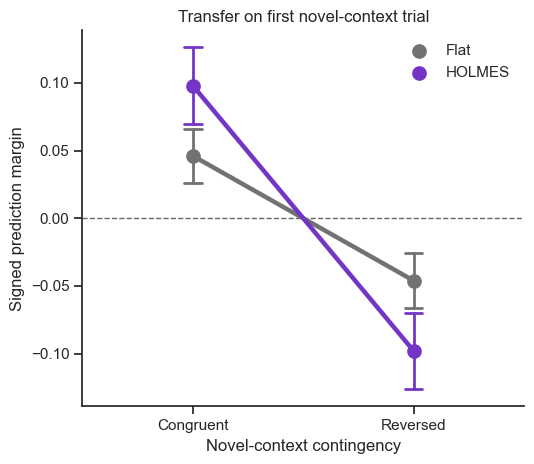

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

sns.set_theme(style="ticks", context="notebook")

condition_order = ["congruent", "reversed"]
model_order = ["flat", "holmes"]

# Okabe–Ito colors (colorblind-safe): blue / vermillion
palette = {"flat": "#727272", "holmes": "#7435c7"}


def ci_bounds(vals):
    """Wrap mean_ci95 so seaborn uses the same interval as before."""
    mean, ci = mean_ci95(vals)
    return mean - ci, mean + ci


fig, ax = plt.subplots(figsize=(5.5, 4.8))

sns.pointplot(
    data=first_seed,
    x="condition",
    y="signed_margin",
    hue="model",
    order=condition_order,
    hue_order=model_order,
    palette=palette,
    estimator="mean",
    errorbar=ci_bounds,
    dodge=0.0, 
    markers="o",
    scale=1.2,       # <--- Use 'scale' instead of 'linewidth' to adjust line & marker thickness
    capsize=0.08, 
    errwidth=2,      # <--- Use 'errwidth' instead of err_kws={"linewidth": 2} for older/stable seaborn versions
    ax=ax,
)


ax.axhline(0, color="0.4", linewidth=1, linestyle="--", zorder=0)

ax.set_xticks(range(len(condition_order)))
ax.set_xticklabels(["Congruent", "Reversed"])

ax.set_ylabel("Signed prediction margin")
ax.set_xlabel("Novel-context contingency")
ax.set_title("Transfer on first novel-context trial")

handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ["Flat", "HOLMES"], frameon=False, title=None)

sns.despine(ax=ax)
fig.tight_layout()

In [ ]:
first_wide = (
    first
    .pivot_table(
        index="seed",
        columns=["condition", "model"],
        values="signed_margin",
    )
)

first_wide["congruent_advantage"] = (
    first_wide[("congruent", "holmes")]
    - first_wide[("congruent", "flat")]
)

first_wide["reversed_advantage"] = (
    first_wide[("reversed", "holmes")]
    - first_wide[("reversed", "flat")]
)

first_wide["interaction"] = (
    first_wide["congruent_advantage"]
    - first_wide["reversed_advantage"]
)

from scipy import stats

t, p = stats.ttest_1samp(
    first_wide["interaction"],
    0.0,
)

print(
    f"interaction = {first_wide['interaction'].mean():+.4f}, "
    f"t={t:.3f}, p={p:.4g}"
)

interaction = +0.1039, t=2.648, p=0.01588


In [ ]:
reversed = neg_df[
    neg_df["condition"] == "reversed"
].copy()

recovery = (
    reversed
    .groupby(["model", "test_trial"])
    .agg(
        signed_margin=("signed_margin", "mean"),
        old_rule_margin=("old_rule_margin", "mean"),
        accuracy=("correct", "mean"),
        n=("seed", "nunique"),
    )
    .reset_index()
)

display(recovery)

,model,test_trial,signed_margin,old_rule_margin,accuracy,n
0,flat,1,-0.046127,0.046127,0.10,20
1,flat,2,-0.045567,0.045567,0.15,20
2,flat,3,-0.027250,0.027250,0.20,20
3,flat,4,-0.046206,0.046206,0.05,20
4,flat,5,-0.034305,0.034305,0.20,20
...,...,...,...,...,...,...
195,holmes,96,-0.001526,0.001526,0.45,20
196,holmes,97,0.008811,-0.008811,0.65,20
197,holmes,98,-0.008749,0.008749,0.40,20
198,holmes,99,-0.004996,0.004996,0.60,20


  model  test_trial      mean       sem  count      ci95
0  flat           1 -0.046127  0.010260     20  0.020109
1  flat           2 -0.045567  0.008808     20  0.017263
2  flat           3 -0.027250  0.009927     20  0.019457
3  flat           4 -0.046206  0.007046     20  0.013810
4  flat           5 -0.034305  0.009612     20  0.018839
      model  test_trial      mean       sem  count      ci95
195  holmes          96 -0.001526  0.010774     20  0.021118
196  holmes          97  0.008811  0.008275     20  0.016218
197  holmes          98 -0.008749  0.008859     20  0.017363
198  holmes          99 -0.004996  0.006616     20  0.012967
199  holmes         100 -0.008005  0.008624     20  0.016904


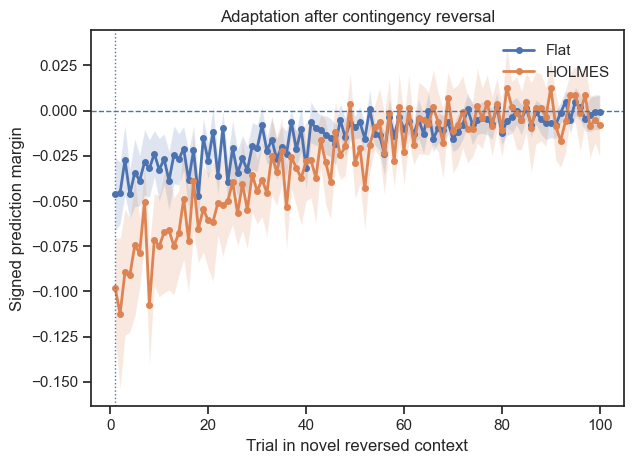

In [ ]:
# ------------------------------------------------------------
# PANEL C: REVERSAL TRAJECTORY
# ------------------------------------------------------------

rev = neg_df[
    neg_df["condition"] == "reversed"
].copy()


# One value per seed x model x test trial
rev_seed = (
    rev
    .groupby(
        ["seed", "model", "test_trial"],
        as_index=False
    )
    .agg(
        signed_margin=("signed_margin", "mean")
    )
)


# Mean and CI across seeds at each trial
rev_summary = (
    rev_seed
    .groupby(
        ["model", "test_trial"]
    )
    ["signed_margin"]
    .agg(["mean", "sem", "count"])
    .reset_index()
)

rev_summary["ci95"] = (
    1.96 * rev_summary["sem"]
)

print(rev_summary.head())
print(rev_summary.tail())


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(6.5, 4.8))


for model in ["flat", "holmes"]:

    g = (
        rev_summary[
            rev_summary["model"] == model
        ]
        .sort_values("test_trial")
    )

    label = (
        "Flat"
        if model == "flat"
        else "HOLMES"
    )

    ax.plot(
        g["test_trial"],
        g["mean"],
        marker="o",
        markersize=4,
        linewidth=2,
        label=label,
    )

    ax.fill_between(
        g["test_trial"],
        g["mean"] - g["ci95"],
        g["mean"] + g["ci95"],
        alpha=0.18,
    )


ax.axhline(
    0,
    linewidth=1,
    linestyle="--",
)

# Highlight the genuine zero-feedback transfer trial
ax.axvline(
    1,
    linewidth=1,
    linestyle=":",
)

ax.set_xlabel(
    "Trial in novel reversed context"
)

ax.set_ylabel(
    "Signed prediction margin"
)

ax.set_title(
    "Adaptation after contingency reversal"
)

ax.legend(
    frameon=False
)

fig.tight_layout()

plt.show()

In [ ]:
def summarize_transfer_recovery(
    df,
    late_n=20,
    sustained_n=5,
):
    """
    Summarize positive transfer, negative transfer,
    interaction, and recovery from reversal.
    """

    # --------------------------------------------------------
    # FIRST TEST TRIAL
    # --------------------------------------------------------

    first = (
        df[df["test_trial"] == 1]
        .groupby(
            ["seed", "condition", "model"],
            as_index=False,
        )
        .agg(
            signed_margin=("signed_margin", "mean")
        )
    )

    w = first.pivot_table(
        index="seed",
        columns=["condition", "model"],
        values="signed_margin",
    )

    required = [
        ("congruent", "flat"),
        ("congruent", "holmes"),
        ("reversed", "flat"),
        ("reversed", "holmes"),
    ]

    if not all(col in w.columns for col in required):
        raise ValueError(
            "Missing one or more condition/model cells."
        )

    # Helpful transfer
    positive_seed = (
        w[("congruent", "holmes")]
        - w[("congruent", "flat")]
    )

    # Harmful transfer
    negative_seed = (
        w[("reversed", "holmes")]
        - w[("reversed", "flat")]
    )

    # Difference-in-differences
    interaction_seed = (
        positive_seed
        - negative_seed
    )

    t_int, p_int = stats.ttest_1samp(
        interaction_seed.dropna(),
        popmean=0.0,
    )

    # --------------------------------------------------------
    # HOLMES REVERSAL TRAJECTORY
    # --------------------------------------------------------

    rev_h = df[
        (df["condition"] == "reversed")
        & (df["model"] == "holmes")
    ].copy()

    initial_seed = (
        rev_h[
            rev_h["test_trial"] == 1
        ]
        .set_index("seed")["signed_margin"]
    )

    max_trial = int(
        rev_h["test_trial"].max()
    )

    late_start = max(
        1,
        max_trial - late_n + 1,
    )

    late_seed = (
        rev_h[
            rev_h["test_trial"] >= late_start
        ]
        .groupby("seed")["signed_margin"]
        .mean()
    )

    common = (
        initial_seed.index
        .intersection(late_seed.index)
    )

    recovery_gain_seed = (
        late_seed.loc[common]
        - initial_seed.loc[common]
    )

    t_late, p_late = stats.ttest_1samp(
        late_seed.dropna(),
        popmean=0.0,
    )

    t_gain, p_gain = stats.ttest_1samp(
        recovery_gain_seed.dropna(),
        popmean=0.0,
    )

    # --------------------------------------------------------
    # FIRST SUSTAINED POSITIVE GROUP-MEAN PERIOD
    # --------------------------------------------------------

    trajectory = (
        rev_h
        .groupby("test_trial")["signed_margin"]
        .mean()
        .sort_index()
    )

    vals = trajectory.to_numpy()
    trials = trajectory.index.to_numpy()

    first_sustained_positive = np.nan

    for i in range(
        len(vals) - sustained_n + 1
    ):

        window = vals[
            i:i + sustained_n
        ]

        if np.all(window > 0):
            first_sustained_positive = int(
                trials[i]
            )
            break

    # --------------------------------------------------------
    # CI FOR LATE REVERSAL PERFORMANCE
    # --------------------------------------------------------

    late_mean = float(
        late_seed.mean()
    )

    late_sem = float(
        late_seed.sem()
    )

    late_ci95 = (
        1.96 * late_sem
        if np.isfinite(late_sem)
        else np.nan
    )

    return {
        "positive_transfer":
            float(positive_seed.mean()),

        "negative_transfer":
            float(negative_seed.mean()),

        "interaction":
            float(interaction_seed.mean()),

        "interaction_t":
            float(t_int),

        "interaction_p":
            float(p_int),

        "initial_reversal_margin":
            float(initial_seed.mean()),

        "late_reversal_margin":
            late_mean,

        "late_reversal_ci95":
            late_ci95,

        "late_reversal_t":
            float(t_late),

        "late_reversal_p":
            float(p_late),

        "recovery_gain":
            float(recovery_gain_seed.mean()),

        "recovery_gain_t":
            float(t_gain),

        "recovery_gain_p":
            float(p_gain),

        "first_sustained_positive_trial":
            first_sustained_positive,

        "n_seeds":
            int(w.shape[0]),

        "max_test_trial":
            max_trial,
    }

In [ ]:
def run_negative_transfer_configuration(
    *,
    alpha,
    omega,
    n_shape_copies,
    n_color_copies=1,
    train_reps=10,
    test_rounds=50,
    blocked_train=True,
    n_particles=75,
    seeds=range(10),
    max_depth=20,
    max_children=20,
    length_normalize=True,
    tau=1.0,
):

    cfg = NegativeTransferConfig(
        n_colors=10,
        n_train_colors=8,
        test_color=8,

        train_reps_per_stimulus=train_reps,

        # Each round contains the two shapes,
        # so 50 rounds = 100 test trials.
        test_rounds=test_rounds,

        n_shape_copies=n_shape_copies,
        n_color_copies=n_color_copies,
        n_nuisance_features=0,

        blocked_train_by_shape=blocked_train,
        shuffle_within_train_blocks=True,

        reward_rule="random_balanced",
    )

    rows = []

    for seed in seeds:
        if seed % 10 == 0:
            print(f"Running seed {seed}...")

        for condition in [
            "congruent",
            "reversed",
        ]:

            x = run_negative_transfer_seed(
                seed=seed,
                condition=condition,
                cfg=cfg,

                n_particles=n_particles,

                alpha=alpha,
                omega=omega,

                max_depth=max_depth,
                max_children=max_children,

                length_normalize=length_normalize,
                tau=tau,
            )

            rows.append(x)

    df = pd.concat(
        rows,
        ignore_index=True,
    )

    summary = summarize_transfer_recovery(
        df,
        late_n=20,
        sustained_n=5,
    )

    summary.update({
        "alpha": alpha,
        "omega": omega,
        "n_shape_copies": n_shape_copies,
        "n_color_copies": n_color_copies,
        "train_reps": train_reps,
        "test_rounds": test_rounds,
        "blocked_train": blocked_train,
        "n_particles": n_particles,
    })

    return summary, df

In [ ]:
from itertools import product


ALPHAS = [
    0.05,
    0.20,
    0.80,
]

OMEGAS = [
    0.05,
    0.20,
    0.80,
]


SHAPE_COPIES = [
    3,
    6,
    9,
]

TRAIN_REPS = [
    6,
    10,
]


grid = list(product(
    ALPHAS,
    OMEGAS,
    SHAPE_COPIES,
    TRAIN_REPS,
))

print(
    "Number of configurations:",
    len(grid)
)

Number of configurations: 54


In [ ]:
SCOUT_SEEDS = range(5)

search_rows = []

for i, (
    alpha,
    omega,
    shape_copies,
    train_reps,
) in enumerate(grid):

    if i % 10 == 0:
        print(
            f"{i}/{len(grid)}"
        )

    try:

        summary, _ = (
            run_negative_transfer_configuration(
                alpha=alpha,
                omega=omega,
                n_shape_copies=shape_copies,
                n_color_copies=1,

                train_reps=train_reps,

                # 50 rounds = 100 test trials
                test_rounds=50,

                blocked_train=True,

                # Cheap scouting settings
                n_particles=10,
                seeds=SCOUT_SEEDS,

                max_depth=5,
                max_children=5,

                length_normalize=True,
                tau=1.0,
            )
        )

        search_rows.append(
            summary
        )

    except Exception as e:

        print(
            "FAILED:",
            alpha,
            omega,
            shape_copies,
            train_reps,
            repr(e),
        )


search_df = pd.DataFrame(
    search_rows
)

display(
    search_df.head()
)

0/54
Running seed 0...
Running seed 0...
Running seed 0...


KeyboardInterrupt: 

In [ ]:
ALPHAS_FINE = [
    0.10,
    0.15,
    0.30,
    0.40,
]

OMEGAS_FINE = [
    0.05,
    0.10,
    0.15,
    0.20,
]

SHAPE_COPIES_FINE = [
    6,
    8,
    9,
    10,
]

TRAIN_REPS_FINE = [
    4,
    6,
    8,
]


FINE_SEEDS = range(20)
N_PARTICLES_FINE = 10
TEST_ROUNDS_FINE = 100   # 200 test trials

from itertools import product

fine_grid = list(product(
    ALPHAS_FINE,
    OMEGAS_FINE,
    SHAPE_COPIES_FINE,
    TRAIN_REPS_FINE,
))

print("Fine-grid configurations:", len(fine_grid))

fine_rows = []

for i, (
    alpha,
    omega,
    shape_copies,
    train_reps,
) in enumerate(fine_grid):

    if i % 20 == 0:
        print(f"{i}/{len(fine_grid)}")

    try:

        summary, _ = run_negative_transfer_configuration(
            alpha=alpha,
            omega=omega,

            n_shape_copies=shape_copies,
            n_color_copies=1,

            train_reps=train_reps,
            test_rounds=TEST_ROUNDS_FINE,

            blocked_train=True,

            n_particles=N_PARTICLES_FINE,
            seeds=FINE_SEEDS,

            max_depth=5,
            max_children=5,

            length_normalize=True,
            tau=1.0,
        )

        fine_rows.append(summary)

    except Exception as e:

        print(
            "FAILED:",
            alpha,
            omega,
            shape_copies,
            train_reps,
            repr(e),
        )

fine_df = pd.DataFrame(fine_rows)


In [ ]:
# Strong initial negative transfer
fine_df["has_negative_transfer"] = (
    (fine_df["positive_transfer"] > 0.02)
    & (fine_df["initial_reversal_margin"] < -0.02)
)

# At least essentially returns to neutral
fine_df["returns_to_neutral"] = (
    fine_df["late_reversal_margin"] > -0.005
)

# Actually learns the reversed contingency
fine_df["full_recovery"] = (
    fine_df["late_reversal_margin"] > 0.005
)

In [ ]:
cols = [
    "alpha",
    "omega",
    "n_shape_copies",
    "train_reps",

    "positive_transfer",
    "initial_reversal_margin",
    "late_reversal_margin",
    "recovery_gain",
    "first_sustained_positive_trial",
]

neutral_candidates = (
    fine_df[
        fine_df["has_negative_transfer"]
        & fine_df["returns_to_neutral"]
    ]
    .sort_values(
        ["late_reversal_margin", "positive_transfer"],
        ascending=False,
    )
)

display(neutral_candidates[cols].head(30))

In [ ]:
full_candidates = (
    fine_df[
        fine_df["has_negative_transfer"]
        & fine_df["full_recovery"]
    ]
    .sort_values(
        ["late_reversal_margin", "positive_transfer"],
        ascending=False,
    )
)

print(full_candidates[cols].head(10))

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats


# ============================================================
# STYLE
# ============================================================

FLAT_COLOR = "#595959"
HOLMES_COLOR = "#7561A8"

MODEL_COLORS = {
    "flat": FLAT_COLOR,
    "holmes": HOLMES_COLOR,
}

MODEL_LABELS = {
    "flat": "Flat",
    "holmes": "HOLMES",
}

TITLE_SIZE = 18
LABEL_SIZE = 16
TICK_SIZE = 11


def summarize_ci(df, group_cols, value_col):
    """
    Mean + 95% t CI across seeds.
    Assumes df has one row per seed within each requested group.
    """
    out = (
        df
        .groupby(group_cols)[value_col]
        .agg(["mean", "std", "count"])
        .reset_index()
    )

    out["sem"] = out["std"] / np.sqrt(out["count"])

    out["tcrit"] = out["count"].apply(
        lambda n: stats.t.ppf(0.975, n - 1)
        if n > 1 else np.nan
    )

    out["ci95"] = out["tcrit"] * out["sem"]

    return out

In [122]:
FINAL_CFG = dict(
    alpha=0.40,
    omega=0.05,

    n_shape_copies=10,
    n_color_copies=1,

    train_reps=4,
    test_rounds=100,   # 200 test trials

    blocked_train=True,

    n_particles=10,
    seeds=range(100, 200),   # completely new seeds

    max_depth=5,
    max_children=5,

    length_normalize=True,
    tau=1.0,
)

final_summary, final_df = run_negative_transfer_configuration(
    **FINAL_CFG
)

display(pd.DataFrame([final_summary]))

# ============================================================
# FIRST TEST TRIAL
# ============================================================

first_seed = (
    final_df[
        final_df["test_trial"] == 1
    ]
    .groupby(
        ["seed", "condition", "model"],
        as_index=False
    )
    .agg(
        signed_margin=("signed_margin", "mean")
    )
)

first_summary = summarize_ci(
    first_seed,
    ["condition", "model"],
    "signed_margin",
)

display(first_summary)


# ============================================================
# MODEL x CONDITION INTERACTION
# ============================================================

first_wide = first_seed.pivot_table(
    index="seed",
    columns=["condition", "model"],
    values="signed_margin",
)

first_wide["congruent_effect"] = (
    first_wide[("congruent", "holmes")]
    - first_wide[("congruent", "flat")]
)

first_wide["reversed_effect"] = (
    first_wide[("reversed", "holmes")]
    - first_wide[("reversed", "flat")]
)

first_wide["interaction"] = (
    first_wide["congruent_effect"]
    - first_wide["reversed_effect"]
)

t_inter, p_inter = stats.ttest_1samp(
    first_wide["interaction"].dropna(),
    popmean=0
)

print(
    f"Model x contingency interaction: "
    f"ΔΔ = {first_wide['interaction'].mean():+.3f}, "
    f"t({len(first_wide)-1}) = {t_inter:.3f}, "
    f"p = {p_inter:.4g}"
)


# ============================================================
# FIRST-TRIAL HOLMES REVERSAL TEST
# ============================================================

h_rev_first = first_wide[
    ("reversed", "holmes")
].dropna()

t_neg, p_neg_two = stats.ttest_1samp(
    h_rev_first,
    popmean=0
)

# directional test: expected < 0
p_neg = p_neg_two / 2 if t_neg < 0 else 1 - p_neg_two / 2

print(
    f"HOLMES reversed first trial: "
    f"M = {h_rev_first.mean():+.3f}, "
    f"t({len(h_rev_first)-1}) = {t_neg:.3f}, "
    f"one-sided p = {p_neg:.4g}"
)

Running seed 100...
Running seed 110...
Running seed 120...
Running seed 130...
Running seed 140...
Running seed 150...
Running seed 160...
Running seed 170...
Running seed 180...
Running seed 190...


,positive_transfer,negative_transfer,interaction,interaction_t,interaction_p,initial_reversal_margin,late_reversal_margin,late_reversal_ci95,late_reversal_t,late_reversal_p,...,n_seeds,max_test_trial,alpha,omega,n_shape_copies,n_color_copies,train_reps,test_rounds,blocked_train,n_particles
0,0.09588,-0.09588,0.191759,4.347382,0.000033,-0.127943,0.046375,0.008223,11.053799,5.583012e-19,...,100,200,0.4,0.05,10,1,4,100,True,10


,condition,model,mean,std,count,sem,tcrit,ci95
0,congruent,flat,0.032063,0.108766,100,0.010877,1.984217,0.021582
1,congruent,holmes,0.127943,0.177660,100,0.017766,1.984217,0.035252
2,reversed,flat,-0.032063,0.108766,100,0.010877,1.984217,0.021582
3,reversed,holmes,-0.127943,0.177660,100,0.017766,1.984217,0.035252


Model x contingency interaction: ΔΔ = +0.192, t(99) = 4.347, p = 3.345e-05
HOLMES reversed first trial: M = -0.128, t(99) = -7.202, one-sided p = 5.891e-11


In [123]:
# ============================================================
# REVERSAL RECOVERY BY TEST ROUND
# ============================================================

rev = final_df[
    final_df["condition"] == "reversed"
].copy()

# Average the two shape trials within each round for each seed
rev_round_seed = (
    rev
    .groupby(
        ["seed", "model", "test_round"],
        as_index=False
    )
    .agg(
        signed_margin=("signed_margin", "mean")
    )
)

rev_round_summary = summarize_ci(
    rev_round_seed,
    ["model", "test_round"],
    "signed_margin",
)

display(rev_round_summary.head())

,model,test_round,mean,std,count,sem,tcrit,ci95
0,flat,1,-0.046533,0.100149,100,0.010015,1.984217,0.019872
1,flat,2,-0.042399,0.058765,100,0.005876,1.984217,0.011660
2,flat,3,-0.053523,0.080899,100,0.008090,1.984217,0.016052
3,flat,4,-0.046664,0.064144,100,0.006414,1.984217,0.012728
4,flat,5,-0.045712,0.076008,100,0.007601,1.984217,0.015082


In [124]:
# ============================================================
# LATE-WINDOW RECOVERY TEST
# ============================================================

N_LATE_ROUNDS = 10

holmes_rev = rev_round_seed[
    rev_round_seed["model"] == "holmes"
].copy()

last_round = holmes_rev["test_round"].max()
late_start = last_round - N_LATE_ROUNDS + 1

late_seed = (
    holmes_rev[
        holmes_rev["test_round"] >= late_start
    ]
    .groupby("seed")["signed_margin"]
    .mean()
)

t_late, p_late_two = stats.ttest_1samp(
    late_seed,
    popmean=0
)

# directional test: expected > 0
p_late = (
    p_late_two / 2
    if t_late > 0
    else 1 - p_late_two / 2
)

print(
    f"Late HOLMES reversal margin "
    f"(last {N_LATE_ROUNDS} rounds): "
    f"M = {late_seed.mean():+.3f}, "
    f"t({len(late_seed)-1}) = {t_late:.3f}, "
    f"one-sided p = {p_late:.4g}"
)


# Paired first-to-late recovery
initial_seed = (
    rev[
        (rev["model"] == "holmes")
        & (rev["test_trial"] == 1)
    ]
    .set_index("seed")["signed_margin"]
)

common = initial_seed.index.intersection(
    late_seed.index
)

gain = (
    late_seed.loc[common]
    - initial_seed.loc[common]
)

t_gain, p_gain_two = stats.ttest_1samp(
    gain,
    popmean=0
)

p_gain = (
    p_gain_two / 2
    if t_gain > 0
    else 1 - p_gain_two / 2
)

print(
    f"First-to-late recovery: "
    f"Δ = {gain.mean():+.3f}, "
    f"t({len(gain)-1}) = {t_gain:.3f}, "
    f"one-sided p = {p_gain:.4g}"
)

Late HOLMES reversal margin (last 10 rounds): M = +0.046, t(99) = 11.054, one-sided p = 2.792e-19
First-to-late recovery: Δ = +0.174, t(99) = 8.947, one-sided p = 1.079e-14


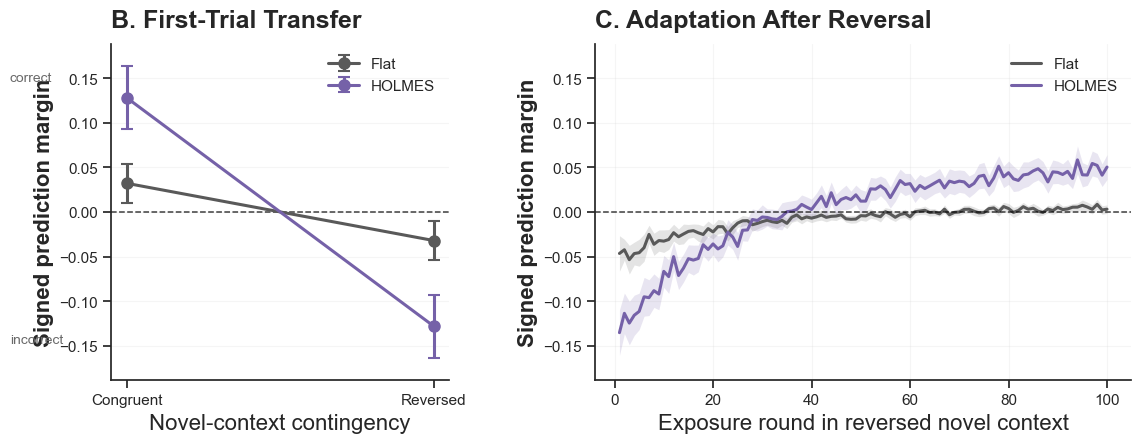

In [125]:
# ============================================================
# FIGURE: PANELS B AND C
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(11.5, 4.6),
    gridspec_kw={"width_ratios": [0.85, 1.35]}
)

axB, axC = axes


# ============================================================
# PANEL B
# ============================================================

condition_order = [
    "congruent",
    "reversed",
]

condition_labels = [
    "Congruent",
    "Reversed",
]

x = np.arange(
    len(condition_order)
)


for model in ["flat", "holmes"]:

    g = (
        first_summary[
            first_summary["model"] == model
        ]
        .set_index("condition")
        .loc[condition_order]
    )

    axB.errorbar(
        x,
        g["mean"],
        yerr=g["ci95"],
        marker="o",
        markersize=8,
        linewidth=2.2,
        capsize=4,
        capthick=1.5,
        color=MODEL_COLORS[model],
        label=MODEL_LABELS[model],
        zorder=3,
    )


axB.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1.1,
    alpha=0.75,
)

axB.set_xticks(x)
axB.set_xticklabels(
    condition_labels,
    fontsize=TICK_SIZE,
)

axB.set_ylabel(
    "Signed prediction margin",
    fontsize=LABEL_SIZE,
    fontweight="bold",
)

axB.set_xlabel(
    "Novel-context contingency",
    fontsize=LABEL_SIZE,
)

axB.set_title(
    "B. First-Trial Transfer",
    fontsize=TITLE_SIZE,
    fontweight="bold",
    loc="left",
    pad=12,
)

axB.legend(
    frameon=False,
    fontsize=11,
    loc="upper right",
)

axB.tick_params(
    axis="y",
    labelsize=TICK_SIZE,
)

axB.grid(
    axis="y",
    alpha=0.18,
    linewidth=0.8,
)

# Labels showing interpretation of signed margin
ymin, ymax = axB.get_ylim()

axB.text(
    -0.38,
    ymax * 0.82,
    "correct",
    fontsize=10,
    color="dimgray",
)

axB.text(
    -0.38,
    ymin * 0.82,
    "incorrect",
    fontsize=10,
    color="dimgray",
)


# ============================================================
# PANEL C
# ============================================================

for model in ["flat", "holmes"]:

    g = (
        rev_round_summary[
            rev_round_summary["model"] == model
        ]
        .sort_values("test_round")
    )

    axC.plot(
        g["test_round"],
        g["mean"],
        color=MODEL_COLORS[model],
        linewidth=2.2,
        label=MODEL_LABELS[model],
    )

    axC.fill_between(
        g["test_round"].to_numpy(),
        (
            g["mean"]
            - g["ci95"]
        ).to_numpy(),
        (
            g["mean"]
            + g["ci95"]
        ).to_numpy(),
        color=MODEL_COLORS[model],
        alpha=0.16,
        linewidth=0,
    )


axC.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1.1,
    alpha=0.75,
)

axC.set_xlabel(
    "Exposure round in reversed novel context",
    fontsize=LABEL_SIZE,
)

axC.set_ylabel(
    "Signed prediction margin",
    fontsize=LABEL_SIZE,
    fontweight="bold",
)

axC.set_title(
    "C. Adaptation After Reversal",
    fontsize=TITLE_SIZE,
    fontweight="bold",
    loc="left",
    pad=12,
)

axC.legend(
    frameon=False,
    fontsize=11,
    loc="best",
)

axC.tick_params(
    axis="both",
    labelsize=TICK_SIZE,
)

axC.grid(
    alpha=0.18,
    linewidth=0.8,
)


# ============================================================
# MATCH Y AXES ACROSS PANELS
# ============================================================

all_low = min(
    axB.get_ylim()[0],
    axC.get_ylim()[0],
)

all_high = max(
    axB.get_ylim()[1],
    axC.get_ylim()[1],
)

# Give symmetric limits around zero
lim = max(
    abs(all_low),
    abs(all_high),
) * 1.05

axB.set_ylim(
    -lim,
    lim,
)

axC.set_ylim(
    -lim,
    lim,
)


# Remove unnecessary borders
for ax in [axB, axC]:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


fig.tight_layout(
    w_pad=3.0
)

plt.show()

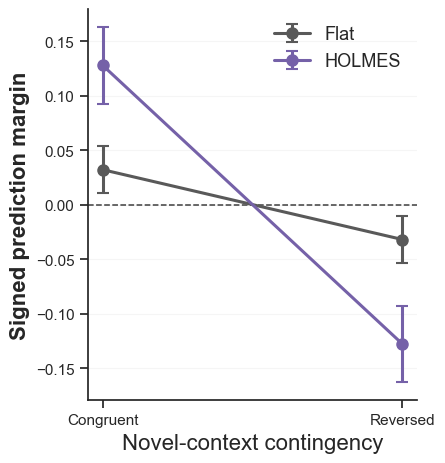

In [126]:
# ============================================================
# PANEL B: FIRST-TRIAL TRANSFER
# ============================================================

condition_order = [
    "congruent",
    "reversed",
]

condition_labels = [
    "Congruent",
    "Reversed",
]

#x = np.arange(len(condition_order))
x = np.array([0.2, 0.3])

figB, axB = plt.subplots(
    figsize=(4.6, 4.8)
)

for model in ["flat", "holmes"]:

    g = (
        first_summary[
            first_summary["model"] == model
        ]
        .set_index("condition")
        .loc[condition_order]
    )

    axB.errorbar(
        x,
        g["mean"],
        yerr=g["ci95"],
        marker="o",
        markersize=8,
        linewidth=2.2,
        capsize=4,
        capthick=1.5,
        color=MODEL_COLORS[model],
        label=MODEL_LABELS[model],
        zorder=3,
    )


# Decision boundary
axB.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1.1,
    alpha=0.75,
)

axB.set_xticks(x)
axB.set_xticklabels(
    condition_labels,
    fontsize=TICK_SIZE,
)

axB.set_ylabel(
    "Signed prediction margin",
    fontsize=LABEL_SIZE,
    fontweight="bold",
)

axB.set_xlabel(
    "Novel-context contingency",
    fontsize=LABEL_SIZE,
)

# axB.set_title(
#     "B. First-Trial Transfer",
#     fontsize=TITLE_SIZE,
#     fontweight="bold",
#     loc="left",
#     pad=12,
# )

axB.legend(
    frameon=False,
    fontsize=13,
    loc="upper right",
)

axB.tick_params(
    axis="both",
    labelsize=TICK_SIZE,
)

axB.grid(
    axis="y",
    alpha=0.18,
    linewidth=0.8,
)

# Remove unnecessary borders
axB.spines["top"].set_visible(False)
axB.spines["right"].set_visible(False)


# Optional labels explaining sign
ymin, ymax = axB.get_ylim()

# axB.text(
#     -0.38,
#     ymax * 0.82,
#     "correct",
#     fontsize=10,
#     color="dimgray",
# )

# axB.text(
#     -0.38,
#     ymin * 0.82,
#     "incorrect",
#     fontsize=10,
#     color="dimgray",
# )


figB.tight_layout()

plt.show()

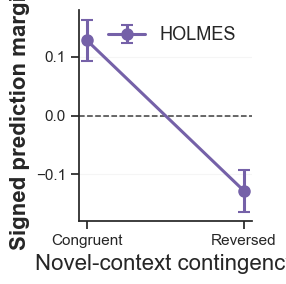

In [127]:
# ============================================================
# PANEL B: FIRST-TRIAL TRANSFER
# ============================================================

condition_order = [
    "congruent",
    "reversed",
]

condition_labels = [
    "Congruent",
    "Reversed",
]

#x = np.arange(len(condition_order))
x = np.array([0.2, 0.3])

figB, axB = plt.subplots(
    figsize=(3, 3)
)

for model in ["holmes"]:

    g = (
        first_summary[
            first_summary["model"] == model
        ]
        .set_index("condition")
        .loc[condition_order]
    )

    axB.errorbar(
        x,
        g["mean"],
        yerr=g["ci95"],
        marker="o",
        markersize=8,
        linewidth=2.2,
        capsize=4,
        capthick=1.5,
        color=MODEL_COLORS[model],
        label=MODEL_LABELS[model],
        zorder=3,
    )


# Decision boundary
axB.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1.1,
    alpha=0.75,
)

axB.set_xticks(x)
axB.set_xticklabels(
    condition_labels,
    fontsize=TICK_SIZE,
)

axB.set_ylabel(
    "Signed prediction margin",
    fontsize=LABEL_SIZE,
    fontweight="bold",
)

axB.set_xlabel(
    "Novel-context contingency",
    fontsize=LABEL_SIZE,
)

# axB.set_title(
#     "B. First-Trial Transfer",
#     fontsize=TITLE_SIZE,
#     fontweight="bold",
#     loc="left",
#     pad=12,
# )

axB.legend(
    frameon=False,
    fontsize=13,
    loc="upper right",
)

axB.tick_params(
    axis="both",
    labelsize=TICK_SIZE,
)

axB.grid(
    axis="y",
    alpha=0.18,
    linewidth=0.8,
)

# Remove unnecessary borders
axB.spines["top"].set_visible(False)
axB.spines["right"].set_visible(False)


# Optional labels explaining sign
ymin, ymax = axB.get_ylim()

# axB.text(
#     -0.38,
#     ymax * 0.82,
#     "correct",
#     fontsize=10,
#     color="dimgray",
# )

# axB.text(
#     -0.38,
#     ymin * 0.82,
#     "incorrect",
#     fontsize=10,
#     color="dimgray",
# )


figB.tight_layout()

plt.show()

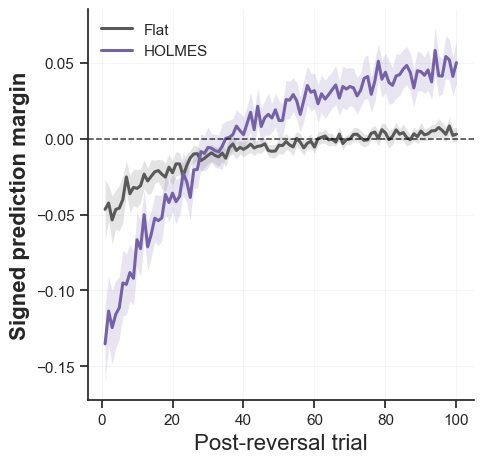

In [128]:
# ============================================================
# PANEL C: ADAPTATION AFTER REVERSAL
# ============================================================

figC, axC = plt.subplots(
    figsize=(5.0, 4.8)
)

for model in ["flat", "holmes"]:

    g = (
        rev_round_summary[
            rev_round_summary["model"] == model
        ]
        .sort_values("test_round")
    )

    axC.plot(
        g["test_round"],
        g["mean"],
        color=MODEL_COLORS[model],
        linewidth=2.2,
        label=MODEL_LABELS[model],
    )

    axC.fill_between(
        g["test_round"].to_numpy(),
        (
            g["mean"]
            - g["ci95"]
        ).to_numpy(),
        (
            g["mean"]
            + g["ci95"]
        ).to_numpy(),
        color=MODEL_COLORS[model],
        alpha=0.16,
        linewidth=0,
    )


# Decision boundary
axC.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1.1,
    alpha=0.75,
)

axC.set_xlabel(
    "Post-reversal trial",
    fontsize=LABEL_SIZE,
)

axC.set_ylabel(
    "Signed prediction margin",
    fontsize=LABEL_SIZE,
    fontweight="bold",
)

# axC.set_title(
#     "C. Adaptation After Reversal",
#     fontsize=TITLE_SIZE,
#     fontweight="bold",
#     loc="left",
#     pad=12,
# )

axC.legend(
    frameon=False,
    fontsize=11,
    loc="best",
)

axC.tick_params(
    axis="both",
    labelsize=TICK_SIZE,
)

axC.grid(
    alpha=0.18,
    linewidth=0.8,
)

# Remove unnecessary borders
axC.spines["top"].set_visible(False)
axC.spines["right"].set_visible(False)


figC.tight_layout()

plt.show()

In [129]:
# ============================================================
# PANEL B DATA: FIRST-TRIAL ACCURACY
# ============================================================

first_acc_seed = (
    final_df[final_df["test_trial"] == 1]
    .groupby(
        ["seed", "condition", "model"],
        as_index=False
    )
    .agg(
        accuracy=("correct", "mean")
    )
)

first_acc_summary = (
    first_acc_seed
    .groupby(["condition", "model"])["accuracy"]
    .agg(["mean", "std", "count"])
    .reset_index()
)

first_acc_summary["sem"] = (
    first_acc_summary["std"]
    / np.sqrt(first_acc_summary["count"])
)

first_acc_summary["tcrit"] = (
    first_acc_summary["count"]
    .apply(lambda n: stats.t.ppf(.975, n - 1))
)

first_acc_summary["ci95"] = (
    first_acc_summary["sem"]
    * first_acc_summary["tcrit"]
)

display(first_acc_summary)

,condition,model,mean,std,count,sem,tcrit,ci95
0,congruent,flat,0.57,0.497570,100,0.049757,1.984217,0.098729
1,congruent,holmes,0.78,0.416333,100,0.041633,1.984217,0.082610
2,reversed,flat,0.43,0.497570,100,0.049757,1.984217,0.098729
3,reversed,holmes,0.22,0.416333,100,0.041633,1.984217,0.082610


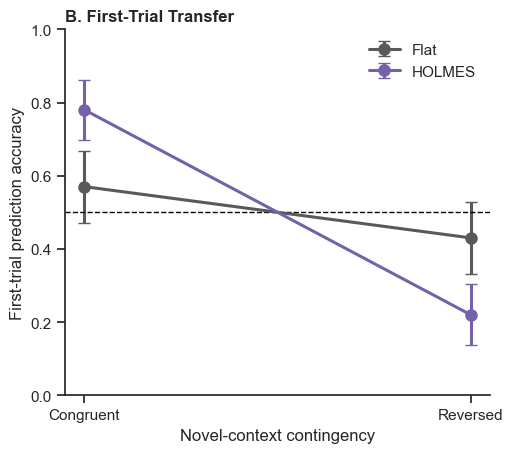

In [130]:
condition_order = ["congruent", "reversed"]
x = np.arange(2)

fig, ax = plt.subplots(figsize=(5.3, 4.7))

for model in ["flat", "holmes"]:

    g = (
        first_acc_summary[
            first_acc_summary["model"] == model
        ]
        .set_index("condition")
        .loc[condition_order]
    )

    ax.errorbar(
        x,
        g["mean"],
        yerr=g["ci95"],
        marker="o",
        markersize=8,
        linewidth=2.2,
        capsize=4,
        color=MODEL_COLORS[model],
        label=MODEL_LABELS[model],
    )

ax.axhline(
    .5,
    color="black",
    linestyle="--",
    linewidth=1,
)

ax.set_xticks(x)
ax.set_xticklabels(
    ["Congruent", "Reversed"]
)

ax.set_ylim(0, 1)

ax.set_ylabel(
    "First-trial prediction accuracy"
)

ax.set_xlabel(
    "Novel-context contingency"
)

ax.set_title(
    "B. First-Trial Transfer",
    loc="left",
    fontweight="bold",
)

ax.legend(frameon=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [131]:
# ============================================================
# PANEL C DATA: REVERSAL ACCURACY
# ============================================================

rev = final_df[
    final_df["condition"] == "reversed"
].copy()

rev_round_acc_seed = (
    rev
    .groupby(
        ["seed", "model", "test_round"],
        as_index=False
    )
    .agg(
        accuracy=("correct", "mean")
    )
)

rev_round_acc_summary = (
    rev_round_acc_seed
    .groupby(["model", "test_round"])["accuracy"]
    .agg(["mean", "std", "count"])
    .reset_index()
)

rev_round_acc_summary["sem"] = (
    rev_round_acc_summary["std"]
    / np.sqrt(rev_round_acc_summary["count"])
)

rev_round_acc_summary["tcrit"] = (
    rev_round_acc_summary["count"]
    .apply(lambda n: stats.t.ppf(.975, n - 1))
)

rev_round_acc_summary["ci95"] = (
    rev_round_acc_summary["sem"]
    * rev_round_acc_summary["tcrit"]
)

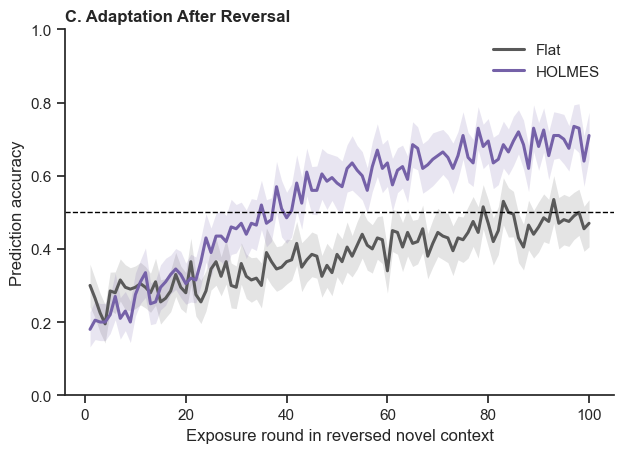

In [132]:
fig, ax = plt.subplots(figsize=(6.4, 4.7))

for model in ["flat", "holmes"]:

    g = (
        rev_round_acc_summary[
            rev_round_acc_summary["model"] == model
        ]
        .sort_values("test_round")
    )

    ax.plot(
        g["test_round"],
        g["mean"],
        linewidth=2.2,
        color=MODEL_COLORS[model],
        label=MODEL_LABELS[model],
    )

    ax.fill_between(
        g["test_round"],
        g["mean"] - g["ci95"],
        g["mean"] + g["ci95"],
        color=MODEL_COLORS[model],
        alpha=.16,
        linewidth=0,
    )

ax.axhline(
    .5,
    color="black",
    linestyle="--",
    linewidth=1,
)

ax.set_ylim(0, 1)

ax.set_xlabel(
    "Exposure round in reversed novel context"
)

ax.set_ylabel(
    "Prediction accuracy"
)

ax.set_title(
    "C. Adaptation After Reversal",
    loc="left",
    fontweight="bold",
)

ax.legend(frameon=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [133]:
# ============================================================
# MULTIPLE-REVERSAL / CONTINGENCY-SWITCHING TASK
#
# Design:
#
# Training:
#     A = original shape -> reward contingency
#
# Test in ONE novel color:
#     B1 = reversed contingency
#     A1 = original contingency restored
#     B2 = reversed again
#     A2 = original again
#     ...
#
# Every post-switch first prediction is made BEFORE feedback
# from the newly switched contingency.
#
# Requires:
#     import ablation_rule_task as rule_tps
#
# or whatever module name you currently use for:
#     rule_tps.one_layer_inference_loop
#     rule_tps.full_hier_inference_loop
# ============================================================


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from dataclasses import dataclass, asdict
from scipy import stats


# ============================================================
# CONFIGURATION
# ============================================================

@dataclass
class MultiReversalConfig:

    # Feature/task strcture
    n_colors: int = 6
    n_train_colors: int = 4
    test_color: int = 2

    # Training
    train_reps_per_stimulus: int = 4

    # Switching task
    #
    # n_switch_phases = 4 gives:
    #   B1 -> A1 -> B2 -> A2
    #
    # The first phase is always a reversal relative to training.
    n_switch_phases: int = 4

    # One round contains each of the two shapes once.
    # Therefore:
    #   60 rounds = 120 trials per contingency phase.
    rounds_per_phase: int = 50

    # Feature weighting
    n_shape_copies: int = 10
    n_color_copies: int = 1
    n_nuisance_features: int = 0

    # Training sequence
    blocked_train_by_shape: bool = True
    shuffle_within_train_blocks: bool = True

    # Randomize which of the two shapes is rewarded
    reward_rule: str = "random_balanced"


# ============================================================
# TASK GENERATOR
# ============================================================

def generate_multi_reversal_task(
    seed,
    cfg: MultiReversalConfig,
):
    """
    Generate an A-B-A-B... contingency switching task.

    A = original training rule
    B = exact reversal of training rule

    The SAME held-out color is used throughout every test phase.
    Thus the only thing that changes at phase boundaries is the
    outcome contingency.

    Returns
    -------
    F : array
        Feature matrix, shape (n_features, n_trials)

    meta : dict
        Trial metadata.

    feedback_mask : bool array
        Feedback available on all trials.
    """

    rng = np.random.default_rng(seed)

    assert (
        cfg.n_train_colors < cfg.n_colors
    )

    assert (
        cfg.test_color >= cfg.n_train_colors
    )

    assert (
        cfg.test_color < cfg.n_colors
    )

    # --------------------------------------------------------
    # BASIC FEATURE SPACE
    # --------------------------------------------------------

    n_shapes = 2

    train_colors = list(
        range(cfg.n_train_colors)
    )

    n_shape_feats = (
        cfg.n_shape_copies
        * n_shapes
    )

    n_color_feats = (
        cfg.n_color_copies
        * cfg.n_colors
    )

    n_nonoutcome = (
        n_shape_feats
        + n_color_feats
        + cfg.n_nuisance_features
    )

    outcome_idx = n_nonoutcome


    # --------------------------------------------------------
    # CHOOSE TRAINING RULE
    # --------------------------------------------------------

    if cfg.reward_rule == "shape0":

        rewarded_shape = 0

    elif cfg.reward_rule == "random_balanced":

        rewarded_shape = int(
            rng.integers(0, 2)
        )

    else:

        raise ValueError(
            "reward_rule must be "
            "'shape0' or 'random_balanced'"
        )


    # --------------------------------------------------------
    # OPTIONAL NUISANCE FEATURES
    # --------------------------------------------------------

    nuisance_by_color = {}

    if cfg.n_nuisance_features > 0:

        for color in range(
            cfg.n_colors
        ):

            nuisance_by_color[color] = (
                rng.integers(
                    0,
                    2,
                    size=cfg.n_nuisance_features,
                    dtype=int,
                )
            )


    # --------------------------------------------------------
    # FEATURE CONSTRUCTION
    # --------------------------------------------------------

    def make_features(
        shape,
        color,
    ):

        x = np.zeros(
            n_nonoutcome,
            dtype=int,
        )

        # Shape features
        for copy in range(
            cfg.n_shape_copies
        ):

            x[
                copy * n_shapes
                + shape
            ] = 1


        # Color features
        color_start = n_shape_feats

        for copy in range(
            cfg.n_color_copies
        ):

            x[
                color_start
                + copy * cfg.n_colors
                + color
            ] = 1


        # Optional nuisance features
        if (
            cfg.n_nuisance_features
            > 0
        ):

            x[
                n_shape_feats
                + n_color_feats:
            ] = nuisance_by_color[
                color
            ]

        return x


    # --------------------------------------------------------
    # CONTINGENCY FUNCTIONS
    # --------------------------------------------------------

    def original_rule(shape):
        """
        A contingency learned during training.
        """

        return int(
            shape == rewarded_shape
        )


    def reversed_rule(shape):
        """
        B contingency.
        """

        return (
            1
            - original_rule(shape)
        )


    # ========================================================
    # TRAINING PHASE
    # ========================================================

    train_trials = []

    for shape in [0, 1]:

        for color in train_colors:

            for rep in range(
                cfg.train_reps_per_stimulus
            ):

                train_trials.append({

                    "phase_type":
                        "training",

                    "phase_index":
                        0,

                    "phase_label":
                        "Training A",

                    "contingency":
                        "original",

                    "previous_contingency":
                        None,

                    "shape":
                        shape,

                    "color":
                        color,

                    "phase_trial":
                        0,

                    "phase_round":
                        0,

                    "global_test_trial":
                        0,

                    "is_first_after_switch":
                        False,

                    "training_rule_reward":
                        original_rule(shape),

                    "reward":
                        original_rule(shape),

                    "features":
                        make_features(
                            shape,
                            color,
                        ),
                })


    # --------------------------------------------------------
    # ORDER TRAINING
    # --------------------------------------------------------

    if cfg.blocked_train_by_shape:

        blocks = []

        for shape in [0, 1]:

            block = [
                tr
                for tr
                in train_trials
                if tr["shape"] == shape
            ]

            if (
                cfg.shuffle_within_train_blocks
            ):

                rng.shuffle(
                    block
                )

            blocks.append(
                block
            )


        if rng.random() < 0.5:

            train_trials = (
                blocks[0]
                + blocks[1]
            )

        else:

            train_trials = (
                blocks[1]
                + blocks[0]
            )

    else:

        rng.shuffle(
            train_trials
        )


    # ========================================================
    # MULTIPLE SWITCH PHASES
    # ========================================================

    switch_trials = []

    global_test_trial = 0

    previous_contingency = (
        "original"
    )


    for phase_index in range(
        1,
        cfg.n_switch_phases + 1,
    ):

        # Odd phases = reversed B
        # Even phases = restored original A

        if phase_index % 2 == 1:

            contingency = (
                "reversed"
            )

            phase_rule = (
                reversed_rule
            )

            phase_label = (
                f"B{(phase_index + 1) // 2}"
            )

        else:

            contingency = (
                "original"
            )

            phase_rule = (
                original_rule
            )

            phase_label = (
                f"A{phase_index // 2}"
            )


        phase_trial = 0


        for phase_round in range(
            1,
            cfg.rounds_per_phase + 1,
        ):

            # Present each shape once per round,
            # but randomize within-round order.

            shapes = [0, 1]

            rng.shuffle(
                shapes
            )


            for shape in shapes:

                phase_trial += 1
                global_test_trial += 1


                switch_trials.append({

                    "phase_type":
                        "switch",

                    "phase_index":
                        phase_index,

                    "phase_label":
                        phase_label,

                    "contingency":
                        contingency,

                    "previous_contingency":
                        previous_contingency,

                    "shape":
                        shape,

                    "color":
                        cfg.test_color,

                    "phase_trial":
                        phase_trial,

                    "phase_round":
                        phase_round,

                    "global_test_trial":
                        global_test_trial,

                    "is_first_after_switch":
                        phase_trial == 1,

                    # Outcome predicted by original
                    # training rule
                    "training_rule_reward":
                        original_rule(shape),

                    # Current true outcome
                    "reward":
                        phase_rule(shape),

                    "features":
                        make_features(
                            shape,
                            cfg.test_color,
                        ),
                })


        previous_contingency = (
            contingency
        )


    # ========================================================
    # COMBINE TRIALS
    # ========================================================

    trials = (
        train_trials
        + switch_trials
    )

    F = np.zeros(
        (
            n_nonoutcome + 1,
            len(trials),
        ),
        dtype=int,
    )


    for t, tr in enumerate(
        trials
    ):

        F[
            :n_nonoutcome,
            t
        ] = tr["features"]

        F[
            outcome_idx,
            t
        ] = tr["reward"]


    # Full feedback after every trial.
    #
    # Importantly, prediction is generated
    # BEFORE current-trial feedback in both
    # inference loops.

    feedback_mask = (
        np.ones_like(
            F,
            dtype=bool,
        )
    )


    meta = {

        "task_type":
            "multi_reversal_shape_color",

        "seed":
            seed,

        "config":
            asdict(cfg),

        "rewarded_shape":
            rewarded_shape,

        "train_colors":
            train_colors,

        "test_color":
            cfg.test_color,

        "n_train_trials":
            len(train_trials),

        "n_switch_trials":
            len(switch_trials),

        "n_trials":
            len(trials),

        "outcome_idx":
            outcome_idx,

        "n_nonoutcome":
            n_nonoutcome,

        "trials": [
            {
                k: v
                for k, v
                in tr.items()
                if k != "features"
            }
            for tr in trials
        ],
    }


    return (
        F,
        meta,
        feedback_mask,
    )


# ============================================================
# RUN ONE SEED
# ============================================================

def run_multi_reversal_seed(
    seed,
    cfg,
    *,
    n_particles=10,
    alpha=0.40,
    omega=0.05,
    hier_stickiness=None,
    max_depth=20,
    max_children=20,
    length_normalize=False,
    tau=1.0,
):
    """
    Run Flat and HOLMES on one complete
    multi-reversal task.

    Returns a long trial-level dataframe.
    """

    if hier_stickiness is None:

        hier_stickiness = omega


    # --------------------------------------------------------
    # TASK
    # --------------------------------------------------------

    F, meta, fb = (
        generate_multi_reversal_task(
            seed,
            cfg,
        )
    )

    oi = int(
        meta["outcome_idx"]
    )

    trials = (
        meta["trials"]
    )


    # ========================================================
    # FLAT MODEL
    # ========================================================

    (
        flat_particles,
        _,
        r_flat,
        _,
    ) = rule_tps.one_layer_inference_loop(

        nTrials=
            F.shape[1],

        nParticles=
            n_particles,

        nFeatures=
            F.shape[0],

        regime=
            omega,

        alpha=
            alpha,

        f=
            F,

        outcome_idx_per_trial=
            np.full(
                F.shape[1],
                oi,
                dtype=int,
            ),

        feedback_mask=
            fb[oi, :],

        random_seed=
            seed,

        length_normalize=
            length_normalize,

        tau=
            tau,

        stickiness=
            0.0,
    )


    # ========================================================
    # HOLMES
    # ========================================================

    hier_out = (
        rule_tps.full_hier_inference_loop(

            nTrials=
                F.shape[1],

            nParticles=
                n_particles,

            nFeatures=
                F.shape[0],

            alpha=
                alpha,

            omega=
                omega,

            f=
                F,

            max_depth=
                max_depth,

            max_children=
                max_children,

            outcome_idx=
                oi,

            feedback_mask=
                fb,

            random_seed=
                seed,

            length_normalize=
                length_normalize,

            tau=
                tau,

            stickiness=
                hier_stickiness,

            use_stopping=
                True,
        )
    )

    r_holmes = (
        hier_out[2]
    )


    # ========================================================
    # BUILD LONG DATAFRAME
    # ========================================================

    rows = []


    for model, pred in [

        ("flat", r_flat),

        ("holmes", r_holmes),

    ]:

        for t, tr in enumerate(
            trials
        ):


            y = int(
                tr["reward"]
            )

            y_training = int(
                tr[
                    "training_rule_reward"
                ]
            )

            p = float(
                pred[t]
            )


            # ------------------------------------------------
            # ACCURACY
            # ------------------------------------------------

            predicted_reward = int(
                p > 0.5
            )

            correct = float(
                predicted_reward == y
            )


            # ------------------------------------------------
            # SIGNED MARGIN RELATIVE TO CURRENT CONTINGENCY
            #
            # +1 = maximally confident correct
            #  0 = decision boundary
            # -1 = maximally confident incorrect
            # ------------------------------------------------

            signed_margin = (
                (2 * y - 1)
                * (2 * p - 1)
            )


            # ------------------------------------------------
            # MARGIN RELATIVE TO ORIGINAL TRAINING RULE
            #
            # Useful for seeing whether the model
            # currently favors its original abstraction.
            # ------------------------------------------------

            training_rule_margin = (
                (2 * y_training - 1)
                * (2 * p - 1)
            )


            rows.append({

                "seed":
                    seed,

                "model":
                    model,

                "phase_index":
                    int(
                        tr[
                            "phase_index"
                        ]
                    ),

                "phase_label":
                    tr[
                        "phase_label"
                    ],

                "contingency":
                    tr[
                        "contingency"
                    ],

                "previous_contingency":
                    tr[
                        "previous_contingency"
                    ],

                "switch_direction":
                    (
                        "acquisition"
                        if tr["phase_type"] == "training"
                        else (
                            f"{tr['previous_contingency']}"
                            f"→{tr['contingency']}"
                        )
                    ),

                "phase_trial":
                    int(
                        tr[
                            "phase_trial"
                        ]
                    ),

                "phase_round":
                    int(
                        tr[
                            "phase_round"
                        ]
                    ),

                "global_test_trial":
                    int(
                        tr[
                            "global_test_trial"
                        ]
                    ),

                "is_first_after_switch":
                    bool(
                        tr[
                            "is_first_after_switch"
                        ]
                    ),

                "shape":
                    int(
                        tr[
                            "shape"
                        ]
                    ),

                "true_reward":
                    y,

                "training_rule_reward":
                    y_training,

                "p_reward":
                    p,

                "predicted_reward":
                    predicted_reward,

                "correct":
                    correct,

                "signed_margin":
                    signed_margin,

                "training_rule_margin":
                    training_rule_margin,

                "phase_type":
                    tr["phase_type"],

                "global_trial":
                    int(t + 1),

                "is_acquisition":
                    tr["phase_type"] == "training",
            })
    


    return pd.DataFrame(
        rows
    )


# ============================================================
# RUN MANY SEEDS
# ============================================================

def run_multi_reversal_experiment(
    seeds,
    cfg,
    *,
    n_particles=10,
    alpha=0.40,
    omega=0.05,
    hier_stickiness=None,
    max_depth=20,
    max_children=20,
    length_normalize=True,
    tau=1.0,
):
    """
    Run the complete switching experiment
    across seeds.
    """

    all_rows = []

    seeds = list(
        seeds
    )


    for i, seed in enumerate(
        seeds
    ):

        if i % 10 == 0:

            print(
                f"{i}/{len(seeds)} "
                f"(seed={seed})"
            )


        df_seed = (
            run_multi_reversal_seed(

                seed=seed,

                cfg=cfg,

                n_particles=
                    n_particles,

                alpha=
                    alpha,

                omega=
                    omega,

                hier_stickiness=
                    hier_stickiness,

                max_depth=
                    max_depth,

                max_children=
                    max_children,

                length_normalize=
                    length_normalize,

                tau=
                    tau,
            )
        )


        all_rows.append(
            df_seed
        )


    return pd.concat(
        all_rows,
        ignore_index=True,
    )


# ============================================================
# CONFIDENCE INTERVAL HELPER
# ============================================================

def summarize_ci(
    df,
    group_cols,
    value_col,
):
    """
    Mean and t-based 95% CI.
    """

    out = (
        df
        .groupby(
            group_cols
        )[value_col]
        .agg(
            [
                "mean",
                "std",
                "count",
            ]
        )
        .reset_index()
    )


    out["sem"] = (
        out["std"]
        / np.sqrt(
            out["count"]
        )
    )


    out["tcrit"] = (
        out["count"]
        .apply(
            lambda n:
                stats.t.ppf(
                    0.975,
                    n - 1,
                )
                if n > 1
                else np.nan
        )
    )


    out["ci95"] = (
        out["sem"]
        * out["tcrit"]
    )


    return out


# ============================================================
# ANALYSIS
# ============================================================

def analyze_multi_reversal(
    df,
    late_rounds=10,
    sustained_rounds=5,
):
    """
    Produce:
        1. first-trial summaries after each switch
        2. round-by-round trajectories
        3. late-phase summaries
        4. first-to-late recovery
        5. group-level first sustained positive round
    """

    # ========================================================
    # FIRST TRIAL AFTER EACH SWITCH
    # ========================================================

    # The long dataframe now also contains initial acquisition.
# The analyses below concern contingency-switch phases only.
    df = df[
        df["phase_type"] == "switch"].copy()
    
    first = (
        df[
            df[
                "is_first_after_switch"
            ]
        ]
        .copy()
    )


    first_summary = (
        summarize_ci(
            first,
            [
                "phase_index",
                "phase_label",
                "contingency",
                "switch_direction",
                "model",
            ],
            "signed_margin",
        )
    )


    first_accuracy_summary = (
        summarize_ci(
            first,
            [
                "phase_index",
                "phase_label",
                "contingency",
                "switch_direction",
                "model",
            ],
            "correct",
        )
    )


    # ========================================================
    # ROUND-BY-ROUND TRAJECTORY
    #
    # Average the two shape presentations
    # within each round for each seed first.
    # ========================================================

    round_seed = (
        df
        .groupby(
            [
                "seed",
                "model",
                "phase_index",
                "phase_label",
                "contingency",
                "phase_round",
            ],
            as_index=False,
        )
        .agg(

            signed_margin=
                (
                    "signed_margin",
                    "mean",
                ),

            accuracy=
                (
                    "correct",
                    "mean",
                ),

            training_rule_margin=
                (
                    "training_rule_margin",
                    "mean",
                ),
        )
    )


    round_margin_summary = (
        summarize_ci(
            round_seed,
            [
                "model",
                "phase_index",
                "phase_label",
                "contingency",
                "phase_round",
            ],
            "signed_margin",
        )
    )


    round_accuracy_summary = (
        summarize_ci(
            round_seed,
            [
                "model",
                "phase_index",
                "phase_label",
                "contingency",
                "phase_round",
            ],
            "accuracy",
        )
    )


    # ========================================================
    # LATE-PHASE PERFORMANCE
    # ========================================================

    max_round_by_phase = (
        round_seed
        .groupby(
            "phase_index"
        )["phase_round"]
        .max()
        .to_dict()
    )


    late_parts = []


    for phase_index, max_round in (
        max_round_by_phase.items()
    ):

        late_start = max(
            1,
            max_round
            - late_rounds
            + 1,
        )


        part = (
            round_seed[
                (
                    round_seed[
                        "phase_index"
                    ]
                    == phase_index
                )
                &
                (
                    round_seed[
                        "phase_round"
                    ]
                    >= late_start
                )
            ]
            .groupby(
                [
                    "seed",
                    "model",
                    "phase_index",
                    "phase_label",
                    "contingency",
                ],
                as_index=False,
            )
            .agg(

                late_margin=
                    (
                        "signed_margin",
                        "mean",
                    ),

                late_accuracy=
                    (
                        "accuracy",
                        "mean",
                    ),
            )
        )


        late_parts.append(
            part
        )


    late_seed = pd.concat(
        late_parts,
        ignore_index=True,
    )


    late_margin_summary = (
        summarize_ci(
            late_seed,
            [
                "phase_index",
                "phase_label",
                "contingency",
                "model",
            ],
            "late_margin",
        )
    )


    late_accuracy_summary = (
        summarize_ci(
            late_seed,
            [
                "phase_index",
                "phase_label",
                "contingency",
                "model",
            ],
            "late_accuracy",
        )
    )


    # ========================================================
    # FIRST -> LATE RECOVERY
    # ========================================================

    first_seed = (
        first[
            [
                "seed",
                "model",
                "phase_index",
                "phase_label",
                "contingency",
                "signed_margin",
                "correct",
            ]
        ]
        .rename(
            columns={
                "signed_margin":
                    "first_margin",

                "correct":
                    "first_accuracy",
            }
        )
    )


    gain_seed = (
        first_seed.merge(

            late_seed,

            on=[
                "seed",
                "model",
                "phase_index",
                "phase_label",
                "contingency",
            ],

            how="inner",
        )
    )


    gain_seed[
        "recovery_gain"
    ] = (
        gain_seed[
            "late_margin"
        ]
        - gain_seed[
            "first_margin"
        ]
    )


    gain_seed[
        "accuracy_gain"
    ] = (
        gain_seed[
            "late_accuracy"
        ]
        - gain_seed[
            "first_accuracy"
        ]
    )


    recovery_summary = (
        summarize_ci(
            gain_seed,
            [
                "phase_index",
                "phase_label",
                "contingency",
                "model",
            ],
            "recovery_gain",
        )
    )


    # ========================================================
    # FIRST SUSTAINED POSITIVE ROUND
    #
    # Group-mean criterion:
    # signed margin > 0 for sustained_rounds
    # consecutive rounds.
    # ========================================================

    crossing_rows = []


    for (
        phase_index,
        model
    ), g in (

        round_margin_summary
        .groupby(
            [
                "phase_index",
                "model",
            ]
        )

    ):

        g = g.sort_values(
            "phase_round"
        )


        values = (
            g["mean"]
            .to_numpy()
        )

        rounds = (
            g["phase_round"]
            .to_numpy()
        )


        first_sustained = (
            np.nan
        )


        for i in range(
            len(values)
            - sustained_rounds
            + 1
        ):

            window = values[
                i:
                i + sustained_rounds
            ]


            if np.all(
                window > 0
            ):

                first_sustained = int(
                    rounds[i]
                )

                break


        crossing_rows.append({

            "phase_index":
                phase_index,

            "model":
                model,

            "first_sustained_positive_round":
                first_sustained,
        })


    crossing_df = pd.DataFrame(
        crossing_rows
    )


    return {

        "first_trial":
            first,

        "first_margin_summary":
            first_summary,

        "first_accuracy_summary":
            first_accuracy_summary,

        "round_seed":
            round_seed,

        "round_margin_summary":
            round_margin_summary,

        "round_accuracy_summary":
            round_accuracy_summary,

        "late_seed":
            late_seed,

        "late_margin_summary":
            late_margin_summary,

        "late_accuracy_summary":
            late_accuracy_summary,

        "gain_seed":
            gain_seed,

        "recovery_summary":
            recovery_summary,

        "crossing":
            crossing_df,
    }


# ============================================================
# OPTIONAL PAIRED FIRST-TRIAL MODEL CONTRASTS
# ============================================================

def first_trial_model_contrasts(
    analysis,
):
    """
    HOLMES - Flat difference in first-trial
    signed margin for every switch phase.
    """

    first = (
        analysis[
            "first_trial"
        ]
    )


    wide = (
        first
        .pivot_table(

            index=[
                "seed",
                "phase_index",
                "phase_label",
                "contingency",
            ],

            columns="model",

            values="signed_margin",
        )
        .reset_index()
    )


    wide[
        "holmes_minus_flat"
    ] = (
        wide["holmes"]
        - wide["flat"]
    )


    rows = []


    for (
        phase_index,
        phase_label,
        contingency
    ), g in (

        wide.groupby(
            [
                "phase_index",
                "phase_label",
                "contingency",
            ]
        )

    ):

        x = (
            g[
                "holmes_minus_flat"
            ]
            .dropna()
        )


        mean = float(
            x.mean()
        )

        sem = float(
            x.sem()
        )


        ci = (
            stats.t.ppf(
                0.975,
                len(x) - 1,
            )
            * sem
            if len(x) > 1
            else np.nan
        )


        rows.append({

            "phase_index":
                phase_index,

            "phase_label":
                phase_label,

            "contingency":
                contingency,

            "holmes_minus_flat":
                mean,

            "ci95":
                ci,

            "n":
                len(x),
        })


    return pd.DataFrame(
        rows
    )


# ============================================================
# PLOTTING STYLE
# ============================================================

FLAT_COLOR = "#595959"
HOLMES_COLOR = "#7561A8"

MODEL_COLORS = {
    "flat": FLAT_COLOR,
    "holmes": HOLMES_COLOR,
}

MODEL_LABELS = {
    "flat": "Flat",
    "holmes": "HOLMES",
}

# ============================================================
# PLOT:
# INITIAL ACQUISITION + ALL CONTINGENCY SWITCHES
# ============================================================

def plot_acquisition_and_switches(
    df,
    metric="signed_margin",
    figsize=(11, 4.8),
    smooth_window=None,
    show_flat=True,
):
    """
    Plot initial acquisition followed continuously by
    B1 -> A1 -> B2 -> A2 ... switching phases.

    Uses actual trial number on the x-axis because the
    acquisition phase and reversal phases have different
    natural round structures.

    Parameters
    ----------
    df :
        Long dataframe returned by run_multi_reversal_experiment(),
        INCLUDING training trials.

    metric :
        "signed_margin" or "correct".

    smooth_window :
        Optional integer rolling-window size applied AFTER
        averaging across seeds. None = plot raw trial means.

    show_flat :
        If False, show HOLMES only.
    """

    if metric not in [
        "signed_margin",
        "correct",
    ]:
        raise ValueError(
            "metric must be "
            "'signed_margin' or 'correct'"
        )


    # ========================================================
    # ONE OBSERVATION PER SEED x MODEL x GLOBAL TRIAL
    # ========================================================

    trial_seed = (
        df
        .groupby(
            [
                "seed",
                "model",
                "global_trial",
                "phase_index",
                "phase_label",
                "phase_type",
                "contingency",
            ],
            as_index=False,
        )
        .agg(
            value=(
                metric,
                "mean",
            )
        )
    )


    # ========================================================
    # SUMMARY ACROSS SEEDS
    # ========================================================

    summary = summarize_ci(
        trial_seed,
        [
            "model",
            "global_trial",
            "phase_index",
            "phase_label",
            "phase_type",
            "contingency",
        ],
        "value",
    )


    # ========================================================
    # OPTIONAL SMOOTHING
    #
    # Important: smoothing is done separately within phases
    # so it cannot blur across contingency switches.
    # ========================================================

    if smooth_window is not None:

        smoothed_parts = []

        for (
            model,
            phase_index
        ), g in summary.groupby(
            [
                "model",
                "phase_index",
            ]
        ):

            g = g.sort_values(
                "global_trial"
            ).copy()

            g["plot_mean"] = (
                g["mean"]
                .rolling(
                    smooth_window,
                    center=False,
                    min_periods=1,
                )
                .mean()
            )

            g["plot_ci"] = (
                g["ci95"]
                .rolling(
                    smooth_window,
                    center=False,
                    min_periods=1,
                )
                .mean()
            )

            smoothed_parts.append(g)

        plot_summary = pd.concat(
            smoothed_parts,
            ignore_index=True,
        )

    else:

        plot_summary = summary.copy()

        plot_summary["plot_mean"] = (
            plot_summary["mean"]
        )

        plot_summary["plot_ci"] = (
            plot_summary["ci95"]
        )


    # ========================================================
    # DETERMINE PHASE BOUNDARIES
    # ========================================================

    phase_meta = (
        plot_summary[
            [
                "phase_index",
                "phase_label",
                "phase_type",
                "contingency",
                "global_trial",
            ]
        ]
        .drop_duplicates()
    )

    phase_ranges = (
        phase_meta
        .groupby(
            [
                "phase_index",
                "phase_label",
                "phase_type",
                "contingency",
            ],
            as_index=False,
        )
        .agg(
            xmin=(
                "global_trial",
                "min",
            ),

            xmax=(
                "global_trial",
                "max",
            ),
        )
        .sort_values(
            "phase_index"
        )
    )


    # ========================================================
    # DRAW
    # ========================================================

    fig, ax = plt.subplots(
        figsize=figsize
    )


    # --------------------------------------------------------
    # Phase backgrounds
    # --------------------------------------------------------

    for _, phase in phase_ranges.iterrows():

        xmin = (
            phase["xmin"]
            - 0.5
        )

        xmax = (
            phase["xmax"]
            + 0.5
        )


        if (
            phase["phase_type"]
            == "training"
        ):

            facecolor = "#E8E8E8"

            label = "Acquisition"

        elif (
            phase["contingency"]
            == "reversed"
        ):

            facecolor = "#F7E5E2"

            label = phase[
                "phase_label"
            ]

        else:

            facecolor = "#E5F2EA"

            label = phase[
                "phase_label"
            ]


        ax.axvspan(
            xmin,
            xmax,
            color=facecolor,
            alpha=0.35,
            linewidth=0,
            zorder=0,
        )


        ax.text(
            (
                xmin + xmax
            ) / 2,
            0.98,
            label,
            transform=
                ax.get_xaxis_transform(),
            ha="center",
            va="top",
            fontsize=10,
            fontweight="bold",
        )


    # --------------------------------------------------------
    # Vertical switch boundaries
    # --------------------------------------------------------

    starts = (
        phase_ranges[
            "xmin"
        ]
        .to_numpy()
    )

    for start in starts[1:]:

        ax.axvline(
            start - 0.5,
            color="black",
            linestyle=":",
            linewidth=1,
            alpha=0.6,
        )


    # --------------------------------------------------------
    # Model curves
    # --------------------------------------------------------

    models = (
        ["flat", "holmes"]
        if show_flat
        else ["holmes"]
    )


    for model in models:

        g = (
            plot_summary[
                plot_summary[
                    "model"
                ]
                == model
            ]
            .sort_values(
                "global_trial"
            )
        )


        # Plot each phase separately so lines do not
        # misleadingly interpolate across a switch.
        for phase_index, gp in g.groupby(
            "phase_index"
        ):

            gp = gp.sort_values(
                "global_trial"
            )

            ax.plot(
                gp[
                    "global_trial"
                ],
                gp[
                    "plot_mean"
                ],
                color=
                    MODEL_COLORS[
                        model
                    ],
                linewidth=2.2,
                label=(
                    MODEL_LABELS[
                        model
                    ]
                    if phase_index
                    == g["phase_index"].min()
                    else None
                ),
                zorder=3,
            )


            ax.fill_between(
                gp[
                    "global_trial"
                ].to_numpy(),

                (
                    gp[
                        "plot_mean"
                    ]
                    - gp[
                        "plot_ci"
                    ]
                ).to_numpy(),

                (
                    gp[
                        "plot_mean"
                    ]
                    + gp[
                        "plot_ci"
                    ]
                ).to_numpy(),

                color=
                    MODEL_COLORS[
                        model
                    ],

                alpha=0.14,

                linewidth=0,

                zorder=2,
            )


    # ========================================================
    # AXES
    # ========================================================

    if metric == "signed_margin":

        ax.axhline(
            0,
            color="black",
            linestyle="--",
            linewidth=1,
            alpha=0.7,
        )

        ax.set_ylabel(
            "Signed prediction margin"
        )

    else:

        ax.axhline(
            0.5,
            color="black",
            linestyle="--",
            linewidth=1,
            alpha=0.7,
        )

        ax.set_ylim(
            0,
            1,
        )

        ax.set_ylabel(
            "Prediction accuracy"
        )


    ax.set_xlabel(
        "Trial"
    )


    ax.set_title(
        "Initial Acquisition and Adaptation Across Reversals",
        loc="left",
        fontweight="bold",
    )


    ax.legend(
        frameon=False
    )


    ax.spines[
        "top"
    ].set_visible(
        False
    )

    ax.spines[
        "right"
    ].set_visible(
        False
    )


    fig.tight_layout()

    plt.show()


    return (
        plot_summary,
        phase_ranges,
    )
# ============================================================
# PLOT 1:
# CONTINUOUS A-B-A-B SWITCHING TRAJECTORY
# ============================================================

def plot_switching_trajectory(
    df,
    metric="signed_margin",
    figsize=(10, 4.8),
):
    """
    Plot continuous adaptation across multiple
    contingency switches.

    metric:
        "signed_margin"
        or
        "correct"
    """

    if metric not in [
        "signed_margin",
        "correct",
    ]:

        raise ValueError(
            "metric must be "
            "'signed_margin' or 'correct'"
        )


    # --------------------------------------------------------
    # Put each phase round on one continuous x axis.
    # --------------------------------------------------------

    phase_info = (
        df[
            [
                "phase_index",
                "phase_label",
                "contingency",
                "phase_round",
            ]
        ]
        .drop_duplicates()
    )


    max_rounds = (
        phase_info
        .groupby(
            "phase_index"
        )["phase_round"]
        .max()
        .sort_index()
    )


    offsets = {}

    offset = 0

    for phase_index, nrounds in (
        max_rounds.items()
    ):

        offsets[
            phase_index
        ] = offset

        offset += nrounds


    tmp = (
        df.copy()
    )


    tmp[
        "continuous_round"
    ] = (
        tmp.apply(
            lambda r:
                offsets[
                    r["phase_index"]
                ]
                + r["phase_round"],
            axis=1,
        )
    )


    # Average the two shapes per round,
    # within seed/model first.

    round_seed = (
        tmp
        .groupby(
            [
                "seed",
                "model",
                "phase_index",
                "phase_label",
                "contingency",
                "continuous_round",
            ],
            as_index=False,
        )
        .agg(
            value=(
                metric,
                "mean",
            )
        )
    )


    summary = (
        summarize_ci(
            round_seed,
            [
                "model",
                "phase_index",
                "phase_label",
                "contingency",
                "continuous_round",
            ],
            "value",
        )
    )


    # --------------------------------------------------------
    # DRAW
    # --------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=figsize
    )


    # Light alternating contingency backgrounds
    phase_meta = (
        summary[
            [
                "phase_index",
                "phase_label",
                "contingency",
                "continuous_round",
            ]
        ]
        .drop_duplicates()
    )


    for phase_index, g in (
        phase_meta.groupby(
            "phase_index"
        )
    ):

        xmin = (
            g[
                "continuous_round"
            ].min()
            - 0.5
        )

        xmax = (
            g[
                "continuous_round"
            ].max()
            + 0.5
        )

        contingency = (
            g[
                "contingency"
            ].iloc[0]
        )

        if (
            contingency
            == "reversed"
        ):

            facecolor = (
                "#F7E5E2"
            )

        else:

            facecolor = (
                "#E5F2EA"
            )


        ax.axvspan(
            xmin,
            xmax,
            color=facecolor,
            alpha=0.35,
            linewidth=0,
            zorder=0,
        )


        ax.text(
            (
                xmin
                + xmax
            ) / 2,
            0.98,
            g[
                "phase_label"
            ].iloc[0],
            transform=
                ax.get_xaxis_transform(),
            ha="center",
            va="top",
            fontsize=10,
            fontweight="bold",
        )


    # Curves
    for model in [
        "flat",
        "holmes",
    ]:

        g = (
            summary[
                summary[
                    "model"
                ]
                == model
            ]
            .sort_values(
                "continuous_round"
            )
        )


        ax.plot(
            g[
                "continuous_round"
            ],
            g["mean"],
            color=
                MODEL_COLORS[
                    model
                ],
            linewidth=2.2,
            label=
                MODEL_LABELS[
                    model
                ],
        )


        ax.fill_between(
            g[
                "continuous_round"
            ].to_numpy(),
            (
                g["mean"]
                - g["ci95"]
            ).to_numpy(),
            (
                g["mean"]
                + g["ci95"]
            ).to_numpy(),
            color=
                MODEL_COLORS[
                    model
                ],
            alpha=0.15,
            linewidth=0,
        )


    # Switch boundaries
    cumulative = 0

    for (
        phase_index,
        nrounds
    ) in max_rounds.items():

        if phase_index > 1:

            ax.axvline(
                cumulative + 0.5,
                color="black",
                linestyle=":",
                linewidth=1,
                alpha=0.65,
            )

        cumulative += (
            nrounds
        )


    if (
        metric
        == "signed_margin"
    ):

        ax.axhline(
            0,
            color="black",
            linestyle="--",
            linewidth=1,
            alpha=0.7,
        )

        ax.set_ylabel(
            "Signed prediction margin"
        )

    else:

        ax.axhline(
            0.5,
            color="black",
            linestyle="--",
            linewidth=1,
            alpha=0.7,
        )

        ax.set_ylim(
            0,
            1,
        )

        ax.set_ylabel(
            "Prediction accuracy"
        )


    ax.set_xlabel(
        "Exposure round in novel context"
    )

    ax.set_title(
        "Adaptation Across Repeated Contingency Reversals",
        loc="left",
        fontweight="bold",
    )

    ax.legend(
        frameon=False
    )

    ax.spines[
        "top"
    ].set_visible(
        False
    )

    ax.spines[
        "right"
    ].set_visible(
        False
    )

    fig.tight_layout()

    plt.show()

    return summary


# ============================================================
# PLOT 2:
# FIRST TRIAL AFTER EACH SWITCH
# ============================================================

def plot_first_after_switch(
    analysis,
    metric="signed_margin",
    figsize=(6.5, 4.6),
):
    """
    Show immediate transfer/error after each
    contingency switch.
    """

    if metric == "signed_margin":

        summary = (
            analysis[
                "first_margin_summary"
            ]
        )

        ycol = "mean"

        ylabel = (
            "First-trial signed prediction margin"
        )

        chance = 0

    elif metric == "correct":

        summary = (
            analysis[
                "first_accuracy_summary"
            ]
        )

        ycol = "mean"

        ylabel = (
            "First-trial prediction accuracy"
        )

        chance = 0.5

    else:

        raise ValueError(
            "metric must be "
            "'signed_margin' or 'correct'"
        )


    fig, ax = plt.subplots(
        figsize=figsize
    )


    phase_indices = sorted(
        summary[
            "phase_index"
        ].unique()
    )

    x = np.arange(
        len(
            phase_indices
        )
    )


    labels = []

    for phase in phase_indices:

        g_phase = (
            summary[
                summary[
                    "phase_index"
                ]
                == phase
            ]
        )

        labels.append(
            g_phase[
                "phase_label"
            ].iloc[0]
        )


    for model in [
        "flat",
        "holmes",
    ]:

        g = (
            summary[
                summary[
                    "model"
                ]
                == model
            ]
            .set_index(
                "phase_index"
            )
            .loc[
                phase_indices
            ]
        )


        ax.errorbar(
            x,
            g[ycol],
            yerr=
                g["ci95"],
            marker="o",
            markersize=7,
            linewidth=2,
            capsize=4,
            color=
                MODEL_COLORS[
                    model
                ],
            label=
                MODEL_LABELS[
                    model
                ],
        )


    ax.axhline(
        chance,
        color="black",
        linestyle="--",
        linewidth=1,
        alpha=0.7,
    )


    ax.set_xticks(
        x
    )

    ax.set_xticklabels(
        labels
    )


    ax.set_xlabel(
        "Contingency phase"
    )

    ax.set_ylabel(
        ylabel
    )


    ax.set_title(
        "Immediate Effect of Each Contingency Switch",
        loc="left",
        fontweight="bold",
    )


    if metric == "correct":

        ax.set_ylim(
            0,
            1,
        )


    ax.legend(
        frameon=False
    )


    ax.spines[
        "top"
    ].set_visible(
        False
    )

    ax.spines[
        "right"
    ].set_visible(
        False
    )


    fig.tight_layout()

    plt.show()




In [134]:

# ------------------------------------------------------------
# SMOKE TEST
# ------------------------------------------------------------
# ============================================================
# EXAMPLE RUN
# ============================================================

SWITCH_CFG = (
    MultiReversalConfig(

        n_colors=5,

        n_train_colors=3,

        test_color=4,

        # Promising negative-transfer
        # configuration
        train_reps_per_stimulus=4,

        n_shape_copies=10,

        n_color_copies=1,

        # B1 -> A1 -> B2 -> A2
        n_switch_phases=2,

        # Each round = 2 trials.
        # 60 rounds = 120 trials per phase.
        rounds_per_phase=50,

        blocked_train_by_shape=False,

        shuffle_within_train_blocks=True,

        reward_rule=
            "random_balanced",
    )
)


switch_df = (
    run_multi_reversal_experiment(

        seeds=range(50),

        cfg=SWITCH_CFG,

        # Keep this modest initially:
        # long sequences + HOLMES can use substantial memory.
        n_particles=10,

        alpha=0.8,

        omega=0.1,

        hier_stickiness=0.1,

        max_depth=5,

        max_children=5,

        length_normalize=True,

        tau=1.5,
    )
)


# ============================================================
# ANALYZE
# ============================================================

switch_analysis = (
    analyze_multi_reversal(

        switch_df,

        # Last 10 rounds of each phase
        late_rounds=10,

        # Mean must remain >0 for 5
        # consecutive rounds
        sustained_rounds=5,
    )
)


# ------------------------------------------------------------
# FIRST-TRIAL RESULTS
# ------------------------------------------------------------

display(
    switch_analysis[
        "first_margin_summary"
    ]
)


# ------------------------------------------------------------
# LATE-PHASE RESULTS
# ------------------------------------------------------------

display(
    switch_analysis[
        "late_margin_summary"
    ]
)


# ------------------------------------------------------------
# RECOVERY GAIN
# ------------------------------------------------------------

display(
    switch_analysis[
        "recovery_summary"
    ]
)


# ------------------------------------------------------------
# FIRST SUSTAINED POSITIVE ROUND
# ------------------------------------------------------------

display(
    switch_analysis[
        "crossing"
    ]
)


# ------------------------------------------------------------
# HOLMES - FLAT IMMEDIATE SWITCH COST
# ------------------------------------------------------------

display(
    first_trial_model_contrasts(
        switch_analysis
    )
)


# ============================================================
# PLOTS
# ============================================================
plot_acquisition_and_switches(
    switch_df,
    metric="correct",
    smooth_window=5,
    show_flat=True,)
# # Continuous signed-margin trajectories
# plot_switching_trajectory(
#     switch_df,
#     metric="signed_margin",
# )


# # Immediate effect of every switch
# plot_first_after_switch(
#     switch_analysis,
#     metric="signed_margin",
# )


# # Optional accuracy versions
# plot_switching_trajectory(
#     switch_df,
#     metric="correct",
# )


# plot_first_after_switch(
#     switch_analysis,
#     metric="correct",
# )

# plot_acquisition_and_switches(
#     switch_df,
#     metric="signed_margin",
#     smooth_window=5,
#     show_flat=False,
# )

0/50 (seed=0)
10/50 (seed=10)
20/50 (seed=20)
30/50 (seed=30)


KeyboardInterrupt: 

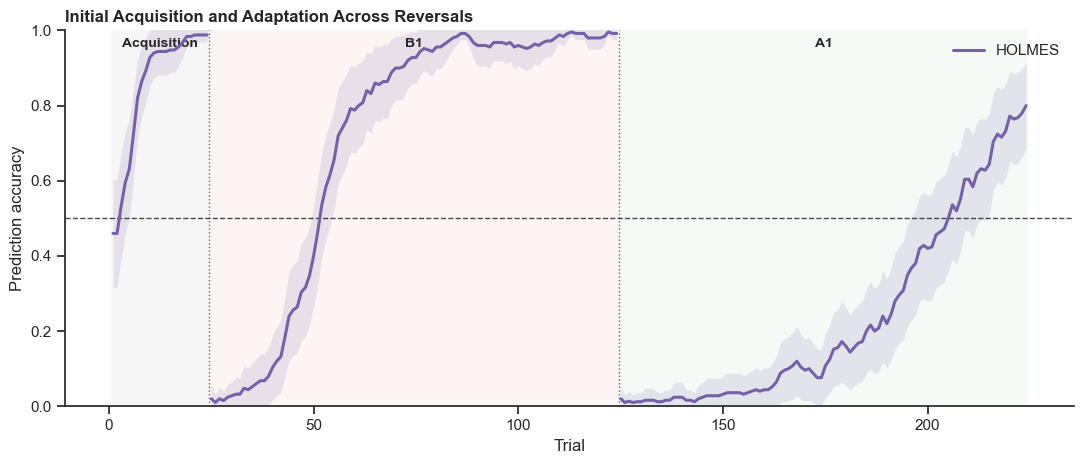

(      model  global_trial  phase_index phase_label phase_type contingency  \
 0      flat             1            0  Training A   training    original   
 1      flat             2            0  Training A   training    original   
 2      flat             3            0  Training A   training    original   
 3      flat             4            0  Training A   training    original   
 4      flat             5            0  Training A   training    original   
 ..      ...           ...          ...         ...        ...         ...   
 443  holmes           220            2          A1     switch    original   
 444  holmes           221            2          A1     switch    original   
 445  holmes           222            2          A1     switch    original   
 446  holmes           223            2          A1     switch    original   
 447  holmes           224            2          A1     switch    original   
 
      mean       std  count       sem     tcrit      ci95  plo

In [ ]:
plot_acquisition_and_switches(
    switch_df,
    metric="correct",
    smooth_window=5,
    show_flat=False,)

In [ ]:
first_switch = (
    switch_analysis["first_trial"]
    .groupby(
        ["phase_index", "phase_label", "contingency", "model"]
    )["signed_margin"]
    .agg(["mean", "std", "count"])
    .reset_index()
)

first_switch["sem"] = (
    first_switch["std"]
    / np.sqrt(first_switch["count"])
)

first_switch["ci95"] = (
    first_switch["sem"]
    * first_switch["count"].apply(
        lambda n: stats.t.ppf(0.975, n - 1)
    )
)

print(
    first_switch[
        [
            "phase_index",
            "phase_label",
            "contingency",
            "model",
            "mean",
            "ci95",
        ]
    ]
)

   phase_index phase_label contingency   model      mean      ci95
0            1          B1    reversed    flat -0.345514  0.189298
1            1          B1    reversed  holmes -0.566040  0.231052
2            2          A1    original    flat -0.205805  0.104702
3            2          A1    original  holmes -0.441109  0.077599
4            3          B2    reversed    flat -0.059256  0.033156
5            3          B2    reversed  holmes -0.084929  0.059966
6            4          A2    original    flat -0.084427  0.042119
7            4          A2    original  holmes -0.184256  0.028703


In [ ]:
print(
    switch_analysis["late_margin_summary"][
        [
            "phase_index",
            "phase_label",
            "contingency",
            "model",
            "mean",
            "ci95",
        ]
    ]
)

   phase_index phase_label contingency   model      mean      ci95
0            1          B1    reversed    flat  0.172304  0.095851
1            1          B1    reversed  holmes  0.391369  0.055788
2            2          A1    original    flat  0.038545  0.020423
3            2          A1    original  holmes  0.077543  0.027341
4            3          B2    reversed    flat  0.069308  0.037568
5            3          B2    reversed  holmes  0.145491  0.022779
6            4          A2    original    flat  0.020911  0.011720
7            4          A2    original  holmes  0.030789  0.014277


In [ ]:
# ============================================================
# REVERSAL-SPEED ANALYSIS
#
# Requires:
#   switch_df
#   switch_analysis = analyze_multi_reversal(...)
#
# Compares B1, A1, B2, A2 for:
#   1. first sustained positive round
#   2. area below zero
#   3. early recovery slope
# ============================================================

import numpy as np
import pandas as pd
from scipy import stats


# ============================================================
# 1. PER-SEED TIME TO SUSTAINED POSITIVE PREDICTION
# ============================================================

def sustained_positive_round_per_seed(
    round_seed,
    model="holmes",
    sustained_rounds=5,
    threshold=0.0,
):
    """
    For each seed x phase, find the first round at which
    signed margin stays above threshold for sustained_rounds
    consecutive rounds.

    Returns NaN if criterion is never reached.
    """

    df = round_seed[
        round_seed["model"] == model
    ].copy()

    rows = []

    for (
        seed,
        phase_index,
        phase_label,
        contingency
    ), g in df.groupby(
        [
            "seed",
            "phase_index",
            "phase_label",
            "contingency",
        ]
    ):

        g = g.sort_values("phase_round")

        vals = g["signed_margin"].to_numpy()
        rounds = g["phase_round"].to_numpy()

        first_cross = np.nan

        for i in range(
            len(vals) - sustained_rounds + 1
        ):

            window = vals[
                i:i + sustained_rounds
            ]

            if np.all(window > threshold):
                first_cross = int(rounds[i])
                break

        rows.append({
            "seed": seed,
            "phase_index": phase_index,
            "phase_label": phase_label,
            "contingency": contingency,
            "first_sustained_positive_round": first_cross,
        })

    return pd.DataFrame(rows)


holmes_speed = sustained_positive_round_per_seed(
    switch_analysis["round_seed"],
    model="holmes",
    sustained_rounds=5,
)

flat_speed = sustained_positive_round_per_seed(
    switch_analysis["round_seed"],
    model="flat",
    sustained_rounds=5,
)

display(holmes_speed.head())

,seed,phase_index,phase_label,contingency,first_sustained_positive_round
0,0,1,B1,reversed,21.0
1,0,2,A1,original,35.0
2,0,3,B2,reversed,18.0
3,0,4,A2,original,44.0
4,1,1,B1,reversed,15.0


In [ ]:
def summarize_speed(df):

    out = (
        df.groupby(
            [
                "phase_index",
                "phase_label",
                "contingency",
            ]
        )["first_sustained_positive_round"]
        .agg(
            mean="mean",
            median="median",
            std="std",
            count_nonmissing="count",
        )
        .reset_index()
    )

    out["sem"] = (
        out["std"]
        / np.sqrt(out["count_nonmissing"])
    )

    out["ci95"] = (
        1.96 * out["sem"]
    )

    return out


holmes_speed_summary = summarize_speed(
    holmes_speed
)

flat_speed_summary = summarize_speed(
    flat_speed
)

display(holmes_speed_summary)

,phase_index,phase_label,contingency,mean,median,std,count_nonmissing,sem,ci95
0,1,B1,reversed,17.550000,18.0,4.695743,20,1.050000,2.058000
1,2,A1,original,38.277778,38.0,5.038739,18,1.187642,2.327779
2,3,B2,reversed,20.800000,22.5,6.582273,20,1.471841,2.884808
3,4,A2,original,38.923077,42.0,6.448017,13,1.788358,3.505182


In [ ]:
# ============================================================
# 2. PAIRED SAVINGS TESTS
#
# B2 vs B1
# A2 vs A1
# ============================================================

def paired_phase_difference(
    speed_df,
    phase_a,
    phase_b,
):
    """
    Returns phase_b - phase_a.
    Negative values mean phase_b is faster.
    """

    a = (
        speed_df[
            speed_df["phase_label"] == phase_a
        ]
        .set_index("seed")[
            "first_sustained_positive_round"
        ]
    )

    b = (
        speed_df[
            speed_df["phase_label"] == phase_b
        ]
        .set_index("seed")[
            "first_sustained_positive_round"
        ]
    )

    common = (
        a.dropna().index
        .intersection(
            b.dropna().index
        )
    )

    diff = (
        b.loc[common]
        - a.loc[common]
    )

    if len(diff) > 1:

        t, p = stats.ttest_1samp(
            diff,
            popmean=0,
        )

    else:

        t = np.nan
        p = np.nan

    return {
        "phase_a": phase_a,
        "phase_b": phase_b,
        "mean_difference": diff.mean(),
        "median_difference": diff.median(),
        "n": len(diff),
        "t": t,
        "p": p,
    }


print(
    paired_phase_difference(
        holmes_speed,
        "B1",
        "B2",
    )
)

print(
    paired_phase_difference(
        holmes_speed,
        "A1",
        "A2",
    )
)

{'phase_a': 'B1', 'phase_b': 'B2', 'mean_difference': 3.25, 'median_difference': 4.0, 'n': 20, 't': 2.508706907728121, 'p': 0.02134479531022284}
{'phase_a': 'A1', 'phase_b': 'A2', 'mean_difference': 2.3076923076923075, 'median_difference': 3.0, 'n': 13, 't': 1.379158510305498, 'p': 0.19300814358041948}


In [ ]:
# ============================================================
# 3. AREA BELOW ZERO
#
# Measures cumulative maladaptive prediction during each phase.
# Smaller area on later reversals = faster/more efficient recovery.
# ============================================================

def compute_negative_area(
    round_seed,
    model="holmes",
):
    """
    For each seed x phase, integrate the amount by which
    signed margin is below zero.

    Since rounds are equally spaced:
        area = sum(max(0, -margin))

    Smaller = less cumulative negative transfer.
    """

    df = round_seed[
        round_seed["model"] == model
    ].copy()

    rows = []

    for (
        seed,
        phase_index,
        phase_label,
        contingency
    ), g in df.groupby(
        [
            "seed",
            "phase_index",
            "phase_label",
            "contingency",
        ]
    ):

        g = g.sort_values("phase_round")

        margin = g[
            "signed_margin"
        ].to_numpy()

        negative_area = np.sum(
            np.maximum(
                0,
                -margin,
            )
        )

        rows.append({
            "seed": seed,
            "phase_index": phase_index,
            "phase_label": phase_label,
            "contingency": contingency,
            "negative_area": negative_area,
        })

    return pd.DataFrame(rows)


holmes_neg_area = compute_negative_area(
    switch_analysis["round_seed"],
    model="holmes",
)

display(
    holmes_neg_area.groupby(
        "phase_label"
    )["negative_area"]
    .agg(["mean", "median", "std", "count"])
)

,mean,median,std,count
phase_label,,,,
A1,7.206665,7.397444,2.330443,20
A2,3.481610,3.894553,1.333038,20
B1,4.286024,4.688939,2.045595,20
B2,1.232532,1.356475,0.499064,20


In [ ]:
def paired_metric_difference(
    df,
    metric,
    phase_a,
    phase_b,
):

    a = (
        df[
            df["phase_label"] == phase_a
        ]
        .set_index("seed")[metric]
    )

    b = (
        df[
            df["phase_label"] == phase_b
        ]
        .set_index("seed")[metric]
    )

    common = (
        a.index.intersection(
            b.index
        )
    )

    diff = (
        b.loc[common]
        - a.loc[common]
    )

    t, p = stats.ttest_1samp(
        diff,
        popmean=0,
    )

    return pd.Series({
        "comparison":
            f"{phase_b} - {phase_a}",

        "mean_difference":
            diff.mean(),

        "ci95":
            1.96
            * diff.sem(),

        "t":
            t,

        "p":
            p,

        "n":
            len(diff),
    })


print(
    paired_metric_difference(
        holmes_neg_area,
        "negative_area",
        "B1",
        "B2",
    )
)

print(
    paired_metric_difference(
        holmes_neg_area,
        "negative_area",
        "A1",
        "A2",
    )
)

comparison          B2 - B1
mean_difference   -3.053491
ci95                0.78545
t                  -7.61964
p                       0.0
n                        20
dtype: object
comparison           A2 - A1
mean_difference    -3.725055
ci95                0.607397
t                 -12.020332
p                        0.0
n                         20
dtype: object


In [ ]:
# ============================================================
# 4. EARLY RECOVERY SLOPE
#
# Fit signed margin ~ phase_round over the first N rounds.
# Larger positive slope = faster initial adaptation.
# ============================================================

def compute_early_recovery_slopes(
    round_seed,
    model="holmes",
    first_n_rounds=15,
):
    """
    Per seed x phase linear slope over early rounds.
    """

    df = round_seed[
        round_seed["model"] == model
    ].copy()

    rows = []

    for (
        seed,
        phase_index,
        phase_label,
        contingency
    ), g in df.groupby(
        [
            "seed",
            "phase_index",
            "phase_label",
            "contingency",
        ]
    ):

        g = (
            g[
                g["phase_round"]
                <= first_n_rounds
            ]
            .sort_values(
                "phase_round"
            )
        )

        if len(g) < 3:
            slope = np.nan

        else:

            slope = np.polyfit(
                g["phase_round"],
                g["signed_margin"],
                1,
            )[0]

        rows.append({
            "seed": seed,
            "phase_index": phase_index,
            "phase_label": phase_label,
            "contingency": contingency,
            "early_slope": slope,
        })

    return pd.DataFrame(rows)


holmes_slopes = (
    compute_early_recovery_slopes(
        switch_analysis["round_seed"],
        model="holmes",
        first_n_rounds=15,
    )
)

display(
    holmes_slopes.groupby(
        "phase_label"
    )["early_slope"]
    .agg(["mean", "std", "count"])
)


print(
    paired_metric_difference(
        holmes_slopes,
        "early_slope",
        "B1",
        "B2",
    )
)

print(
    paired_metric_difference(
        holmes_slopes,
        "early_slope",
        "A1",
        "A2",
    )
)



,mean,std,count
phase_label,,,
A1,0.013133,0.007882,20
A2,0.006017,0.003667,20
B1,0.043710,0.018440,20
B2,0.005299,0.004740,20


comparison          B2 - B1
mean_difference   -0.038411
ci95               0.007923
t                 -9.501788
p                       0.0
n                        20
dtype: object
comparison          A2 - A1
mean_difference   -0.007116
ci95               0.003255
t                 -4.284845
p                    0.0004
n                        20
dtype: object


In [ ]:
# ============================================================
# 5. COMPACT SAVINGS SUMMARY TABLE
# ============================================================

speed_summary = (
    holmes_speed
    .groupby("phase_label")
    ["first_sustained_positive_round"]
    .agg(
        recovery_round_mean="mean",
        recovery_round_median="median",
    )
)

area_summary = (
    holmes_neg_area
    .groupby("phase_label")
    ["negative_area"]
    .mean()
    .rename("negative_area_mean")
)

slope_summary = (
    holmes_slopes
    .groupby("phase_label")
    ["early_slope"]
    .mean()
    .rename("early_slope_mean")
)

savings_summary = (
    speed_summary
    .join(area_summary)
    .join(slope_summary)
    .reset_index()
)

print(savings_summary)

  phase_label  recovery_round_mean  recovery_round_median  negative_area_mean  \
0          A1            38.277778                   38.0            7.206665   
1          A2            38.923077                   42.0            3.481610   
2          B1            17.550000                   18.0            4.286024   
3          B2            20.800000                   22.5            1.232532   

   early_slope_mean  
0          0.013133  
1          0.006017  
2          0.043710  
3          0.005299  


# context task

0/20 (seed=0)
10/20 (seed=10)


,phase_index,phase_label,rule_type,model,mean,std,count,sem,tcrit,ci95
0,0,A1,shape,flat,-0.031259,0.312032,20,0.069772,2.093024,0.146036
1,0,A1,shape,holmes,-0.022141,0.165496,20,0.037006,2.093024,0.077454
2,1,B1,color,flat,-0.054187,0.102831,20,0.022994,2.093024,0.048126
3,1,B1,color,holmes,-0.085764,0.237907,20,0.053198,2.093024,0.111344
4,2,A2,shape,flat,0.018080,0.047901,20,0.010711,2.093024,0.022418
5,2,A2,shape,holmes,0.027855,0.102481,20,0.022916,2.093024,0.047963
6,3,B2,color,flat,-0.029671,0.062909,20,0.014067,2.093024,0.029442
7,3,B2,color,holmes,-0.008608,0.113312,20,0.025337,2.093024,0.053032


,phase_index,phase_label,rule_type,model,mean,std,count,sem,tcrit,ci95
0,0,A1,shape,flat,0.044908,0.066303,20,0.014826,2.093024,0.031031
1,0,A1,shape,holmes,0.175073,0.104483,20,0.023363,2.093024,0.048900
2,1,B1,color,flat,-0.016677,0.028367,20,0.006343,2.093024,0.013276
3,1,B1,color,holmes,-0.055194,0.040147,20,0.008977,2.093024,0.018789
4,2,A2,shape,flat,0.015095,0.025777,20,0.005764,2.093024,0.012064
5,2,A2,shape,holmes,0.038655,0.034589,20,0.007734,2.093024,0.016188
6,3,B2,color,flat,-0.004612,0.011781,20,0.002634,2.093024,0.005514
7,3,B2,color,holmes,-0.017748,0.022492,20,0.005029,2.093024,0.010526


,mean,median,std,count
phase_label,,,,
A1,0.271760,0.200580,0.297569,20
A2,0.615784,0.574062,0.273061,20
B1,4.077874,4.060883,2.204683,20
B2,1.658808,1.474175,0.812159,20


{'comparison': 'A2 - A1', 'mean_difference': 0.3440243501115177, 'ci95_low': 0.16018652007286047, 'ci95_high': 0.5278621801501749, 'n': 20}
{'comparison': 'B2 - B1', 'mean_difference': -2.419066665382469, 'ci95_low': -3.1796854794442084, 'ci95_high': -1.6584478513207297, 'n': 20}


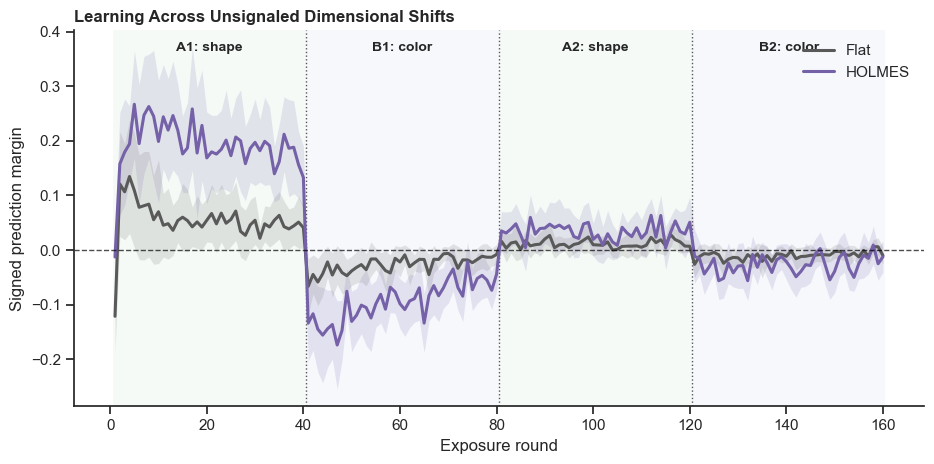

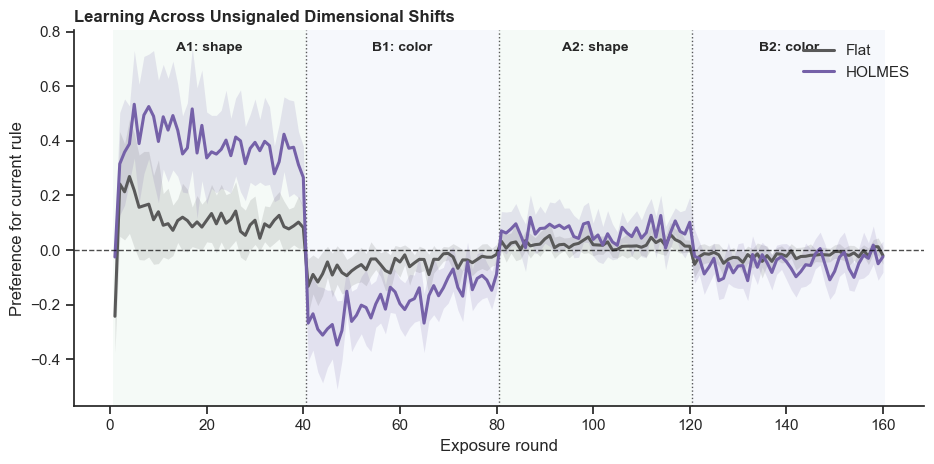

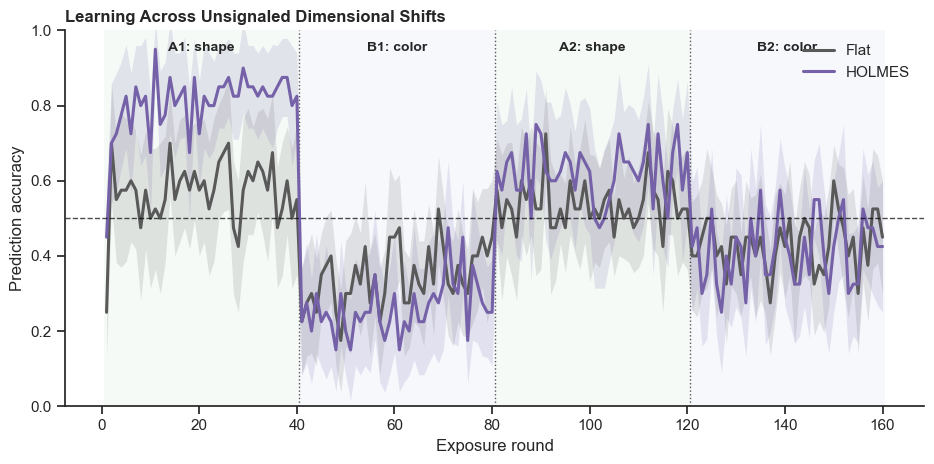

In [137]:
# ============================================================
# DIMENSIONAL-SHIFT TASK
#
# A1: SHAPE predicts reward
# B1: COLOR predicts reward
# A2: SHAPE predicts reward again
# B2: COLOR predicts reward again
#
# No explicit context cue.
#
# The same 4 shape x color stimuli occur in every phase.
# Only which DIMENSION is relevant changes.
#
# Evaluation uses the actual online rEst predictions from
# Flat and HOLMES -- no post-hoc level decoder.
#
# Requires:
#     import ablation_rule_task as rule_tps
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from dataclasses import dataclass, asdict
from scipy import stats


# ============================================================
# CONFIGURATION
# ============================================================

@dataclass
class DimensionalShiftConfig:

    # Number of complete presentations of the 4 stimuli
    # in each phase.
    rounds_per_phase: int = 40

    # Sequence of relevant dimensions.
    phase_sequence: tuple = (
        "shape",
        "color",
        "shape",
        "color",
    )

    # Balanced feature representation by default.
    # Each shape/color is represented one-hot.
    n_shape_copies: int = 1
    n_color_copies: int = 1

    n_nuisance_features: int = 0

    # Optional outcome stochasticity.
    outcome_noise: float = 0.0

    # Which value within each dimension is rewarded.
    #
    # None -> randomly choose independently for each seed.
    rewarded_shape: int | None = None
    rewarded_color: int | None = None


# ============================================================
# TASK GENERATOR
# ============================================================

def generate_dimensional_shift_task(
    seed,
    cfg: DimensionalShiftConfig,
):
    """
    Generate an unsignaled dimensional-shift task.

    Two binary dimensions:
        shape: 0 / 1
        color: 0 / 1

    The deterministic rules are:

        shape rule:
            reward iff shape == rewarded_shape

        color rule:
            reward iff color == rewarded_color

    The same four shape x color combinations appear in every
    round and every phase.

    Crucially, two of the four stimuli are diagnostic:
    shape-rule and color-rule predictions disagree.

    Returns
    -------
    F
        Feature matrix [features x trials], last row = outcome.

    meta
        Trial metadata.

    feedback_mask
        Full feedback after every trial.
    """

    rng = np.random.default_rng(seed)

    n_shapes = 2
    n_colors = 2

    # --------------------------------------------------------
    # Choose rewarded values
    # --------------------------------------------------------

    if cfg.rewarded_shape is None:
        rewarded_shape = int(
            rng.integers(0, 2)
        )
    else:
        rewarded_shape = int(
            cfg.rewarded_shape
        )

    if cfg.rewarded_color is None:
        rewarded_color = int(
            rng.integers(0, 2)
        )
    else:
        rewarded_color = int(
            cfg.rewarded_color
        )

    # --------------------------------------------------------
    # Feature dimensions
    #
    # shape one-hot:
    #   [shape0, shape1]
    #
    # color one-hot:
    #   [color0, color1]
    #
    # repeated n_*_copies times if desired.
    # --------------------------------------------------------

    n_shape_feats = (
        cfg.n_shape_copies
        * n_shapes
    )

    n_color_feats = (
        cfg.n_color_copies
        * n_colors
    )

    n_nonoutcome = (
        n_shape_feats
        + n_color_feats
        + cfg.n_nuisance_features
    )

    outcome_idx = n_nonoutcome


    # --------------------------------------------------------
    # Optional nuisance features fixed by stimulus identity
    # --------------------------------------------------------

    nuisance_by_stimulus = {}

    if cfg.n_nuisance_features > 0:

        for shape in [0, 1]:
            for color in [0, 1]:

                nuisance_by_stimulus[
                    (shape, color)
                ] = rng.integers(
                    0,
                    2,
                    size=cfg.n_nuisance_features,
                    dtype=int,
                )


    # --------------------------------------------------------
    # Build observation vector
    # --------------------------------------------------------

    def make_features(
        shape,
        color,
    ):

        x = np.zeros(
            n_nonoutcome,
            dtype=int,
        )

        # Shape copies
        for copy in range(
            cfg.n_shape_copies
        ):

            x[
                copy * n_shapes
                + shape
            ] = 1

        # Color copies
        color_start = n_shape_feats

        for copy in range(
            cfg.n_color_copies
        ):

            x[
                color_start
                + copy * n_colors
                + color
            ] = 1

        if cfg.n_nuisance_features > 0:

            x[
                n_shape_feats
                + n_color_feats:
            ] = nuisance_by_stimulus[
                (shape, color)
            ]

        return x


    # --------------------------------------------------------
    # Rule functions
    # --------------------------------------------------------

    def shape_rule(shape):
        return int(
            shape == rewarded_shape
        )

    def color_rule(color):
        return int(
            color == rewarded_color
        )


    # ========================================================
    # GENERATE PHASES
    # ========================================================

    trials = []

    global_trial = 0

    shape_phase_count = 0
    color_phase_count = 0


    for phase_index, rule_type in enumerate(
        cfg.phase_sequence
    ):

        if rule_type == "shape":

            shape_phase_count += 1

            phase_label = (
                f"A{shape_phase_count}"
            )

        elif rule_type == "color":

            color_phase_count += 1

            phase_label = (
                f"B{color_phase_count}"
            )

        else:

            raise ValueError(
                "phase_sequence entries must be "
                "'shape' or 'color'"
            )


        previous_rule = (
            None
            if phase_index == 0
            else cfg.phase_sequence[
                phase_index - 1
            ]
        )

        phase_trial = 0

        first_diagnostic_seen = False


        # ----------------------------------------------------
        # Each round contains all four stimuli exactly once.
        # ----------------------------------------------------

        for phase_round in range(
            1,
            cfg.rounds_per_phase + 1,
        ):

            stimuli = [
                (shape, color)
                for shape in [0, 1]
                for color in [0, 1]
            ]

            rng.shuffle(
                stimuli
            )


            for shape, color in stimuli:

                global_trial += 1
                phase_trial += 1


                shape_reward = (
                    shape_rule(shape)
                )

                color_reward = (
                    color_rule(color)
                )


                # --------------------------------------------
                # Diagnostic trial:
                #
                # The two dimensional rules predict
                # opposite outcomes.
                # --------------------------------------------

                diagnostic = (
                    shape_reward
                    != color_reward
                )


                if rule_type == "shape":

                    deterministic_reward = (
                        shape_reward
                    )

                else:

                    deterministic_reward = (
                        color_reward
                    )


                reward = (
                    deterministic_reward
                )


                # Optional reward noise
                if (
                    cfg.outcome_noise > 0
                    and rng.random()
                    < cfg.outcome_noise
                ):

                    reward = (
                        1 - reward
                    )


                is_first_diagnostic = (
                    diagnostic
                    and not first_diagnostic_seen
                )

                if diagnostic:
                    first_diagnostic_seen = True


                trials.append({

                    "phase_index":
                        phase_index,

                    "phase_label":
                        phase_label,

                    "rule_type":
                        rule_type,

                    "previous_rule":
                        previous_rule,

                    "switch_direction":
                        (
                            "acquisition"
                            if phase_index == 0
                            else (
                                f"{previous_rule}"
                                f"→{rule_type}"
                            )
                        ),

                    "global_trial":
                        global_trial,

                    "phase_trial":
                        phase_trial,

                    "phase_round":
                        phase_round,

                    "shape":
                        shape,

                    "color":
                        color,

                    # Rule-specific deterministic outcomes
                    "shape_rule_reward":
                        shape_reward,

                    "color_rule_reward":
                        color_reward,

                    # Is this stimulus informative about
                    # which rule is active?
                    "diagnostic":
                        diagnostic,

                    "is_first_trial_in_phase":
                        phase_trial == 1,

                    "is_first_diagnostic_in_phase":
                        is_first_diagnostic,

                    # Actual outcome
                    "reward":
                        reward,

                    "deterministic_reward":
                        deterministic_reward,

                    "features":
                        make_features(
                            shape,
                            color,
                        ),
                })


    # ========================================================
    # FEATURE MATRIX
    # ========================================================

    F = np.zeros(
        (
            n_nonoutcome + 1,
            len(trials),
        ),
        dtype=int,
    )


    for t, tr in enumerate(trials):

        F[
            :n_nonoutcome,
            t
        ] = tr["features"]

        F[
            outcome_idx,
            t
        ] = tr["reward"]


    feedback_mask = (
        np.ones_like(
            F,
            dtype=bool,
        )
    )


    meta = {

        "task_type":
            "dimensional_shift",

        "seed":
            seed,

        "config":
            asdict(cfg),

        "rewarded_shape":
            rewarded_shape,

        "rewarded_color":
            rewarded_color,

        "outcome_idx":
            outcome_idx,

        "n_trials":
            len(trials),

        "n_nonoutcome":
            n_nonoutcome,

        "trials": [
            {
                k: v
                for k, v
                in tr.items()
                if k != "features"
            }
            for tr in trials
        ],
    }


    return (
        F,
        meta,
        feedback_mask,
    )


# ============================================================
# RUN ONE SEED
# ============================================================

def run_dimensional_shift_seed(
    seed,
    cfg,
    *,
    n_particles=50,
    alpha=0.40,
    omega=0.05,
    hier_stickiness=None,
    flat_stickiness=0.0,
    max_depth=20,
    max_children=20,
    length_normalize=False,
    tau=1.0,
):
    """
    Run Flat and HOLMES using their ACTUAL online outcome
    predictions.

    Returns
    -------
    Long trial-level dataframe.
    """

    if hier_stickiness is None:
        hier_stickiness = omega


    F, meta, fb = (
        generate_dimensional_shift_task(
            seed,
            cfg,
        )
    )

    oi = int(
        meta["outcome_idx"]
    )

    trials = meta["trials"]


    # ========================================================
    # FLAT MODEL
    # ========================================================

    (
        p_flat,
        _,
        r_flat,
        _,
    ) = rule_tps.one_layer_inference_loop(

        nTrials=
            F.shape[1],

        nParticles=
            n_particles,

        nFeatures=
            F.shape[0],

        regime=
            omega,

        alpha=
            alpha,

        f=
            F,

        outcome_idx_per_trial=
            np.full(
                F.shape[1],
                oi,
                dtype=int,
            ),

        feedback_mask=
            fb[oi, :],

        random_seed=
            seed,

        length_normalize=
            length_normalize,

        tau=
            tau,

        stickiness=
            flat_stickiness,
    )


    # ========================================================
    # HOLMES
    # ========================================================

    hier_out = (
        rule_tps.full_hier_inference_loop(

            nTrials=
                F.shape[1],

            nParticles=
                n_particles,

            nFeatures=
                F.shape[0],

            alpha=
                alpha,

            omega=
                omega,

            f=
                F,

            max_depth=
                max_depth,

            max_children=
                max_children,

            outcome_idx=
                oi,

            feedback_mask=
                fb,

            random_seed=
                seed,

            length_normalize=
                length_normalize,

            tau=
                tau,

            stickiness=
                hier_stickiness,

            use_stopping=
                True,
        )
    )

    r_holmes = hier_out[2]


    # ========================================================
    # LONG TRIAL DATAFRAME
    # ========================================================

    rows = []


    for model, pred in [

        ("flat", r_flat),

        ("holmes", r_holmes),

    ]:

        for t, tr in enumerate(
            trials
        ):

            y = int(
                tr["reward"]
            )

            p = float(
                pred[t]
            )

            predicted_reward = int(
                p > 0.5
            )

            correct = float(
                predicted_reward == y
            )


            # -----------------------------------------------
            # Signed distance from current correct outcome.
            #
            # +1 = maximally correct
            #  0 = decision boundary
            # -1 = maximally wrong
            # -----------------------------------------------

            signed_margin = (
                (2 * y - 1)
                * (2 * p - 1)
            )


            # -----------------------------------------------
            # Does the prediction favor the SHAPE rule?
            # -----------------------------------------------

            shape_rule_margin = (
                (
                    2
                    * int(
                        tr[
                            "shape_rule_reward"
                        ]
                    )
                    - 1
                )
                * (2 * p - 1)
            )


            # -----------------------------------------------
            # Does the prediction favor the COLOR rule?
            # -----------------------------------------------

            color_rule_margin = (
                (
                    2
                    * int(
                        tr[
                            "color_rule_reward"
                        ]
                    )
                    - 1
                )
                * (2 * p - 1)
            )


            # -----------------------------------------------
            # Rule preference
            #
            # Positive = favors currently relevant rule
            # over the irrelevant dimensional rule.
            #
            # On diagnostic trials the two are exact
            # opposites, so this is especially interpretable.
            # -----------------------------------------------

            if tr["rule_type"] == "shape":

                relevant_margin = (
                    shape_rule_margin
                )

                irrelevant_margin = (
                    color_rule_margin
                )

            else:

                relevant_margin = (
                    color_rule_margin
                )

                irrelevant_margin = (
                    shape_rule_margin
                )


            rule_preference = (
                relevant_margin
                - irrelevant_margin
            )


            rows.append({

                "seed":
                    seed,

                "model":
                    model,

                "phase_index":
                    int(
                        tr[
                            "phase_index"
                        ]
                    ),

                "phase_label":
                    tr[
                        "phase_label"
                    ],

                "rule_type":
                    tr[
                        "rule_type"
                    ],

                "previous_rule":
                    tr[
                        "previous_rule"
                    ],

                "switch_direction":
                    tr[
                        "switch_direction"
                    ],

                "global_trial":
                    int(
                        tr[
                            "global_trial"
                        ]
                    ),

                "phase_trial":
                    int(
                        tr[
                            "phase_trial"
                        ]
                    ),

                "phase_round":
                    int(
                        tr[
                            "phase_round"
                        ]
                    ),

                "shape":
                    int(
                        tr[
                            "shape"
                        ]
                    ),

                "color":
                    int(
                        tr[
                            "color"
                        ]
                    ),

                "diagnostic":
                    bool(
                        tr[
                            "diagnostic"
                        ]
                    ),

                "is_first_trial_in_phase":
                    bool(
                        tr[
                            "is_first_trial_in_phase"
                        ]
                    ),

                "is_first_diagnostic_in_phase":
                    bool(
                        tr[
                            "is_first_diagnostic_in_phase"
                        ]
                    ),

                "true_reward":
                    y,

                "p_reward":
                    p,

                "predicted_reward":
                    predicted_reward,

                "correct":
                    correct,

                "signed_margin":
                    signed_margin,

                "shape_rule_margin":
                    shape_rule_margin,

                "color_rule_margin":
                    color_rule_margin,

                "relevant_rule_margin":
                    relevant_margin,

                "irrelevant_rule_margin":
                    irrelevant_margin,

                "rule_preference":
                    rule_preference,
            })


    return pd.DataFrame(
        rows
    )


# ============================================================
# RUN MANY SEEDS
# ============================================================

def run_dimensional_shift_experiment(
    seeds,
    cfg,
    *,
    n_particles=50,
    alpha=0.40,
    omega=0.05,
    hier_stickiness=None,
    flat_stickiness=0.0,
    max_depth=20,
    max_children=20,
    length_normalize=False,
    tau=1.0,
):
    """
    Run dimensional-shift experiment across seeds.
    """

    seeds = list(seeds)

    all_rows = []


    for i, seed in enumerate(
        seeds
    ):

        if i % 10 == 0:

            print(
                f"{i}/{len(seeds)} "
                f"(seed={seed})"
            )


        df_seed = (
            run_dimensional_shift_seed(

                seed=seed,

                cfg=cfg,

                n_particles=
                    n_particles,

                alpha=
                    alpha,

                omega=
                    omega,

                hier_stickiness=
                    hier_stickiness,

                flat_stickiness=
                    flat_stickiness,

                max_depth=
                    max_depth,

                max_children=
                    max_children,

                length_normalize=
                    length_normalize,

                tau=
                    tau,
            )
        )


        all_rows.append(
            df_seed
        )


    return pd.concat(
        all_rows,
        ignore_index=True,
    )


# ============================================================
# CI HELPER
# ============================================================

def dimensional_summary_ci(
    df,
    group_cols,
    value_col,
):
    """
    Mean + t-based 95% CI.
    """

    out = (
        df
        .groupby(
            group_cols
        )[value_col]
        .agg(
            [
                "mean",
                "std",
                "count",
            ]
        )
        .reset_index()
    )


    out["sem"] = (
        out["std"]
        / np.sqrt(
            out["count"]
        )
    )


    out["tcrit"] = (
        out["count"]
        .apply(
            lambda n:
                stats.t.ppf(
                    .975,
                    n - 1,
                )
                if n > 1
                else np.nan
        )
    )


    out["ci95"] = (
        out["sem"]
        * out["tcrit"]
    )


    return out


# ============================================================
# ANALYSIS
# ============================================================

def analyze_dimensional_shift(
    df,
    diagnostic_only=True,
    late_rounds=10,
):
    """
    Primary analysis of dimensional switching.

    By default, analyze only DIAGNOSTIC trials, on which
    shape and color rules make opposite predictions.
    """

    if diagnostic_only:

        use = df[
            df["diagnostic"]
        ].copy()

    else:

        use = df.copy()


    # ========================================================
    # ROUND-LEVEL DATA
    #
    # Each round contains exactly two diagnostic trials.
    # ========================================================

    round_seed = (
        use
        .groupby(
            [
                "seed",
                "model",
                "phase_index",
                "phase_label",
                "rule_type",
                "phase_round",
            ],
            as_index=False,
        )
        .agg(

            signed_margin=(
                "signed_margin",
                "mean",
            ),

            accuracy=(
                "correct",
                "mean",
            ),

            rule_preference=(
                "rule_preference",
                "mean",
            ),
        )
    )


    margin_summary = (
        dimensional_summary_ci(
            round_seed,
            [
                "model",
                "phase_index",
                "phase_label",
                "rule_type",
                "phase_round",
            ],
            "signed_margin",
        )
    )


    rule_summary = (
        dimensional_summary_ci(
            round_seed,
            [
                "model",
                "phase_index",
                "phase_label",
                "rule_type",
                "phase_round",
            ],
            "rule_preference",
        )
    )


    accuracy_summary = (
        dimensional_summary_ci(
            round_seed,
            [
                "model",
                "phase_index",
                "phase_label",
                "rule_type",
                "phase_round",
            ],
            "accuracy",
        )
    )


    # ========================================================
    # FIRST DIAGNOSTIC TRIAL OF EACH PHASE
    # ========================================================

    first_diag = (
        use[
            use[
                "is_first_diagnostic_in_phase"
            ]
        ]
        .copy()
    )


    first_diag_summary = (
        dimensional_summary_ci(
            first_diag,
            [
                "phase_index",
                "phase_label",
                "rule_type",
                "model",
            ],
            "signed_margin",
        )
    )


    # ========================================================
    # LATE-PHASE PERFORMANCE
    # ========================================================

    max_rounds = (
        round_seed
        .groupby(
            "phase_index"
        )[
            "phase_round"
        ]
        .max()
        .to_dict()
    )


    late_parts = []


    for phase_index, max_round in (
        max_rounds.items()
    ):

        late_start = max(
            1,
            max_round
            - late_rounds
            + 1,
        )


        part = (
            round_seed[
                (
                    round_seed[
                        "phase_index"
                    ]
                    == phase_index
                )
                &
                (
                    round_seed[
                        "phase_round"
                    ]
                    >= late_start
                )
            ]
            .groupby(
                [
                    "seed",
                    "model",
                    "phase_index",
                    "phase_label",
                    "rule_type",
                ],
                as_index=False,
            )
            .agg(

                late_margin=(
                    "signed_margin",
                    "mean",
                ),

                late_accuracy=(
                    "accuracy",
                    "mean",
                ),

                late_rule_preference=(
                    "rule_preference",
                    "mean",
                ),
            )
        )


        late_parts.append(
            part
        )


    late_seed = pd.concat(
        late_parts,
        ignore_index=True,
    )


    late_summary = (
        dimensional_summary_ci(
            late_seed,
            [
                "phase_index",
                "phase_label",
                "rule_type",
                "model",
            ],
            "late_margin",
        )
    )


    return {

        "round_seed":
            round_seed,

        "margin_summary":
            margin_summary,

        "rule_summary":
            rule_summary,

        "accuracy_summary":
            accuracy_summary,

        "first_diagnostic":
            first_diag,

        "first_diagnostic_summary":
            first_diag_summary,

        "late_seed":
            late_seed,

        "late_summary":
            late_summary,
    }


# ============================================================
# SAVINGS / RELEARNING ANALYSIS
# ============================================================

def dimensional_negative_area(
    analysis,
    model="holmes",
):
    """
    Cumulative incorrect-direction prediction within each phase.

    Lower on A2 than A1, or B2 than B1, indicates less
    cumulative cost when that dimensional rule returns.
    """

    d = (
        analysis[
            "round_seed"
        ]
    )

    d = d[
        d["model"] == model
    ]


    rows = []


    for (
        seed,
        phase_index,
        phase_label,
        rule_type
    ), g in d.groupby(
        [
            "seed",
            "phase_index",
            "phase_label",
            "rule_type",
        ]
    ):

        negative_area = np.sum(
            np.maximum(
                0,
                -g[
                    "signed_margin"
                ].to_numpy(),
            )
        )


        rows.append({

            "seed":
                seed,

            "phase_index":
                phase_index,

            "phase_label":
                phase_label,

            "rule_type":
                rule_type,

            "negative_area":
                negative_area,
        })


    return pd.DataFrame(
        rows
    )


def paired_dimensional_savings(
    area_df,
    first_phase,
    repeat_phase,
):
    """
    repeat - first.

    Negative difference = less cumulative error on recurrence.
    """

    a = (
        area_df[
            area_df["phase_label"]
            == first_phase
        ]
        .set_index(
            "seed"
        )[
            "negative_area"
        ]
    )

    b = (
        area_df[
            area_df["phase_label"]
            == repeat_phase
        ]
        .set_index(
            "seed"
        )[
            "negative_area"
        ]
    )


    common = (
        a.index.intersection(
            b.index
        )
    )


    d = (
        b.loc[common]
        - a.loc[common]
    )


    mean = float(
        d.mean()
    )

    sem = float(
        d.sem()
    )


    ci = (
        stats.t.ppf(
            .975,
            len(d) - 1,
        )
        * sem
        if len(d) > 1
        else np.nan
    )


    return {

        "comparison":
            f"{repeat_phase} - {first_phase}",

        "mean_difference":
            mean,

        "ci95_low":
            mean - ci,

        "ci95_high":
            mean + ci,

        "n":
            len(d),
    }


# ============================================================
# PLOT:
# DIAGNOSTIC-TRIAL LEARNING ACROSS DIMENSION SHIFTS
# ============================================================

def plot_dimensional_shift(
    analysis,
    metric="signed_margin",
    show_flat=True,
    figsize=(9.5, 4.8),
):
    """
    Plot round-level performance on diagnostic trials.

    metric:
        "signed_margin"
        "accuracy"
        "rule_preference"
    """

    if metric == "signed_margin":

        summary = (
            analysis[
                "margin_summary"
            ]
        )

        ylabel = (
            "Signed prediction margin"
        )

        reference = 0

    elif metric == "accuracy":

        summary = (
            analysis[
                "accuracy_summary"
            ]
        )

        ylabel = (
            "Prediction accuracy"
        )

        reference = 0.5

    elif metric == "rule_preference":

        summary = (
            analysis[
                "rule_summary"
            ]
        )

        ylabel = (
            "Preference for current rule"
        )

        reference = 0

    else:

        raise ValueError(
            "metric must be "
            "'signed_margin', 'accuracy', "
            "or 'rule_preference'"
        )


    # --------------------------------------------------------
    # Continuous x-axis in rounds
    # --------------------------------------------------------

    phase_info = (
        summary[
            [
                "phase_index",
                "phase_label",
                "rule_type",
                "phase_round",
            ]
        ]
        .drop_duplicates()
    )


    max_rounds = (
        phase_info
        .groupby(
            "phase_index"
        )[
            "phase_round"
        ]
        .max()
        .sort_index()
    )


    offsets = {}

    offset = 0

    for phase_index, nrounds in (
        max_rounds.items()
    ):

        offsets[
            phase_index
        ] = offset

        offset += nrounds


    plot_df = (
        summary.copy()
    )


    plot_df[
        "continuous_round"
    ] = (
        plot_df.apply(
            lambda r:
                offsets[
                    r[
                        "phase_index"
                    ]
                ]
                + r[
                    "phase_round"
                ],
            axis=1,
        )
    )


    # --------------------------------------------------------
    # Draw
    # --------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=figsize
    )


    phase_ranges = (
        plot_df
        .groupby(
            [
                "phase_index",
                "phase_label",
                "rule_type",
            ],
            as_index=False,
        )
        .agg(
            xmin=(
                "continuous_round",
                "min",
            ),
            xmax=(
                "continuous_round",
                "max",
            ),
        )
    )


    for _, ph in phase_ranges.iterrows():

        # shape vs color background
        facecolor = (
            "#E5F2EA"
            if ph[
                "rule_type"
            ] == "shape"
            else "#E7ECF7"
        )


        ax.axvspan(
            ph["xmin"] - .5,
            ph["xmax"] + .5,
            color=facecolor,
            alpha=.35,
            linewidth=0,
        )


        ax.text(
            (
                ph["xmin"]
                + ph["xmax"]
            ) / 2,
            .97,
            (
                f"{ph['phase_label']}: "
                f"{ph['rule_type']}"
            ),
            transform=
                ax.get_xaxis_transform(),
            ha="center",
            va="top",
            fontsize=10,
            fontweight="bold",
        )


    # Switch lines
    starts = (
        phase_ranges[
            "xmin"
        ]
        .sort_values()
        .to_numpy()
    )


    for start in starts[1:]:

        ax.axvline(
            start - .5,
            color="black",
            linestyle=":",
            linewidth=1,
            alpha=.65,
        )


    models = (
        ["flat", "holmes"]
        if show_flat
        else ["holmes"]
    )


    colors = {
        "flat": "#595959",
        "holmes": "#7561A8",
    }


    labels = {
        "flat": "Flat",
        "holmes": "HOLMES",
    }


    for model in models:

        g = (
            plot_df[
                plot_df["model"]
                == model
            ]
            .sort_values(
                "continuous_round"
            )
        )


        ax.plot(
            g[
                "continuous_round"
            ],
            g["mean"],
            linewidth=2.2,
            color=
                colors[model],
            label=
                labels[model],
        )


        ax.fill_between(
            g[
                "continuous_round"
            ].to_numpy(),

            (
                g["mean"]
                - g["ci95"]
            ).to_numpy(),

            (
                g["mean"]
                + g["ci95"]
            ).to_numpy(),

            color=
                colors[model],

            alpha=.15,

            linewidth=0,
        )


    ax.axhline(
        reference,
        color="black",
        linestyle="--",
        linewidth=1,
        alpha=.7,
    )


    if metric == "accuracy":

        ax.set_ylim(
            0,
            1,
        )


    ax.set_xlabel(
        "Exposure round"
    )

    ax.set_ylabel(
        ylabel
    )

    ax.set_title(
        "Learning Across Unsignaled Dimensional Shifts",
        loc="left",
        fontweight="bold",
    )

    ax.legend(
        frameon=False
    )

    ax.spines[
        "top"
    ].set_visible(
        False
    )

    ax.spines[
        "right"
    ].set_visible(
        False
    )

    fig.tight_layout()

    plt.show()


# ============================================================
# EXAMPLE / SMOKE TEST
# ============================================================

DIM_CFG = DimensionalShiftConfig(

    rounds_per_phase=40,

    phase_sequence=(
        "shape",
        "color",
        "shape",
        "color",
    ),

    # Balanced feature representation:
    n_shape_copies=1,
    n_color_copies=1,

    outcome_noise=0.0,
)


dim_df = (
    run_dimensional_shift_experiment(

        seeds=range(20),

        cfg=DIM_CFG,

        # Keep small for initial debugging.
        n_particles=10,

        alpha=0.40,

        omega=0.05,

        hier_stickiness=0.0,

        flat_stickiness=0.0,

        max_depth=5,

        max_children=5,

        length_normalize=True,

        tau=1.0,
    )
)


dim_analysis = (
    analyze_dimensional_shift(

        dim_df,

        # Strong recommendation:
        # only rule-diagnostic stimuli.
        diagnostic_only=True,

        late_rounds=10,
    )
)


# ============================================================
# INSPECT
# ============================================================

display(
    dim_analysis[
        "first_diagnostic_summary"
    ]
)

display(
    dim_analysis[
        "late_summary"
    ]
)


# ============================================================
# SAVINGS
# ============================================================

holmes_area = (
    dimensional_negative_area(
        dim_analysis,
        model="holmes",
    )
)


display(
    holmes_area
    .groupby(
        "phase_label"
    )[
        "negative_area"
    ]
    .agg(
        [
            "mean",
            "median",
            "std",
            "count",
        ]
    )
)


print(
    paired_dimensional_savings(
        holmes_area,
        "A1",
        "A2",
    )
)

print(
    paired_dimensional_savings(
        holmes_area,
        "B1",
        "B2",
    )
)


# ============================================================
# PLOTS
# ============================================================

# Most direct: is the model predicting correctly?
plot_dimensional_shift(
    dim_analysis,
    metric="signed_margin",
    show_flat=True,
)


# More mechanistic:
# positive = prediction favors whichever dimension is
# currently relevant.
plot_dimensional_shift(
    dim_analysis,
    metric="rule_preference",
    show_flat=True,
)


# Optional thresholded version
plot_dimensional_shift(
    dim_analysis,
    metric="accuracy",
    show_flat=True,
)